In [1]:

import sys
import importlib.util
from importlib.metadata import version, PackageNotFoundError

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("\nLIBRARY INSTALLATION CHECK")
print("-" * 55)

libraries = {
    "numpy": "NumPy",
    "pandas": "Pandas",
    "matplotlib": "Matplotlib",
    "rasterio": "Rasterio",
    "scikit-learn": "Scikit-learn",
    "geopandas": "GeoPandas",
    "shapely": "Shapely",
    "pyproj": "PyProj",
    "jupyter": "Jupyter",
    "ipykernel": "IPython Kernel",
}

installed = []
missing = []

for package, display_name in libraries.items():
    try:
        package_version = version(package)
        print(f"[INSTALLED] {display_name}: {package_version}")
        installed.append(package)
    except PackageNotFoundError:
        print(f"[MISSING]   {display_name}")
        missing.append(package)

print("\n" + "-" * 55)
print("Installed:", len(installed), "/", len(libraries))
print("Missing:", missing if missing else "None")


Python executable: e:\Punjab GeoGuardian\.venv\Scripts\python.exe
Python version: 3.13.7

LIBRARY INSTALLATION CHECK
-------------------------------------------------------
[INSTALLED] NumPy: 2.5.4
[INSTALLED] Pandas: 3.0.6
[INSTALLED] Matplotlib: 3.11.2
[INSTALLED] Rasterio: 1.5.2
[INSTALLED] Scikit-learn: 1.9.1
[INSTALLED] GeoPandas: 1.2.0
[INSTALLED] Shapely: 2.2.0
[INSTALLED] PyProj: 3.8.0
[MISSING]   Jupyter
[INSTALLED] IPython Kernel: 7.4.0

-------------------------------------------------------
Installed: 9 / 10
Missing: ['jupyter']


In [2]:
%pip install numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install rasterio geopandas shapely pyproj

^C
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import sys
import ipykernel

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("IPython Kernel:", ipykernel.__version__)

Python executable: e:\Punjab GeoGuardian\.venv\Scripts\python.exe
Python version: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
IPython Kernel: 7.4.0


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import sklearn
import geopandas as gpd
import shapely
import pyproj

print("All core GeoGuardian libraries imported successfully!")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Rasterio:", rasterio.__version__)
print("Scikit-learn:", sklearn.__version__)
print("GeoPandas:", gpd.__version__)
print("Shapely:", shapely.__version__)
print("PyProj:", pyproj.__version__)

All core GeoGuardian libraries imported successfully!
NumPy: 2.5.4
Pandas: 3.0.6
Rasterio: 1.5.2
Scikit-learn: 1.9.1
GeoPandas: 1.2.0
Shapely: 2.2.0
PyProj: 3.8.0


Step 1 — Verify the four downloaded files

In [ ]:
from pathlib import Path
import sys

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")
DATA_DIR = PROJECT_DIR / "data" / "raw"

expected_files = [
    "Sentinel2_2019_Features.tif",
    "Sentinel2_2025_Features.tif",
    "DynamicWorld_2019_Labels.tif",
    "DynamicWorld_2025_Labels.tif",
]

print("Python:", sys.executable)
print("Project folder exists:", PROJECT_DIR.exists())
print("Data folder exists:", DATA_DIR.exists())

for filename in expected_files:
    path = DATA_DIR / filename
    if path.exists():
        print(f"[FOUND] {filename} | {path.stat().st_size / (1024**2):.2f} MB")
    else:
        print(f"[MISSING] {filename}")

Python: e:\Punjab GeoGuardian\.venv\Scripts\python.exe
Project folder exists: True
Data folder exists: True
[FOUND] Sentinel2_2019_Features.tif | 818.57 MB
[FOUND] Sentinel2_2025_Features.tif | 819.38 MB
[FOUND] DynamicWorld_2019_Labels.tif | 1.18 MB
[FOUND] DynamicWorld_2025_Labels.tif | 1.17 MB


Step 2 — Inspect raster metadata

In [ ]:
import rasterio

for filename in expected_files:
    path = DATA_DIR / filename

    if not path.exists():
        continue

    print(f"\n{'=' * 65}\n{filename}")

    with rasterio.open(path) as src:
        print("Dimensions:", src.width, "x", src.height)
        print("Bands:", src.count)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Data type:", src.dtypes)
        print("NoData value:", src.nodata)
        print("Bounds:", src.bounds)
        print("Band descriptions:", src.descriptions)


Sentinel2_2019_Features.tif
Dimensions: 7233 x 5129
Bands: 8
CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Data type: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')
NoData value: None
Bounds: BoundingBox(left=74.003392768823, bottom=31.25589216412622, right=74.65314421382665, top=31.71663807335112)
Band descriptions: ('B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDBI')

Sentinel2_2025_Features.tif
Dimensions: 7233 x 5129
Bands: 8
CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Data type: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')
NoData value: None
Bounds: BoundingBox(left=74.003392768823, bottom=31.25589216412622, right=74.65314421382665, top=31.71663807335112)
Band descriptions: ('B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDBI')

DynamicWorld_2019_Labels.tif
Dimensions: 7233 x 5129
Bands: 1
CRS: EPSG:4326
Resolution: (8.983152841195215e-

Step 3 — Check spatial alignment and class labels

In [ ]:
import numpy as np
import rasterio

raster_paths = {
    name: DATA_DIR / name
    for name in expected_files
}

# Compare Sentinel-2 and Dynamic World grids for each year
for year in [2019, 2025]:
    feature_path = raster_paths[f"Sentinel2_{year}_Features.tif"]
    label_path = raster_paths[f"DynamicWorld_{year}_Labels.tif"]

    if not feature_path.exists() or not label_path.exists():
        print(f"{year}: files missing")
        continue

    with rasterio.open(feature_path) as features, \
         rasterio.open(label_path) as labels:

        aligned = (
            features.crs == labels.crs
            and features.transform == labels.transform
            and features.width == labels.width
            and features.height == labels.height
        )

        print(f"\n{year} grid aligned:", aligned)

        if not aligned:
            print("Grid alignment is required before pixel-wise comparison.")
            continue

        label_array = labels.read(1)
        values, counts = np.unique(label_array, return_counts=True)

        print("Observed label values and pixel counts:")
        print(dict(zip(values.tolist(), counts.tolist())))


2019 grid aligned: True
Observed label values and pixel counts:
{0: 17542133, 1: 106790, 2: 17995, 3: 14208, 4: 10873023, 5: 166341, 6: 7586679, 7: 790800, 8: 88}

2025 grid aligned: True
Observed label values and pixel counts:
{0: 17431262, 1: 171667, 2: 36002, 3: 8414, 4: 9634504, 5: 178768, 6: 9192303, 7: 445110, 8: 27}


Step 4 — Generate RGB, NDVI and NDBI maps

2019 band descriptions: ('B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDBI')


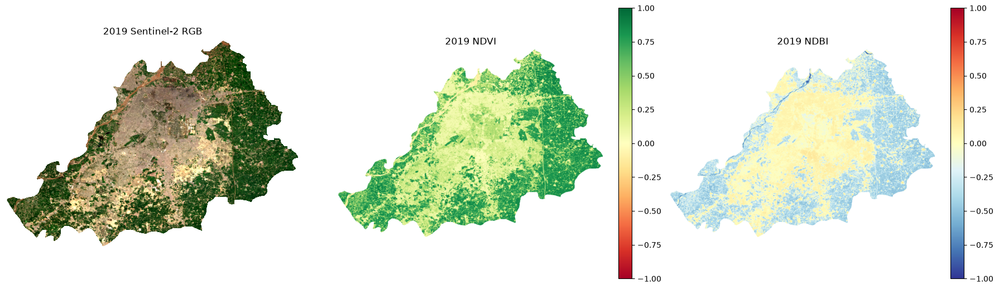

2025 band descriptions: ('B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDBI')


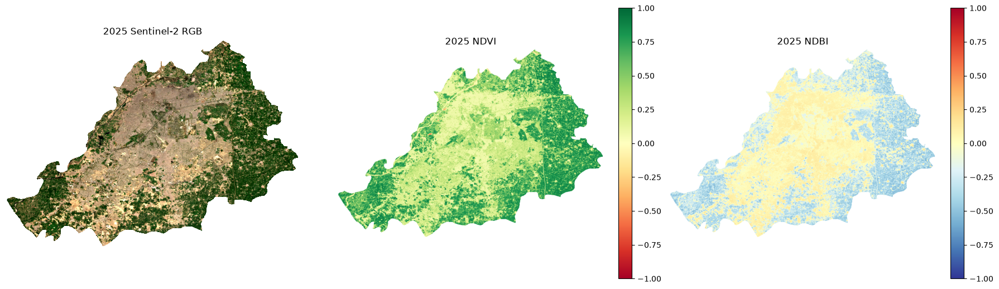

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling

def read_preview(path, indexes=None, max_size=1200):
    with rasterio.open(path) as src:
        if indexes is None:
            indexes = list(range(1, src.count + 1))

        scale = min(1, max_size / max(src.width, src.height))
        out_width = max(1, int(src.width * scale))
        out_height = max(1, int(src.height * scale))

        data = src.read(
            indexes,
            out_shape=(len(indexes), out_height, out_width),
            resampling=Resampling.bilinear if len(indexes) > 1
                       else Resampling.nearest,
            masked=True
        )
        return data, src.descriptions

for year in [2019, 2025]:
    path = DATA_DIR / f"Sentinel2_{year}_Features.tif"
    if not path.exists():
        continue

    data, descriptions = read_preview(path)

    print(year, "band descriptions:", descriptions)

    # Expected order: B2, B3, B4, B8, B11, B12, NDVI, NDBI
    if data.shape[0] < 8:
        print("Unexpected band count; inspect metadata before plotting.")
        continue

    # RGB display using percentile stretch
    rgb = np.moveaxis(data[[2, 1, 0]].filled(np.nan), 0, -1)
    lo, hi = np.nanpercentile(rgb, [2, 98])
    rgb = np.clip((rgb - lo) / max(hi - lo, 1e-6), 0, 1)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(rgb)
    axes[0].set_title(f"{year} Sentinel-2 RGB")

    ndvi = data[6]
    im1 = axes[1].imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
    axes[1].set_title(f"{year} NDVI")
    plt.colorbar(im1, ax=axes[1], fraction=0.046)

    ndbi = data[7]
    im2 = axes[2].imshow(ndbi, cmap="RdYlBu_r", vmin=-1, vmax=1)
    axes[2].set_title(f"{year} NDBI")
    plt.colorbar(im2, ax=axes[2], fraction=0.046)

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

inspect the Dynamic World label rasters

In [ ]:
from pathlib import Path
import numpy as np
import rasterio

DATA_DIR = Path(r"E:\Punjab GeoGuardian\data\raw")

for year in [2019, 2025]:
    feature_path = DATA_DIR / f"Sentinel2_{year}_Features.tif"
    label_path = DATA_DIR / f"DynamicWorld_{year}_Labels.tif"

    print(f"\n{'=' * 50}")
    print(f"YEAR: {year}")

    with rasterio.open(feature_path) as features, \
         rasterio.open(label_path) as labels:

        print("Feature raster shape:", (features.height, features.width))
        print("Label raster shape:", (labels.height, labels.width))
        print("Same CRS:", features.crs == labels.crs)
        print("Same transform:", features.transform == labels.transform)
        print("Same dimensions:",
              features.width == labels.width and
              features.height == labels.height)

        label_data = labels.read(1)
        values, counts = np.unique(label_data, return_counts=True)

        print("Label values and pixel counts:")
        print(dict(zip(values.tolist(), counts.tolist())))


YEAR: 2019
Feature raster shape: (5129, 7233)
Label raster shape: (5129, 7233)
Same CRS: True
Same transform: True
Same dimensions: True
Label values and pixel counts:
{0: 17542133, 1: 106790, 2: 17995, 3: 14208, 4: 10873023, 5: 166341, 6: 7586679, 7: 790800, 8: 88}

YEAR: 2025
Feature raster shape: (5129, 7233)
Label raster shape: (5129, 7233)
Same CRS: True
Same transform: True
Same dimensions: True
Label values and pixel counts:
{0: 17431262, 1: 171667, 2: 36002, 3: 8414, 4: 9634504, 5: 178768, 6: 9192303, 7: 445110, 8: 27}


check NoData and pixel area before calculating change

In [ ]:
from pathlib import Path
import rasterio
import numpy as np

DATA_DIR = Path(r"E:\Punjab GeoGuardian\data\raw")

for year in [2019, 2025]:
    print(f"\n{'=' * 60}")
    print(f"YEAR: {year}")

    for prefix in ["Sentinel2", "DynamicWorld"]:
        if prefix == "Sentinel2":
            filename = f"Sentinel2_{year}_Features.tif"
        else:
            filename = f"DynamicWorld_{year}_Labels.tif"

        path = DATA_DIR / filename

        with rasterio.open(path) as src:
            print(f"\nFile: {filename}")
            print("CRS:", src.crs)
            print("Transform:", src.transform)
            print("Resolution:", src.res)
            print("Bounds:", src.bounds)
            print("NoData:", src.nodata)
            print("Mask flags:", src.mask_flag_enums)

            if prefix == "DynamicWorld":
                labels = src.read(1)
                valid_mask = src.read_masks(1) > 0

                print("Total pixels:", labels.size)
                print("Valid according to raster mask:",
                      int(valid_mask.sum()))
                print("Zero-valued pixels:",
                      int((labels == 0).sum()))
                print("Zero-valued pixels inside valid mask:",
                      int(((labels == 0) & valid_mask).sum()))


YEAR: 2019

File: Sentinel2_2019_Features.tif
CRS: EPSG:4326
Transform: | 0.00, 0.00, 74.00|
| 0.00,-0.00, 31.72|
| 0.00, 0.00, 1.00|
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Bounds: BoundingBox(left=74.003392768823, bottom=31.25589216412622, right=74.65314421382665, top=31.71663807335112)
NoData: None
Mask flags: ([<MaskFlags.all_valid: 1>], [<MaskFlags.all_valid: 1>], [<MaskFlags.all_valid: 1>], [<MaskFlags.all_valid: 1>], [<MaskFlags.all_valid: 1>], [<MaskFlags.all_valid: 1>], [<MaskFlags.all_valid: 1>], [<MaskFlags.all_valid: 1>])

File: DynamicWorld_2019_Labels.tif
CRS: EPSG:4326
Transform: | 0.00, 0.00, 74.00|
| 0.00,-0.00, 31.72|
| 0.00, 0.00, 1.00|
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Bounds: BoundingBox(left=74.003392768823, bottom=31.25589216412622, right=74.65314421382665, top=31.71663807335112)
NoData: None
Mask flags: ([<MaskFlags.all_valid: 1>],)
Total pixels: 37098057
Valid according to raster mask: 37098057
Zero-valued pixels: 17

Check raster values and feature statistics

In [ ]:
from pathlib import Path
import numpy as np
import rasterio
from rasterio.windows import Window

DATA_DIR = Path(r"E:\Punjab GeoGuardian\data\raw")

for year in [2019, 2025]:
    print(f"\n{'=' * 60}")
    print(f"YEAR: {year}")

    feature_path = DATA_DIR / f"Sentinel2_{year}_Features.tif"
    label_path = DATA_DIR / f"DynamicWorld_{year}_Labels.tif"

    with rasterio.open(feature_path) as src:
        # Sample the centre of the raster
        w = Window(
            src.width // 2 - 250,
            src.height // 2 - 250,
            500,
            500
        )
        sample = src.read(window=w, masked=True).astype("float32")

        print("\nFeature band statistics (sample window):")
        for i, name in enumerate(src.descriptions):
            values = sample[i].compressed()
            values = values[np.isfinite(values)]

            if values.size:
                print(
                    f"{name}: min={values.min():.4f}, "
                    f"max={values.max():.4f}, "
                    f"mean={values.mean():.4f}, "
                    f"valid={values.size}"
                )
            else:
                print(f"{name}: no valid values in sample")

    with rasterio.open(label_path) as src:
        # Check a few windows, including corners and centre
        positions = {
            "top-left": (0, 0),
            "top-right": (0, src.width - 500),
            "centre": (src.height // 2 - 250, src.width // 2 - 250),
            "bottom-left": (src.height - 500, 0),
            "bottom-right": (src.height - 500, src.width - 500),
        }

        print("\nDynamic World sample-window class counts:")
        for name, (row, col) in positions.items():
            row = max(0, min(row, src.height - 500))
            col = max(0, min(col, src.width - 500))

            arr = src.read(
                1,
                window=Window(col, row, 500, 500)
            )

            values, counts = np.unique(arr, return_counts=True)
            print(name, dict(zip(values.tolist(), counts.tolist())))


YEAR: 2019

Feature band statistics (sample window):
B2: min=0.0193, max=1.3268, mean=0.0944, valid=250000
B3: min=0.0288, max=1.5588, mean=0.1135, valid=250000
B4: min=0.0204, max=1.7144, mean=0.1244, valid=250000
B8: min=0.0238, max=1.6377, mean=0.2038, valid=250000
B11: min=0.0470, max=1.5337, mean=0.2027, valid=250000
B12: min=0.0358, max=1.5220, mean=0.1753, valid=250000
NDVI: min=-0.1990, max=0.9221, mean=0.2389, valid=250000
NDBI: min=-0.5333, max=0.5772, mean=0.0071, valid=250000

Dynamic World sample-window class counts:
top-left {0: 250000}
top-right {0: 250000}
centre {0: 121, 1: 3159, 2: 679, 4: 13076, 5: 277, 6: 230025, 7: 2663}
bottom-left {0: 246996, 4: 2992, 6: 12}
bottom-right {0: 250000}

YEAR: 2025

Feature band statistics (sample window):
B2: min=0.0154, max=0.5380, mean=0.0895, valid=250000
B3: min=0.0228, max=0.6724, mean=0.1105, valid=250000
B4: min=0.0181, max=0.8268, mean=0.1204, valid=250000
B8: min=0.0311, max=0.9100, mean=0.2109, valid=250000
B11: min=0.043

check whether the raster corners are outside Lahore

In [ ]:
from pathlib import Path
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

DATA_DIR = Path(r"E:\Punjab GeoGuardian\data\raw")
feature_path = DATA_DIR / "Sentinel2_2019_Features.tif"

with rasterio.open(feature_path) as src:
    raster_bounds = src.bounds
    raster_crs = src.crs

# Re-create the Lahore boundary using the exported raster extent
# First inspect whether a local boundary file already exists.
boundary_files = list(Path(r"E:\Punjab GeoGuardian").rglob("*.geojson"))
boundary_files += list(Path(r"E:\Punjab GeoGuardian").rglob("*.shp"))

print("Raster CRS:", raster_crs)
print("Raster bounds:", raster_bounds)
print("Local boundary files found:")
for f in boundary_files:
    print(f)

Raster CRS: EPSG:4326
Raster bounds: BoundingBox(left=74.003392768823, bottom=31.25589216412622, right=74.65314421382665, top=31.71663807335112)
Local boundary files found:
E:\Punjab GeoGuardian\.venv\Lib\site-packages\geopandas\tests\data\null_geom.geojson
E:\Punjab GeoGuardian\.venv\Lib\site-packages\pyogrio\tests\fixtures\naturalearth_lowres\naturalearth_lowres.shp


In [ ]:

import sys
import importlib.util
from importlib.metadata import version, PackageNotFoundError

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("\nLIBRARY INSTALLATION CHECK")
print("-" * 55)

libraries = {
    "numpy": "NumPy",
    "pandas": "Pandas",
    "matplotlib": "Matplotlib",
    "rasterio": "Rasterio",
    "scikit-learn": "Scikit-learn",
    "geopandas": "GeoPandas",
    "shapely": "Shapely",
    "pyproj": "PyProj",
    "jupyter": "Jupyter",
    "ipykernel": "IPython Kernel",
}

installed = []
missing = []

for package, display_name in libraries.items():
    try:
        package_version = version(package)
        print(f"[INSTALLED] {display_name}: {package_version}")
        installed.append(package)
    except PackageNotFoundError:
        print(f"[MISSING]   {display_name}")
        missing.append(package)

print("\n" + "-" * 55)
print("Installed:", len(installed), "/", len(libraries))
print("Missing:", missing if missing else "None")


Python executable: e:\Punjab GeoGuardian\.venv\Scripts\python.exe
Python version: 3.13.7

LIBRARY INSTALLATION CHECK
-------------------------------------------------------
[INSTALLED] NumPy: 2.5.4
[INSTALLED] Pandas: 3.0.6
[INSTALLED] Matplotlib: 3.11.2
[INSTALLED] Rasterio: 1.5.2
[INSTALLED] Scikit-learn: 1.9.1
[INSTALLED] GeoPandas: 1.2.0
[INSTALLED] Shapely: 2.2.0
[INSTALLED] PyProj: 3.8.0
[MISSING]   Jupyter
[INSTALLED] IPython Kernel: 7.4.0

-------------------------------------------------------
Installed: 9 / 10
Missing: ['jupyter']


Check project files and create output folders

In [ ]:

from pathlib import Path
import json
import sys

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")
RAW_DIR = PROJECT_DIR / "data" / "raw"
BOUNDARY_DIR = PROJECT_DIR / "data" / "boundaries"
REPORT_DIR = PROJECT_DIR / "outputs" / "data_quality"
MAP_DIR = REPORT_DIR / "maps"

for folder in [BOUNDARY_DIR, REPORT_DIR, MAP_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

FILES = {
    "features_2019": RAW_DIR / "Sentinel2_2019_Features.tif",
    "features_2025": RAW_DIR / "Sentinel2_2025_Features.tif",
    "labels_2019": RAW_DIR / "DynamicWorld_2019_Labels.tif",
    "labels_2025": RAW_DIR / "DynamicWorld_2025_Labels.tif",
}

print("Python:", sys.executable)
print("Project folder exists:", PROJECT_DIR.exists())

missing = []
for name, path in FILES.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{name}: {status} — {path}")
    if not path.exists():
        missing.append(name)

if missing:
    raise FileNotFoundError(
        "These raster files were not found. Check their names and location: "
        + ", ".join(missing)
    )

print("\nAll four raster files are available.")


Python: e:\Punjab GeoGuardian\.venv\Scripts\python.exe
Project folder exists: True
features_2019: FOUND — E:\Punjab GeoGuardian\data\raw\Sentinel2_2019_Features.tif
features_2025: FOUND — E:\Punjab GeoGuardian\data\raw\Sentinel2_2025_Features.tif
labels_2019: FOUND — E:\Punjab GeoGuardian\data\raw\DynamicWorld_2019_Labels.tif
labels_2025: FOUND — E:\Punjab GeoGuardian\data\raw\DynamicWorld_2025_Labels.tif

All four raster files are available.


Inspect raster metadata and alignment

In [ ]:

import rasterio
import pandas as pd

metadata = []

for name, path in FILES.items():
    with rasterio.open(path) as src:
        metadata.append({
            "file": name,
            "width": src.width,
            "height": src.height,
            "bands": src.count,
            "crs": str(src.crs),
            "dtype": str(src.dtypes[0]),
            "nodata": src.nodata,
            "bounds": tuple(src.bounds),
            "transform": tuple(src.transform),
        })

metadata_df = pd.DataFrame(metadata)

display(metadata_df[
    ["file", "width", "height", "bands", "crs", "dtype", "nodata"]
])

for year in ["2019", "2025"]:
    with rasterio.open(FILES[f"features_{year}"]) as features, \
         rasterio.open(FILES[f"labels_{year}"]) as labels:

        same_grid = (
            features.width == labels.width
            and features.height == labels.height
            and features.crs == labels.crs
            and features.transform == labels.transform
        )

        print(f"\n{year}: features and labels aligned = {same_grid}")
        print("Feature bands:", features.count)
        print("Feature CRS:", features.crs)
        print("Bounds:", features.bounds)
        print("Resolution:", features.res)
        print("Feature NoData:", features.nodata)
        print("Label NoData:", labels.nodata)

metadata_df.drop(columns=["bounds", "transform"]).to_csv(
    REPORT_DIR / "raster_metadata.csv", index=False
)

print("\nMetadata saved to:", REPORT_DIR / "raster_metadata.csv")


,file,width,height,bands,crs,dtype,nodata
0,features_2019,7233,5129,8,EPSG:4326,float32,None
1,features_2025,7233,5129,8,EPSG:4326,float32,None
2,labels_2019,7233,5129,1,EPSG:4326,uint8,None
3,labels_2025,7233,5129,1,EPSG:4326,uint8,None



2019: features and labels aligned = True
Feature bands: 8
Feature CRS: EPSG:4326
Bounds: BoundingBox(left=74.003392768823, bottom=31.25589216412622, right=74.65314421382665, top=31.71663807335112)
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Feature NoData: None
Label NoData: None

2025: features and labels aligned = True
Feature bands: 8
Feature CRS: EPSG:4326
Bounds: BoundingBox(left=74.003392768823, bottom=31.25589216412622, right=74.65314421382665, top=31.71663807335112)
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Feature NoData: None
Label NoData: None

Metadata saved to: E:\Punjab GeoGuardian\outputs\data_quality\raster_metadata.csv


Check zeros, invalid values and reflectance statistics

In [ ]:

from pathlib import Path

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")
RAW_DIR = PROJECT_DIR / "data" / "raw"
REPORT_DIR = PROJECT_DIR / "outputs" / "data_quality"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "features_2019": RAW_DIR / "Sentinel2_2019_Features.tif",
    "features_2025": RAW_DIR / "Sentinel2_2025_Features.tif",
    "labels_2019": RAW_DIR / "DynamicWorld_2019_Labels.tif",
    "labels_2025": RAW_DIR / "DynamicWorld_2025_Labels.tif",
}

for name, path in FILES.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'} — {path}")

assert all(path.exists() for path in FILES.values()), (
    "Some raster files are missing. Check the paths printed above."
)

print("\nSetup complete. Now run the optimized sampling cell.")


features_2019: FOUND — E:\Punjab GeoGuardian\data\raw\Sentinel2_2019_Features.tif
features_2025: FOUND — E:\Punjab GeoGuardian\data\raw\Sentinel2_2025_Features.tif
labels_2019: FOUND — E:\Punjab GeoGuardian\data\raw\DynamicWorld_2019_Labels.tif
labels_2025: FOUND — E:\Punjab GeoGuardian\data\raw\DynamicWorld_2025_Labels.tif

Setup complete. Now run the optimized sampling cell.


In [ ]:

import numpy as np
import pandas as pd
import rasterio

rng = np.random.default_rng(42)
sample_size = 300_000

value_rows = []
class_rows = []

band_names = [
    "B2_Blue", "B3_Green", "B4_Red",
    "B8_NIR", "B11_SWIR1", "B12_SWIR2",
    "NDVI", "NDBI"
]

for year in ["2019", "2025"]:
    print(f"Processing {year}...")

    with rasterio.open(FILES[f"features_{year}"]) as features, \
         rasterio.open(FILES[f"labels_{year}"]) as labels:

        total_pixels = features.width * features.height
        n = min(sample_size, total_pixels)

        # Read a manageable window instead of reading individual pixels.
        # Multiple windows provide a faster approximate random sample.
        sampled_features = []
        sampled_labels = []
        collected = 0

        while collected < n:
            h = min(512, features.height)
            w = min(512, features.width)

            row_off = int(rng.integers(0, features.height - h + 1))
            col_off = int(rng.integers(0, features.width - w + 1))
            window = ((row_off, row_off + h),
                      (col_off, col_off + w))

            x = features.read(window=window)
            y = labels.read(1, window=window)

            flat_x = x.reshape(features.count, -1).T
            flat_y = y.ravel()

            take = min(n - collected, len(flat_y))
            idx = rng.choice(len(flat_y), size=take, replace=False)

            sampled_features.append(flat_x[idx])
            sampled_labels.append(flat_y[idx])
            collected += take

        X = np.concatenate(sampled_features, axis=0)
        Y = np.concatenate(sampled_labels, axis=0)

        for i, band in enumerate(band_names[:features.count]):
            arr = X[:, i].astype("float64")
            finite = np.isfinite(arr)
            valid = arr[finite]

            value_rows.append({
                "year": year,
                "band": band,
                "sample_count": len(arr),
                "non_finite_count": int((~finite).sum()),
                "zero_count": int((arr == 0).sum()),
                "min": float(valid.min()) if len(valid) else np.nan,
                "p01": float(np.percentile(valid, 1)) if len(valid) else np.nan,
                "median": float(np.median(valid)) if len(valid) else np.nan,
                "p99": float(np.percentile(valid, 99)) if len(valid) else np.nan,
                "max": float(valid.max()) if len(valid) else np.nan,
            })

        unique, counts = np.unique(Y, return_counts=True)

        for class_id, count in zip(unique, counts):
            class_rows.append({
                "year": year,
                "class_id": int(class_id),
                "sample_count": int(count),
                "sample_percent": round(100 * count / len(Y), 3)
            })

value_df = pd.DataFrame(value_rows)
class_df = pd.DataFrame(class_rows)

display(value_df.round(4))
display(class_df.sort_values(["year", "class_id"]))

value_df.to_csv(REPORT_DIR / "sampled_band_statistics.csv", index=False)
class_df.to_csv(REPORT_DIR / "sampled_label_distribution.csv", index=False)

print("Reports saved in:", REPORT_DIR)


Processing 2019...
Processing 2025...


,year,band,sample_count,non_finite_count,zero_count,min,p01,median,p99,max
0,2019,B2_Blue,300000,1845,0,0.0143,0.0232,0.0410,0.1221,0.4024
1,2019,B3_Green,300000,1845,0,0.0165,0.0470,0.0759,0.1489,0.4644
2,2019,B4_Red,300000,1845,0,0.0140,0.0196,0.0494,0.1751,0.4856
3,2019,B8_NIR,300000,1845,0,0.0143,0.1040,0.3497,0.5498,0.6187
4,2019,B11_SWIR1,300000,1845,0,0.0134,0.0360,0.1747,0.2471,0.5147
5,2019,B12_SWIR2,300000,1845,0,0.0109,0.0294,0.1019,0.2168,0.5035
6,2019,NDVI,300000,1845,11,-0.4042,-0.0992,0.7543,0.9223,0.9427
7,2019,NDBI,300000,1845,54,-0.7399,-0.5634,-0.3442,0.1234,0.5548
8,2025,B2_Blue,300000,211342,0,0.0113,0.0212,0.0340,0.1197,0.2380
9,2025,B3_Green,300000,211342,0,0.0252,0.0450,0.0690,0.1488,0.2454


,year,class_id,sample_count,sample_percent
0,2019,0,9961,3.320
1,2019,1,308,0.103
2,2019,2,9,0.003
3,2019,3,176,0.059
4,2019,4,257895,85.965
5,2019,5,44,0.015
6,2019,6,28665,9.555
7,2019,7,2942,0.981
8,2025,0,211342,70.447
9,2025,1,11,0.004


Reports saved in: E:\Punjab GeoGuardian\outputs\data_quality


Plot the data and investigate the unusual values

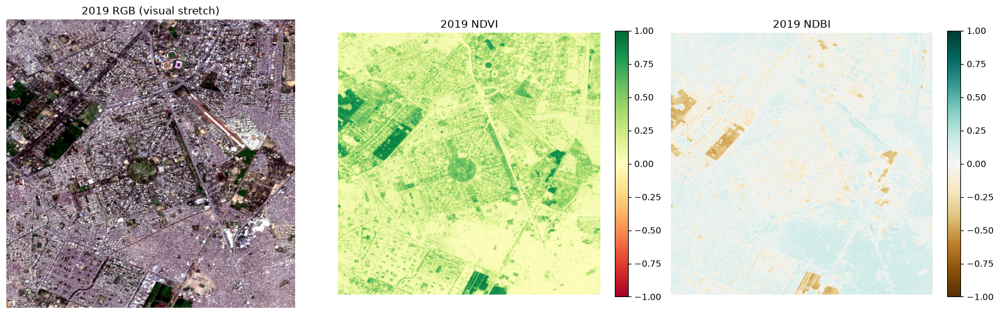

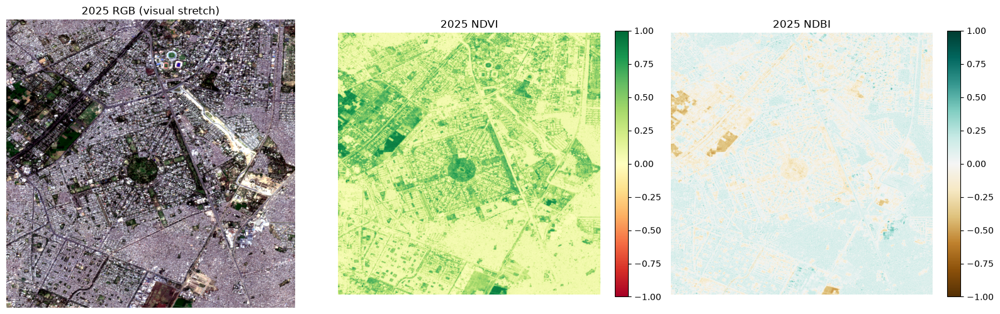

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.windows import Window

def stretch_rgb(rgb):
    """Percentile stretch for visual inspection only; does not alter source data."""
    out = np.zeros_like(rgb, dtype=np.float32)

    for channel in range(3):
        band = rgb[channel]
        valid = np.isfinite(band)

        if not valid.any():
            continue

        low, high = np.percentile(band[valid], [2, 98])

        if high > low:
            out[channel] = np.clip((band - low) / (high - low), 0, 1)

    return np.moveaxis(out, 0, -1)

for year in ["2019", "2025"]:
    with rasterio.open(FILES[f"features_{year}"]) as src:
        # A central sample window, not the full district.
        h = min(800, src.height)
        w = min(800, src.width)
        row_off = (src.height - h) // 2
        col_off = (src.width - w) // 2
        window = Window(col_off, row_off, w, h)

        # Assumed band order: B2, B3, B4, B8, B11, B12, NDVI, NDBI
        rgb = src.read([3, 2, 1], window=window).astype("float32")
        ndvi = src.read(7, window=window).astype("float32")
        ndbi = src.read(8, window=window).astype("float32")

        fig, axes = plt.subplots(1, 3, figsize=(16, 5))

        axes[0].imshow(stretch_rgb(rgb))
        axes[0].set_title(f"{year} RGB (visual stretch)")

        im1 = axes[1].imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
        axes[1].set_title(f"{year} NDVI")
        plt.colorbar(im1, ax=axes[1], fraction=0.046)

        im2 = axes[2].imshow(ndbi, cmap="BrBG", vmin=-1, vmax=1)
        axes[2].set_title(f"{year} NDBI")
        plt.colorbar(im2, ax=axes[2], fraction=0.046)

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        plt.show()


Export the Lahore boundary for checking

In [4]:

from pathlib import Path

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")
BOUNDARY_DIR = PROJECT_DIR / "data" / "boundaries"

BOUNDARY_DIR.mkdir(parents=True, exist_ok=True)

print("Boundary folder:", BOUNDARY_DIR)
print("Folder ready:", BOUNDARY_DIR.exists())


Boundary folder: E:\Punjab GeoGuardian\data\boundaries
Folder ready: True


In [1]:
import ee

ee.Initialize(project="punjab-geoguardian-511808")
print("Earth Engine initialized successfully!")

Earth Engine initialized successfully!


In [2]:

EE_PROJECT = "punjab-geoguardian-511808"

ee.Initialize(project=EE_PROJECT)

print("Google Earth Engine initialized successfully!")


Google Earth Engine initialized successfully!


In [5]:

import ee
import geopandas as gpd

EE_PROJECT = "punjab-geoguardian-511808"
BOUNDARY_PATH = BOUNDARY_DIR / "Lahore_District.geojson"

ee.Initialize(project=EE_PROJECT)

districts = ee.FeatureCollection("FAO/GAUL/2025/level2")

lahore = districts.filter(
    ee.Filter.And(
        ee.Filter.eq("GAUL0_NAME", "Pakistan"),
        ee.Filter.eq("GAUL1_NAME", "Punjab"),
        ee.Filter.eq("GAUL2_NAME", "Lahore")
    )
)

count = lahore.size().getInfo()
print("Matching Lahore district features:", count)

if count != 1:
    raise ValueError(
        f"Expected exactly one Lahore district feature, found {count}."
    )

geojson = lahore.getInfo()

boundary_gdf = gpd.GeoDataFrame.from_features(
    geojson["features"],
    crs="EPSG:4326"
)

boundary_gdf.to_file(BOUNDARY_PATH, driver="GeoJSON")

print("Boundary saved:", BOUNDARY_PATH)
display(boundary_gdf[["geometry"]].head())


Matching Lahore district features: 1
Boundary saved: E:\Punjab GeoGuardian\data\boundaries\Lahore_District.geojson


,geometry
0,"POLYGON ((74.00353 31.36064, 74.00363 31.36022..."


Overlay boundary on the satellite raster

In [7]:

from pathlib import Path
import rasterio

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")
RAW_DIR = PROJECT_DIR / "data" / "raw"
BOUNDARY_DIR = PROJECT_DIR / "data" / "boundaries"
BOUNDARY_PATH = BOUNDARY_DIR / "Lahore_District.geojson"

FILES = {
    "features_2019": RAW_DIR / "Sentinel2_2019_Features.tif",
    "features_2025": RAW_DIR / "Sentinel2_2025_Features.tif",
    "labels_2019": RAW_DIR / "DynamicWorld_2019_Labels.tif",
    "labels_2025": RAW_DIR / "DynamicWorld_2025_Labels.tif",
}

for name, path in FILES.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

assert all(path.exists() for path in FILES.values()), (
    "Raster files missing. Check the paths above."
)

assert BOUNDARY_PATH.exists(), (
    f"Lahore boundary file not found: {BOUNDARY_PATH}"
)

print("\nSetup complete. Run the boundary overlay cell again.")


features_2019: FOUND
features_2025: FOUND
labels_2019: FOUND
labels_2025: FOUND

Setup complete. Run the boundary overlay cell again.


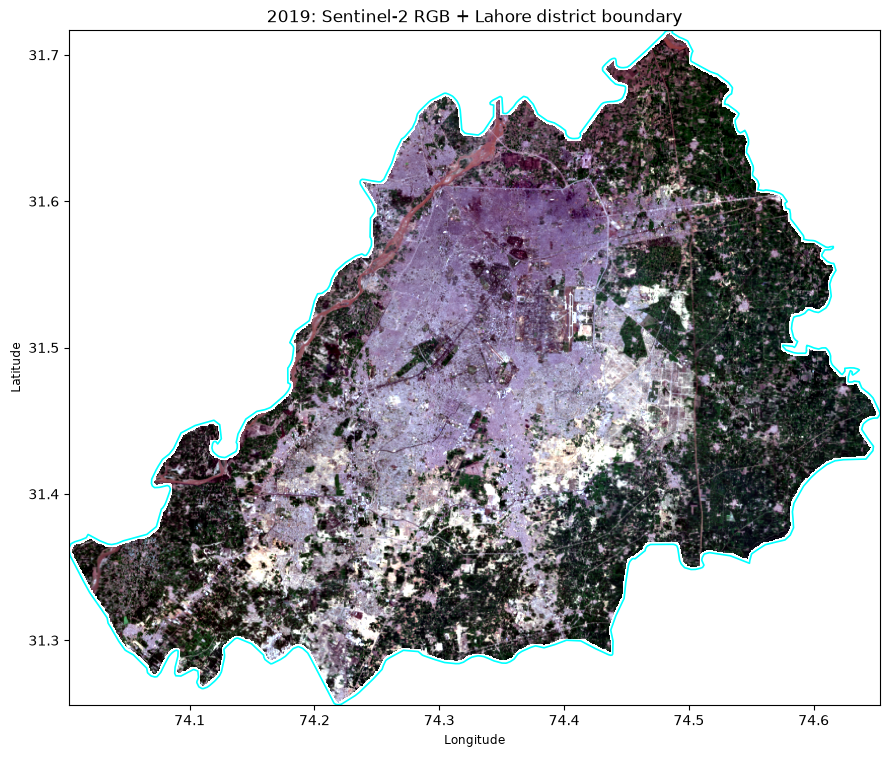

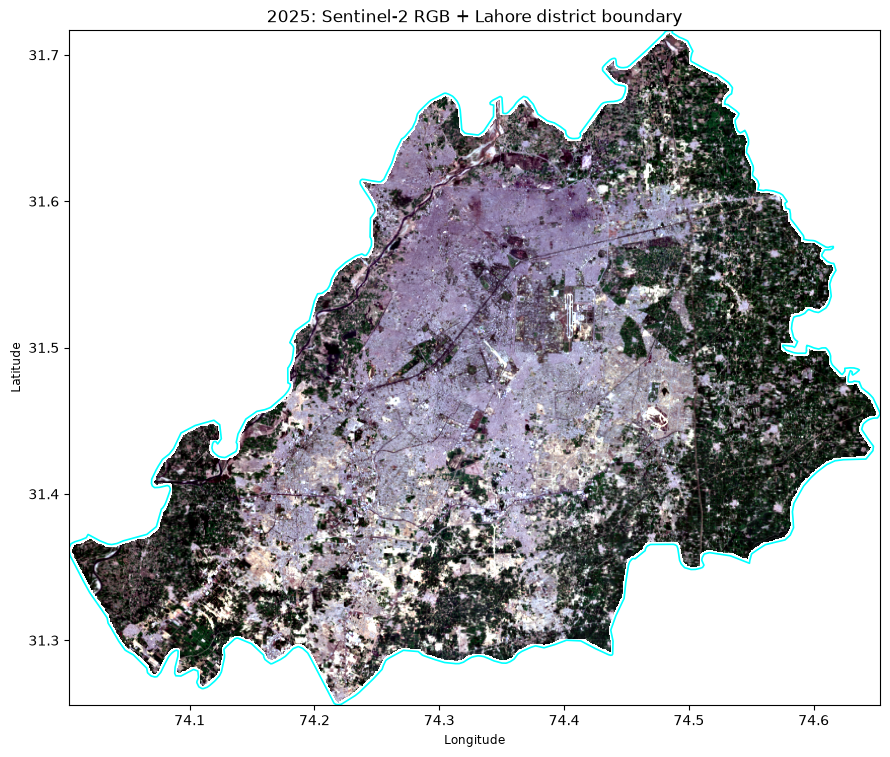

In [14]:

import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
from rasterio.enums import Resampling

boundary_gdf = gpd.read_file(BOUNDARY_PATH).to_crs("EPSG:4326")

for year in ["2019", "2025"]:
    with rasterio.open(FILES[f"features_{year}"]) as src:
        # Downsample to a manageable size.
        rgb = src.read(
            [3, 2, 1],
            out_shape=(3, 800, 800),
            resampling=Resampling.average
        ).astype("float32")

        # Stretch each band for visualization only.
        display_rgb = np.zeros_like(rgb)

        for i in range(3):
            band = rgb[i]
            valid = np.isfinite(band)

            if valid.any():
                lo, hi = np.nanpercentile(band[valid], [2, 98])
                if hi > lo:
                    display_rgb[i] = np.clip(
                        (band - lo) / (hi - lo), 0, 1
                    )

        bounds = src.bounds

        fig, ax = plt.subplots(figsize=(9, 8))

        ax.imshow(
            np.moveaxis(display_rgb, 0, -1),
            extent=[
                bounds.left, bounds.right,
                bounds.bottom, bounds.top
            ],
            origin="upper"
        )

        boundary_gdf.boundary.plot(
            ax=ax, color="cyan", linewidth=1.2
        )

        ax.set_xlim(bounds.left, bounds.right)
        ax.set_ylim(bounds.bottom, bounds.top)
        ax.set_title(f"{year}: Sentinel-2 RGB + Lahore district boundary")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        plt.tight_layout()
        plt.show()


Save an initial diagnostic summary

In [12]:

from pathlib import Path
import json

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")
REPORT_DIR = PROJECT_DIR / "outputs" / "data_quality"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Report directory ready:", REPORT_DIR)


Report directory ready: E:\Punjab GeoGuardian\outputs\data_quality


In [13]:

summary = {
    "project": "Punjab GeoGuardian",
    "study_area": "Lahore District, Punjab, Pakistan",
    "years": [2019, 2025],
    "data_sources": [
        "Sentinel-2 Surface Reflectance Harmonized",
        "Google Dynamic World land-cover labels"
    ],
    "checks_completed": [
        "Raster file existence",
        "Raster metadata and alignment",
        "Sampled spectral value statistics",
        "Sampled land-cover label distribution",
        "RGB, NDVI and NDBI visual inspection",
        "Lahore district boundary overlay"
    ],
    "issues_to_resolve": [
        "Determine whether zero labels outside the district are background or genuine water",
        "Verify Sentinel-2 reflectance scaling and band order",
        "Verify cloud, shadow and valid-observation masking",
        "Apply the correct district mask before area calculations",
        "Perform independent land-cover validation before reporting change"
    ],
    "status": "Preprocessing diagnostics; no validated farmland-loss estimate yet"
}

summary_path = REPORT_DIR / "diagnostic_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Diagnostic summary saved:", summary_path)
print("Next: inspect outputs before training a classifier.")


Diagnostic summary saved: E:\Punjab GeoGuardian\outputs\data_quality\diagnostic_summary.json
Next: inspect outputs before training a classifier.


check invalid pixels and their locations

In [ ]:

import numpy as np
import rasterio
import pandas as pd

rows = []

for year in ["2019", "2025"]:
    path = FILES[f"features_{year}"]

    with rasterio.open(path) as src:
        total = src.width * src.height
        invalid_per_band = []

        for b in range(1, src.count + 1):
            invalid_count = 0
            sampled_count = 0

            # Inspect a grid of windows spread across the raster.
            window_size = 512

            for row_off in range(0, src.height, window_size):
                for col_off in range(0, src.width, window_size):
                    window = rasterio.windows.Window(
                        col_off,
                        row_off,
                        min(window_size, src.width - col_off),
                        min(window_size, src.height - row_off)
                    )

                    arr = src.read(b, window=window)
                    invalid_count += int((~np.isfinite(arr)).sum())
                    sampled_count += arr.size

            invalid_per_band.append(invalid_count)

            rows.append({
                "year": year,
                "band": b,
                "total_pixels": total,
                "invalid_pixels": invalid_count,
                "invalid_percent": round(100 * invalid_count / total, 3)
            })

        print(
            f"{year}: invalid counts same across all bands =",
            len(set(invalid_per_band)) == 1
        )

result = pd.DataFrame(rows)
display(result)
result.to_csv(REPORT_DIR / "invalid_pixel_scan.csv", index=False)

print("Saved:", REPORT_DIR / "invalid_pixel_scan.csv")


2019: invalid counts same across all bands = True
2025: invalid counts same across all bands = True


,year,band,total_pixels,invalid_pixels,invalid_percent
0,2019,1,37098057,17211844,46.396
1,2019,2,37098057,17211844,46.396
2,2019,3,37098057,17211844,46.396
3,2019,4,37098057,17211844,46.396
4,2019,5,37098057,17211844,46.396
5,2019,6,37098057,17211844,46.396
6,2019,7,37098057,17211844,46.396
7,2019,8,37098057,17211844,46.396
8,2025,1,37098057,17211844,46.396
9,2025,2,37098057,17211844,46.396


Saved: E:\Punjab GeoGuardian\outputs\data_quality\invalid_pixel_scan.csv


invalid pixels ka location check karo

In [15]:

import numpy as np
import rasterio
import pandas as pd

grid_rows = []

# Coarse grid: fast enough for diagnosis, not a final mask.
grid_size = 12

for year in ["2019", "2025"]:
    path = FILES[f"features_{year}"]

    with rasterio.open(path) as src:
        row_edges = np.linspace(0, src.height, grid_size + 1, dtype=int)
        col_edges = np.linspace(0, src.width, grid_size + 1, dtype=int)

        print(f"\nScanning invalid pixels: {year}")

        for i in range(grid_size):
            for j in range(grid_size):
                r0, r1 = row_edges[i], row_edges[i + 1]
                c0, c1 = col_edges[j], col_edges[j + 1]

                arr = src.read(
                    window=((r0, r1), (c0, c1))
                )

                # Pixel invalid if any of the 8 bands is non-finite.
                invalid = ~np.isfinite(arr).all(axis=0)

                grid_rows.append({
                    "year": year,
                    "grid_row": i,
                    "grid_col": j,
                    "invalid_percent": round(
                        100 * invalid.mean(), 2
                    )
                })

grid_df = pd.DataFrame(grid_rows)

display(
    grid_df.pivot_table(
        index=["year", "grid_row"],
        columns="grid_col",
        values="invalid_percent"
    ).round(1)
)

grid_df.to_csv(
    REPORT_DIR / "invalid_pixel_grid.csv",
    index=False
)

print("Saved:", REPORT_DIR / "invalid_pixel_grid.csv")



Scanning invalid pixels: 2019

Scanning invalid pixels: 2025


grid_col          0      1      2      3      4      5      6     7     8   \
year grid_row                                                                
2019 0         100.0  100.0  100.0  100.0  100.0  100.0  100.0  97.9  36.8   
     1         100.0  100.0  100.0  100.0   99.1   43.1   43.4  63.5   5.3   
     2         100.0  100.0  100.0  100.0   64.0    0.0    0.0   0.0   0.0   
     3         100.0  100.0  100.0  100.0   46.8    0.0    0.0   0.0   0.0   
     4         100.0  100.0  100.0   82.5    2.7    0.0    0.0   0.0   0.0   
     5         100.0  100.0  100.0   37.2    0.0    0.0    0.0   0.0   0.0   
     6         100.0  100.0   90.9   13.7    0.0    0.0    0.0   0.0   0.0   
     7         100.0   49.5   17.1    0.0    0.0    0.0    0.0   0.0   0.0   
     8          99.9   34.3    0.0    0.0    0.0    0.0    0.0   0.0   0.0   
     9          18.3    0.0    0.0    0.0    0.0    0.0    0.0   0.0  57.1   
     10         56.3    0.0    5.1    0.2    0.0    0.0    0.6   7.0  90.2   
     11         98.4   61.6   80.0   66.4   48.9   82.3   86.8  98.7  99.5   
2025 0         100.0  100.0  100.0  100.0  100.0  100.0  100.0  97.9  36.8   
     1         100.0  100.0  100.0  100.0   99.1   43.1   43.4  63.5   5.3   
     2         100.0  100.0  100.0  100.0   64.0    0.0    0.0   0.0   0.0   
     3         100.0  100.0  100.0  100.0   46.8    0.0    0.0   0.0   0.0   
     4         100.0  100.0  100.0   82.5    2.7    0.0    0.0   0.0   0.0   
     5         100.0  100.0  100.0   37.2    0.0    0.0    0.0   0.0   0.0   
     6         100.0  100.0   90.9   13.7    0.0    0.0    0.0   0.0   0.0   
     7         100.0   49.5   17.1    0.0    0.0    0.0    0.0   0.0   0.0   
     8          99.9   34.3    0.0    0.0    0.0    0.0    0.0   0.0   0.0   
     9          18.3    0.0    0.0    0.0    0.0    0.0    0.0   0.0  57.1   
     10         56.3    0.0    5.1    0.2    0.0    0.0    0.6   7.0  90.2   
     11         98.4   61.6   80.0   66.4   48.9   82.3   86.8  98.7  99.5   

grid_col          9      10     11  
year grid_row                       
2019 0          67.2  100.0  100.0  
     1          14.0   99.2  100.0  
     2           0.0   82.2  100.0  
     3           0.0   20.4   95.6  
     4           0.0    0.2   73.8  
     5           0.0   19.5   90.6  
     6           0.0    0.0   21.1  
     7           0.0    0.2   42.9  
     8           0.0   24.1  100.0  
     9          57.9   87.4  100.0  
     10        100.0  100.0  100.0  
     11        100.0  100.0  100.0  
2025 0          67.2  100.0  100.0  
     1          14.0   99.2  100.0  
     2           0.0   82.2  100.0  
     3           0.0   20.4   95.6  
     4           0.0    0.2   73.8  
     5           0.0   19.5   90.6  
     6           0.0    0.0   21.1  
     7           0.0    0.2   42.9  
     8           0.0   24.1  100.0  
     9          57.9   87.4  100.0  
     10        100.0  100.0  100.0  
     11        100.0  100.0  100.0

Saved: E:\Punjab GeoGuardian\outputs\data_quality\invalid_pixel_grid.csv


Lahore boundary ke andar valid pixels count karo

In [16]:

import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
from rasterio.features import geometry_mask

boundary_gdf = gpd.read_file(BOUNDARY_PATH)

results = []

for year in ["2019", "2025"]:
    path = FILES[f"features_{year}"]

    with rasterio.open(path) as src:
        boundary = boundary_gdf.to_crs(src.crs)

        # True for pixels whose centres fall inside the district polygon.
        inside = geometry_mask(
            boundary.geometry,
            out_shape=(src.height, src.width),
            transform=src.transform,
            invert=True,
            all_touched=False
        )

        inside_count = int(inside.sum())
        valid_count = 0
        invalid_count = 0

        # Process in windows to avoid loading all 8 bands into RAM.
        for _, window in src.block_windows(1):
            data = src.read(window=window)

            r0 = int(window.row_off)
            c0 = int(window.col_off)
            h = int(window.height)
            w = int(window.width)

            inside_window = inside[r0:r0+h, c0:c0+w]
            pixel_valid = np.isfinite(data).all(axis=0)

            valid_count += int((inside_window & pixel_valid).sum())
            invalid_count += int(
                (inside_window & ~pixel_valid).sum()
            )

        results.append({
            "year": year,
            "district_pixels": inside_count,
            "valid_pixels": valid_count,
            "invalid_pixels": invalid_count,
            "valid_percent": round(
                100 * valid_count / inside_count, 3
            ) if inside_count else 0,
            "invalid_percent": round(
                100 * invalid_count / inside_count, 3
            ) if inside_count else 0
        })

result_df = pd.DataFrame(results)
display(result_df)

result_df.to_csv(
    REPORT_DIR / "district_valid_pixel_summary.csv",
    index=False
)

print("Saved:", REPORT_DIR / "district_valid_pixel_summary.csv")


,year,district_pixels,valid_pixels,invalid_pixels,valid_percent,invalid_percent
0,2019,19870699,19870699,0,100.0,0.0
1,2025,19870699,19870699,0,100.0,0.0


Saved: E:\Punjab GeoGuardian\outputs\data_quality\district_valid_pixel_summary.csv


district ke andar label distribution check karo

In [17]:

import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
from rasterio.features import geometry_mask

boundary_gdf = gpd.read_file(BOUNDARY_PATH)
class_names = {
    0: "Water",
    1: "Trees",
    2: "Grass",
    3: "Flooded vegetation",
    4: "Crops",
    5: "Shrub and scrub",
    6: "Built-up",
    7: "Bare ground",
    8: "Snow and ice"
}

label_rows = []

for year in ["2019", "2025"]:
    with rasterio.open(FILES[f"labels_{year}"]) as src:
        boundary = boundary_gdf.to_crs(src.crs)

        inside = geometry_mask(
            boundary.geometry,
            out_shape=(src.height, src.width),
            transform=src.transform,
            invert=True,
            all_touched=False
        )

        counts = {}

        for _, window in src.block_windows(1):
            labels = src.read(1, window=window)

            r0 = int(window.row_off)
            c0 = int(window.col_off)
            h = int(window.height)
            w = int(window.width)

            inside_window = inside[r0:r0+h, c0:c0+w]
            values = labels[inside_window]

            unique, freq = np.unique(values, return_counts=True)

            for class_id, count in zip(unique, freq):
                class_id = int(class_id)
                counts[class_id] = counts.get(class_id, 0) + int(count)

        total = sum(counts.values())

        for class_id, count in sorted(counts.items()):
            label_rows.append({
                "year": year,
                "class_id": class_id,
                "class_name": class_names.get(
                    class_id, "Unknown"
                ),
                "pixel_count": count,
                "percent": round(100 * count / total, 3)
            })

label_df = pd.DataFrame(label_rows)
display(label_df)

label_df.to_csv(
    REPORT_DIR / "district_label_distribution.csv",
    index=False
)

print("Saved:", REPORT_DIR / "district_label_distribution.csv")


,year,class_id,class_name,pixel_count,percent
0,2019,0,Water,329650,1.659
1,2019,1,Trees,106665,0.537
2,2019,2,Grass,17987,0.091
3,2019,3,Flooded vegetation,14188,0.071
4,2019,4,Crops,10860440,54.656
5,2019,5,Shrub and scrub,166210,0.836
6,2019,6,Built-up,7584967,38.172
7,2019,7,Bare ground,790504,3.978
8,2019,8,Snow and ice,88,0.000
9,2025,0,Water,219011,1.102


Saved: E:\Punjab GeoGuardian\outputs\data_quality\district_label_distribution.csv


Next step — pixel-level change matrix

In [18]:

import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
from rasterio.features import geometry_mask

boundary_gdf = gpd.read_file(BOUNDARY_PATH)
label_counts = {}
transition_counts = {}

with rasterio.open(FILES["labels_2019"]) as old_src, \
     rasterio.open(FILES["labels_2025"]) as new_src:

    if (
        old_src.shape != new_src.shape
        or old_src.transform != new_src.transform
        or old_src.crs != new_src.crs
    ):
        raise ValueError("2019 and 2025 label rasters are not aligned.")

    boundary = boundary_gdf.to_crs(old_src.crs)

    inside = geometry_mask(
        boundary.geometry,
        out_shape=(old_src.height, old_src.width),
        transform=old_src.transform,
        invert=True,
        all_touched=False
    )

    for _, window in old_src.block_windows(1):
        old = old_src.read(1, window=window)
        new = new_src.read(1, window=window)

        r0, c0 = int(window.row_off), int(window.col_off)
        h, w = int(window.height), int(window.width)
        mask = inside[r0:r0+h, c0:c0+w]

        old = old[mask]
        new = new[mask]

        # Count each old-to-new transition.
        pairs, counts = np.unique(
            np.column_stack((old, new)),
            axis=0,
            return_counts=True
        )

        for (from_class, to_class), count in zip(pairs, counts):
            key = (int(from_class), int(to_class))
            transition_counts[key] = (
                transition_counts.get(key, 0) + int(count)
            )

class_names = {
    0: "Water",
    1: "Trees",
    2: "Grass",
    3: "Flooded vegetation",
    4: "Crops",
    5: "Shrub and scrub",
    6: "Built-up",
    7: "Bare ground",
    8: "Snow and ice"
}

transition_df = pd.DataFrame([
    {
        "from_class": a,
        "from_name": class_names.get(a, "Unknown"),
        "to_class": b,
        "to_name": class_names.get(b, "Unknown"),
        "pixel_count": count
    }
    for (a, b), count in transition_counts.items()
]).sort_values("pixel_count", ascending=False)

display(transition_df.head(20))

transition_df.to_csv(
    REPORT_DIR / "district_transition_matrix.csv",
    index=False
)

print(
    "Saved:",
    REPORT_DIR / "district_transition_matrix.csv"
)


,from_class,from_name,to_class,to_name,pixel_count
2,4,Crops,4,Crops,9195976
27,6,Built-up,6,Built-up,7291032
6,4,Crops,6,Built-up,1303974
36,7,Bare ground,6,Built-up,490145
26,6,Built-up,4,Crops,179289
5,7,Bare ground,7,Bare ground,157261
3,4,Crops,7,Bare ground,152283
7,0,Water,0,Water,146173
4,7,Bare ground,4,Crops,92665
0,0,Water,4,Crops,90738


Saved: E:\Punjab GeoGuardian\outputs\data_quality\district_transition_matrix.csv


crops-to-built-up ka candidate change map

Candidate change raster saved: E:\Punjab GeoGuardian\outputs\change_detection\candidate_crops_to_builtup.tif


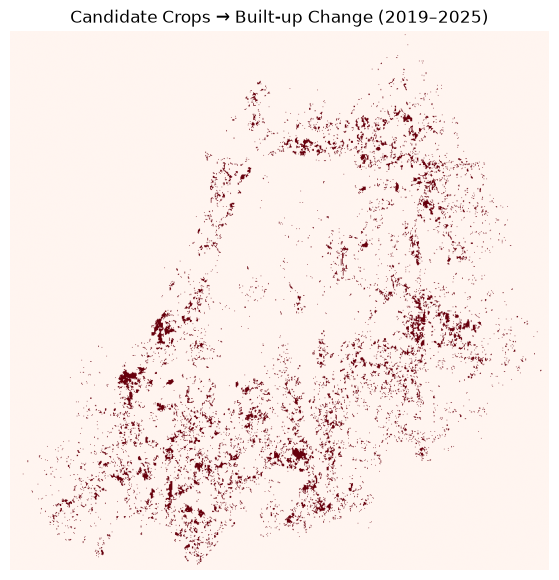

In [19]:

import numpy as np
import rasterio
import geopandas as gpd
from rasterio.features import geometry_mask
from rasterio.windows import Window
from rasterio.enums import Resampling
import matplotlib.pyplot as plt
from pathlib import Path

CHANGE_DIR = PROJECT_DIR / "outputs" / "change_detection"
CHANGE_DIR.mkdir(parents=True, exist_ok=True)

boundary_gdf = gpd.read_file(BOUNDARY_PATH)

with rasterio.open(FILES["labels_2019"]) as old_src, \
     rasterio.open(FILES["labels_2025"]) as new_src:

    boundary = boundary_gdf.to_crs(old_src.crs)

    profile = old_src.profile.copy()
    profile.update(
        count=1,
        dtype="uint8",
        nodata=255,
        compress="lzw"
    )

    change_path = CHANGE_DIR / "candidate_crops_to_builtup.tif"

    with rasterio.open(change_path, "w", **profile) as dst:
        for _, window in old_src.block_windows(1):
            old = old_src.read(1, window=window)
            new = new_src.read(1, window=window)

            r0, c0 = int(window.row_off), int(window.col_off)
            h, w = int(window.height), int(window.width)

            inside = geometry_mask(
                boundary.geometry,
                out_shape=(h, w),
                transform=rasterio.windows.transform(
                    window, old_src.transform
                ),
                invert=True,
                all_touched=False
            )

            # 1 = candidate crops-to-built-up, 0 = other
            candidate = (
                (old == 4) &
                (new == 6) &
                inside
            ).astype("uint8")

            dst.write(candidate, 1, window=window)

print("Candidate change raster saved:", change_path)

# Quick visual check at reduced resolution
with rasterio.open(change_path) as src:
    preview = src.read(
        1,
        out_shape=(800, 800),
        resampling=Resampling.nearest
    )

plt.figure(figsize=(9, 7))
plt.imshow(preview, cmap="Reds", vmin=0, vmax=1)
plt.title("Candidate Crops → Built-up Change (2019–2025)")
plt.axis("off")
plt.show()


check whether your candidate-change raster exists

In [20]:

from pathlib import Path
import numpy as np
import rasterio

CHANGE_DIR = PROJECT_DIR / "outputs" / "change_detection"
change_path = CHANGE_DIR / "candidate_crops_to_builtup.tif"

if not change_path.exists():
    print("Candidate raster not found.")
    print("Run the previous candidate-change map cell first.")
else:
    with rasterio.open(change_path) as src:
        candidate_pixels = 0
        total_pixels = 0

        for _, window in src.block_windows(1):
            arr = src.read(1, window=window)
            candidate_pixels += int((arr == 1).sum())
            total_pixels += arr.size

        print("Candidate raster:", change_path)
        print("Candidate transition pixels:", candidate_pixels)
        print("Total raster pixels:", total_pixels)


Candidate raster: E:\Punjab GeoGuardian\outputs\change_detection\candidate_crops_to_builtup.tif
Candidate transition pixels: 1303974
Total raster pixels: 37098057


Calculate the area in square kilometres

In [21]:

from pathlib import Path
import numpy as np
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling

# Input and output
candidate_path = Path(
    r"E:\Punjab GeoGuardian\outputs\change_detection\candidate_crops_to_builtup.tif"
)
projected_path = candidate_path.parent / "candidate_crops_to_builtup_UTM43N_10m.tif"

# UTM Zone 43N is suitable for Lahore
target_crs = "EPSG:32643"
pixel_size = 10  # metres

with rasterio.open(candidate_path) as src:
    transform, width, height = calculate_default_transform(
        src.crs,
        target_crs,
        src.width,
        src.height,
        *src.bounds,
        resolution=pixel_size
    )

    profile = src.profile.copy()
    profile.update(
        crs=target_crs,
        transform=transform,
        width=width,
        height=height,
        dtype="uint8",
        count=1,
        nodata=255,
        compress="lzw"
    )

    with rasterio.open(projected_path, "w", **profile) as dst:
        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=transform,
            dst_crs=target_crs,
            dst_nodata=255,
            resampling=Resampling.nearest
        )

# Count candidate pixels in the projected raster
candidate_pixels = 0
valid_pixels = 0

with rasterio.open(projected_path) as src:
    for _, window in src.block_windows(1):
        arr = src.read(1, window=window)
        candidate_pixels += int(np.count_nonzero(arr == 1))
        valid_pixels += int(np.count_nonzero(arr != 255))

candidate_area_m2 = candidate_pixels * pixel_size**2
candidate_area_km2 = candidate_area_m2 / 1_000_000

print("Projected raster:", projected_path)
print("CRS:", target_crs)
print("Pixel size:", pixel_size, "metres")
print("Candidate transition pixels:", f"{candidate_pixels:,}")
print("Valid raster pixels:", f"{valid_pixels:,}")
print(f"Estimated candidate area: {candidate_area_km2:.2f} km²")
print(f"Estimated candidate area: {candidate_area_m2 / 10_000:.2f} hectares")


Projected raster: E:\Punjab GeoGuardian\outputs\change_detection\candidate_crops_to_builtup_UTM43N_10m.tif
CRS: EPSG:32643
Pixel size: 10 metres
Candidate transition pixels: 1,108,233
Valid raster pixels: 31,517,658
Estimated candidate area: 110.82 km²
Estimated candidate area: 11082.33 hectares


Create the change-detection map

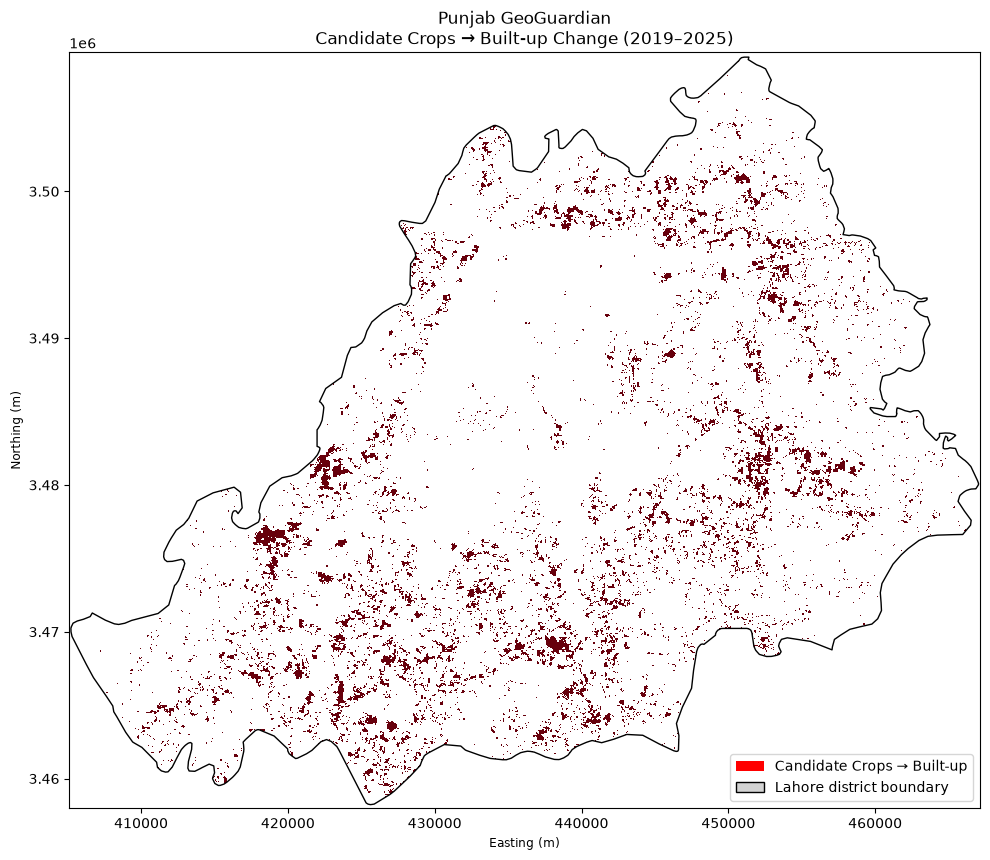

Map saved to: E:\Punjab GeoGuardian\outputs\change_detection\candidate_crops_to_builtup_map.png


In [22]:

from pathlib import Path
import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from rasterio.features import geometry_mask

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")
change_dir = PROJECT_DIR / "outputs" / "change_detection"
projected_path = change_dir / "candidate_crops_to_builtup_UTM43N_10m.tif"
boundary_path = PROJECT_DIR / "data" / "boundaries" / "Lahore_District.geojson"
map_path = change_dir / "candidate_crops_to_builtup_map.png"

# Read boundary and reproject it to match the raster
boundary_gdf = gpd.read_file(boundary_path)

with rasterio.open(projected_path) as src:
    boundary_utm = boundary_gdf.to_crs(src.crs)

    # Read a smaller version for plotting
    out_height = 1200
    out_width = max(1, int(src.width * out_height / src.height))

    arr = src.read(
        1,
        out_shape=(out_height, out_width),
        resampling=Resampling.nearest
    )

    preview_transform = src.transform * src.transform.scale(
        src.width / out_width,
        src.height / out_height
    )

    # Mask areas outside Lahore
    inside = geometry_mask(
        boundary_utm.geometry,
        out_shape=arr.shape,
        transform=preview_transform,
        invert=True
    )

    arr = np.where(inside & (arr != 255), arr, 255)

    bounds = rasterio.transform.array_bounds(
        out_height, out_width, preview_transform
    )

    # Raster bounds are in UTM metres
    extent = [bounds[0], bounds[2], bounds[1], bounds[3]]

fig, ax = plt.subplots(figsize=(10, 9))

# Grey = no candidate transition; red = candidate transition
display = np.ma.masked_where((arr == 255) | (arr == 0), arr)
ax.imshow(
    display,
    extent=extent,
    origin="upper",
    cmap="Reds",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

boundary_utm.boundary.plot(ax=ax, color="black", linewidth=1.0)

from matplotlib.patches import Patch
legend_items = [
    Patch(facecolor="red", label="Candidate Crops → Built-up"),
    Patch(facecolor="lightgrey", edgecolor="black", label="Lahore district boundary")
]
ax.legend(handles=legend_items, loc="lower right")

ax.set_title(
    "Punjab GeoGuardian\nCandidate Crops → Built-up Change (2019–2025)"
)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.tight_layout()

plt.savefig(map_path, dpi=300, bbox_inches="tight")
plt.show()

print("Map saved to:", map_path)


Yeh cell verify karegi ke projected candidate raster aur Lahore boundary spatially align hain ya nahi, aur kitne candidate pixels boundary ke andar hain.

In [23]:

from pathlib import Path
import numpy as np
import rasterio
import geopandas as gpd
from rasterio.features import geometry_mask

project_dir = Path(r"E:\Punjab GeoGuardian")

candidate_path = (
    project_dir / "outputs" / "change_detection" /
    "candidate_crops_to_builtup_UTM43N_10m.tif"
)
boundary_path = project_dir / "data" / "boundaries" / "Lahore_District.geojson"

boundary = gpd.read_file(boundary_path)

candidate_count = 0
outside_candidate_count = 0
inside_pixels = 0
inside_candidate_count = 0

with rasterio.open(candidate_path) as src:
    boundary = boundary.to_crs(src.crs)

    print("Raster CRS:", src.crs)
    print("Raster resolution:", src.res)
    print("Raster dimensions:", src.width, "x", src.height)

    for _, window in src.block_windows(1):
        arr = src.read(1, window=window)

        window_transform = rasterio.windows.transform(window, src.transform)

        inside = geometry_mask(
            boundary.geometry,
            out_shape=arr.shape,
            transform=window_transform,
            invert=True
        )

        candidate = arr == 1
        valid = arr != 255

        candidate_count += int(np.count_nonzero(candidate))
        inside_pixels += int(np.count_nonzero(inside & valid))
        inside_candidate_count += int(np.count_nonzero(candidate & inside))
        outside_candidate_count += int(np.count_nonzero(candidate & ~inside))

print("\n--- Boundary Verification ---")
print("All candidate pixels:", f"{candidate_count:,}")
print("Candidate pixels inside Lahore:", f"{inside_candidate_count:,}")
print("Candidate pixels outside Lahore:", f"{outside_candidate_count:,}")
print("Valid pixels inside Lahore:", f"{inside_pixels:,}")
print("Check complete.")


Raster CRS: EPSG:32643
Raster resolution: (10.0, 10.0)
Raster dimensions: 6203 x 5145

--- Boundary Verification ---
All candidate pixels: 1,108,233
Candidate pixels inside Lahore: 1,108,151
Candidate pixels outside Lahore: 82
Valid pixels inside Lahore: 16,885,358
Check complete.



## Step: Inspect Dynamic World Class Distribution (2019)

### Objective
In this step, we inspect the distribution of land-cover classes within Lahore District using the 2019 Dynamic World label raster.

### Why is this step important?
Before training a Random Forest model, we need to understand which land-cover classes are present and how many pixels belong to each class. This helps us identify rare classes and prepare a balanced training dataset.

### Data Used
- `Sentinel2_2019_Features.tif`: Satellite spectral bands and indices.
- `DynamicWorld_2019_Labels.tif`: Predicted land-cover labels.
- `Lahore_District.geojson`: Study area boundary.

### What does the code do?
1. Opens the satellite feature raster and the Dynamic World label raster.
2. Checks that both rasters have matching coordinate systems, dimensions, and pixel grids.
3. Uses the Lahore District boundary to include only pixels inside the study area.
4. Counts the number of pixels belonging to each Dynamic World class.
5. Prints the class IDs, names, and pixel counts.

### Dynamic World Class IDs

| Class ID | Land-cover class |
|---|---|
| 0 | Water |
| 1 | Trees |
| 2 | Grass |
| 3 | Flooded vegetation |
| 4 | Crops |
| 5 | Shrub/scrub |
| 6 | Built-up |
| 7 | Bare ground |
| 8 | Snow/ice |

### Expected Output
The code prints the number of pixels belonging to each class within Lahore District. It also confirms whether the feature and label rasters are spatially aligned.

### Important Limitation
Dynamic World labels are model predictions, not independently verified ground-truth labels. Their class counts help us understand the available data, but they do not establish classification accuracy.

### Next Step
Use the class distribution to plan memory-efficient training samples for the Random Forest model. Keep independently interpreted validation samples separate from the training data.


In [24]:

from pathlib import Path
from collections import Counter

import numpy as np
import rasterio
import geopandas as gpd
from rasterio.features import geometry_mask

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

feature_path = PROJECT_DIR / "data" / "raw" / "Sentinel2_2019_Features.tif"
label_path = PROJECT_DIR / "data" / "raw" / "DynamicWorld_2019_Labels.tif"
boundary_path = PROJECT_DIR / "data" / "boundaries" / "Lahore_District.geojson"

boundary = gpd.read_file(boundary_path)
class_counts = Counter()

with rasterio.open(feature_path) as features, \
     rasterio.open(label_path) as labels:

    boundary = boundary.to_crs(features.crs)

    print("Feature CRS:", features.crs)
    print("Label CRS:", labels.crs)
    print("Feature dimensions:", features.width, features.height)
    print("Label dimensions:", labels.width, labels.height)

    if (
        features.crs != labels.crs
        or features.transform != labels.transform
        or features.width != labels.width
        or features.height != labels.height
    ):
        raise ValueError(
            "Feature and label grids do not match. Stop before training."
        )

    for _, window in features.block_windows(1):
        label_array = labels.read(1, window=window)

        inside = geometry_mask(
            boundary.geometry,
            out_shape=label_array.shape,
            transform=rasterio.windows.transform(window, features.transform),
            invert=True
        )

        # Count labels only inside Lahore
        values, counts = np.unique(label_array[inside], return_counts=True)

        for value, count in zip(values, counts):
            if value != 255:
                class_counts[int(value)] += int(count)

print("\n2019 Dynamic World label counts inside Lahore:")
class_names = {
    0: "Water",
    1: "Trees",
    2: "Grass",
    3: "Flooded vegetation",
    4: "Crops",
    5: "Shrub/scrub",
    6: "Built-up",
    7: "Bare ground",
    8: "Snow/ice"
}

for class_id in sorted(class_counts):
    print(
        f"{class_id} - {class_names.get(class_id, 'Unknown')}: "
        f"{class_counts[class_id]:,}"
    )


Feature CRS: EPSG:4326
Label CRS: EPSG:4326
Feature dimensions: 7233 5129
Label dimensions: 7233 5129

2019 Dynamic World label counts inside Lahore:
0 - Water: 329,650
1 - Trees: 106,665
2 - Grass: 17,987
3 - Flooded vegetation: 14,188
4 - Crops: 10,860,440
5 - Shrub/scrub: 166,210
6 - Built-up: 7,584,967
7 - Bare ground: 790,504
8 - Snow/ice: 88


## Step: Analyze 2025 Dynamic World Class Distribution

### Objective
Count the predicted land-cover classes inside Lahore District for 2025.

### Input Data
- `DynamicWorld_2025_Labels.tif`
- `Sentinel2_2025_Features.tif`
- `Lahore_District.geojson`

### What This Code Does
1. Opens the 2025 feature and label rasters.
2. Checks whether their CRS, dimensions, and spatial transforms match.
3. Masks pixels outside Lahore District.
4. Counts pixels belonging to each Dynamic World class.
5. Displays the results for further analysis.

### Class IDs
- 0: Water
- 1: Trees
- 2: Grass
- 3: Flooded vegetation
- 4: Crops
- 5: Shrub/Scrub
- 6: Built-up
- 7: Bare ground
- 8: Snow/Ice

### Important Limitation
Dynamic World labels are model-generated predictions, not independently verified ground truth.

### Next Step
Compare the 2019 and 2025 class distributions before preparing Random Forest training samples.

In [25]:
from pathlib import Path
from collections import Counter

import numpy as np
import rasterio
import geopandas as gpd
from rasterio.features import geometry_mask
from rasterio.windows import transform as window_transform

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

feature_path = PROJECT_DIR / "data" / "raw" / "Sentinel2_2025_Features.tif"
label_path = PROJECT_DIR / "data" / "raw" / "DynamicWorld_2025_Labels.tif"
boundary_path = PROJECT_DIR / "data" / "boundaries" / "Lahore_District.geojson"

boundary = gpd.read_file(boundary_path)
class_counts = Counter()

class_names = {
    0: "Water",
    1: "Trees",
    2: "Grass",
    3: "Flooded vegetation",
    4: "Crops",
    5: "Shrub/scrub",
    6: "Built-up",
    7: "Bare ground",
    8: "Snow/ice"
}

with rasterio.open(feature_path) as features, rasterio.open(label_path) as labels:

    print("Feature CRS:", features.crs)
    print("Label CRS:", labels.crs)
    print("Feature dimensions:", features.width, features.height)
    print("Label dimensions:", labels.width, labels.height)

    if (
        features.crs != labels.crs
        or features.transform != labels.transform
        or features.width != labels.width
        or features.height != labels.height
    ):
        raise ValueError(
            "Feature and label grids do not match. "
            "Stop before proceeding."
        )

    boundary = boundary.to_crs(features.crs)

    for _, window in features.block_windows(1):

        label_array = labels.read(1, window=window)

        inside = geometry_mask(
            boundary.geometry,
            out_shape=label_array.shape,
            transform=window_transform(window, features.transform),
            invert=True
        )

        values, counts = np.unique(
            label_array[inside],
            return_counts=True
        )

        for value, count in zip(values, counts):
            if value in class_names:
                class_counts[int(value)] += int(count)

print("\n2025 Dynamic World label counts inside Lahore:")
for class_id in sorted(class_names):
    print(
        f"{class_id} - {class_names[class_id]}: "
        f"{class_counts[class_id]:,}"
    )
    

Feature CRS: EPSG:4326
Label CRS: EPSG:4326
Feature dimensions: 7233 5129
Label dimensions: 7233 5129

2025 Dynamic World label counts inside Lahore:
0 - Water: 219,011
1 - Trees: 171,484
2 - Grass: 35,988
3 - Flooded vegetation: 8,393
4 - Crops: 9,622,217
5 - Shrub/scrub: 178,646
6 - Built-up: 9,190,160
7 - Bare ground: 444,773
8 - Snow/ice: 27


## Step: Compare Land-Cover Distribution (2019 vs 2025)

**Objective:** Compare predicted land-cover pixel counts and percentages for both years inside Lahore District.

**Input:** The 2019 and 2025 Dynamic World label rasters and Lahore boundary.

**Output:** A comparison table showing pixel counts, percentages, and percentage-point changes.

**Limitation:** These are Dynamic World predictions, not independently verified ground truth. This comparison alone does not prove actual farmland loss.

In [30]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
from rasterio.features import geometry_mask
from rasterio.windows import transform as window_transform

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

feature_2019_path = PROJECT_DIR / "data" / "raw" / "Sentinel2_2019_Features.tif"
label_2019_path = PROJECT_DIR / "data" / "raw" / "DynamicWorld_2019_Labels.tif"

feature_2025_path = PROJECT_DIR / "data" / "raw" / "Sentinel2_2025_Features.tif"
label_2025_path = PROJECT_DIR / "data" / "raw" / "DynamicWorld_2025_Labels.tif"

boundary_path = PROJECT_DIR / "data" / "boundaries" / "Lahore_District.geojson"

class_names = {
    0: "Water",
    1: "Trees",
    2: "Grass",
    3: "Flooded vegetation",
    4: "Crops",
    5: "Shrub/Scrub",
    6: "Built-up",
    7: "Bare ground",
    8: "Snow/Ice"
}

boundary = gpd.read_file(boundary_path)
counts_by_year = {}

with (
    rasterio.open(feature_2019_path) as f19,
    rasterio.open(label_2019_path) as l19,
    rasterio.open(feature_2025_path) as f25,
    rasterio.open(label_2025_path) as l25
):
    # Check that all rasters use the same grid.
    reference = (f19.crs, f19.transform, f19.width, f19.height)

    for dataset in (l19, f25, l25):
        current = (
            dataset.crs,
            dataset.transform,
            dataset.width,
            dataset.height
        )
        if current != reference:
            raise ValueError("Raster grids do not match. Stop and inspect alignment.")

    boundary = boundary.to_crs(f19.crs)
    counts_by_year = {
        2019: {class_id: 0 for class_id in class_names},
        2025: {class_id: 0 for class_id in class_names}
    }

    # Read in blocks to avoid loading the full rasters into RAM.
    for _, window in f19.block_windows(1):
        a19 = l19.read(1, window=window)
        a25 = l25.read(1, window=window)

        inside = geometry_mask(
            boundary.geometry,
            out_shape=a19.shape,
            transform=window_transform(window, f19.transform),
            invert=True
        )

        for year, array in ((2019, a19), (2025, a25)):
            values, counts = np.unique(array[inside], return_counts=True)

            for value, count in zip(values, counts):
                if int(value) in class_names:
                    counts_by_year[year][int(value)] += int(count)

total_2019 = sum(counts_by_year[2019].values())
total_2025 = sum(counts_by_year[2025].values())

rows = []

for class_id, class_name in class_names.items():
    count19 = counts_by_year[2019][class_id]
    count25 = counts_by_year[2025][class_id]

    pct19 = count19 / total_2019 * 100 if total_2019 else 0
    pct25 = count25 / total_2025 * 100 if total_2025 else 0

    rows.append({
        "Class": class_name,
        "2019 Pixels": count19,
        "2025 Pixels": count25,
        "Pixel Difference": count25 - count19,
        "2019 (%)": round(pct19, 3),
        "2025 (%)": round(pct25, 3),
        "Change (percentage points)": round(pct25 - pct19, 3)
    })



print("Total classified pixels in 2019:", f"{total_2019:,}")
print("Total classified pixels in 2025:", f"{total_2025:,}")



from IPython.display import display as show_table

print("Total classified pixels in 2019:", f"{total_2019:,}")
print("Total classified pixels in 2025:", f"{total_2025:,}")

show_table(comparison_df)

from IPython.display import display as show_table

print("Total classified pixels in 2019:", f"{total_2019:,}")
print("Total classified pixels in 2025:", f"{total_2025:,}")

show_table(comparison_df)

Total classified pixels in 2019: 19,870,699
Total classified pixels in 2025: 19,870,699
Total classified pixels in 2019: 19,870,699
Total classified pixels in 2025: 19,870,699


,Class,2019 Pixels,2025 Pixels,Pixel Difference,2019 (%),2025 (%),Change (percentage points)
0,Water,329650,219011,-110639,1.659,1.102,-0.557
1,Trees,106665,171484,64819,0.537,0.863,0.326
2,Grass,17987,35988,18001,0.091,0.181,0.091
3,Flooded vegetation,14188,8393,-5795,0.071,0.042,-0.029
4,Crops,10860440,9622217,-1238223,54.656,48.424,-6.231
5,Shrub/Scrub,166210,178646,12436,0.836,0.899,0.063
6,Built-up,7584967,9190160,1605193,38.172,46.250,8.078
7,Bare ground,790504,444773,-345731,3.978,2.238,-1.740
8,Snow/Ice,88,27,-61,0.000,0.000,-0.000


Total classified pixels in 2019: 19,870,699
Total classified pixels in 2025: 19,870,699


,Class,2019 Pixels,2025 Pixels,Pixel Difference,2019 (%),2025 (%),Change (percentage points)
0,Water,329650,219011,-110639,1.659,1.102,-0.557
1,Trees,106665,171484,64819,0.537,0.863,0.326
2,Grass,17987,35988,18001,0.091,0.181,0.091
3,Flooded vegetation,14188,8393,-5795,0.071,0.042,-0.029
4,Crops,10860440,9622217,-1238223,54.656,48.424,-6.231
5,Shrub/Scrub,166210,178646,12436,0.836,0.899,0.063
6,Built-up,7584967,9190160,1605193,38.172,46.250,8.078
7,Bare ground,790504,444773,-345731,3.978,2.238,-1.740
8,Snow/Ice,88,27,-61,0.000,0.000,-0.000


## Step: Prepare Balanced Training Samples

**Objective:** Create training samples for a Random Forest land-cover classifier using 2019 Sentinel-2 features and Dynamic World labels.

**Features:** B2, B3, B4, B8, B11, B12, NDVI, and NDBI.

**Classes:** Water, Trees, Grass, Flooded Vegetation, Crops, Shrub/Scrub, Built-up, and Bare Ground.

**Method:** Sample up to 1,500 pixels per class to limit memory usage.

**Limitation:** Dynamic World provides weak training labels, not independently verified ground truth. A random train/test split is only a preliminary internal evaluation, not independent validation.

In [31]:
from pathlib import Path
from collections import defaultdict

import numpy as np
import rasterio
import geopandas as gpd
from rasterio.features import geometry_mask
from rasterio.windows import transform as window_transform

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

feature_path = PROJECT_DIR / "data" / "raw" / "Sentinel2_2019_Features.tif"
label_path = PROJECT_DIR / "data" / "raw" / "DynamicWorld_2019_Labels.tif"
boundary_path = PROJECT_DIR / "data" / "boundaries" / "Lahore_District.geojson"

SAMPLES_PER_CLASS = 1500
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

class_names = {
    0: "Water",
    1: "Trees",
    2: "Grass",
    3: "Flooded vegetation",
    4: "Crops",
    5: "Shrub/Scrub",
    6: "Built-up",
    7: "Bare ground"
}

boundary = gpd.read_file(boundary_path)
sample_X = defaultdict(list)
sample_y = defaultdict(list)

with rasterio.open(feature_path) as src, rasterio.open(label_path) as labels:

    if (
        src.crs != labels.crs
        or src.transform != labels.transform
        or src.width != labels.width
        or src.height != labels.height
    ):
        raise ValueError("Feature and label rasters do not align.")

    boundary = boundary.to_crs(src.crs)

    for _, window in src.block_windows(1):
        features = src.read(window=window).astype(np.float32)
        labels_array = labels.read(1, window=window)

        inside = geometry_mask(
            boundary.geometry,
            out_shape=labels_array.shape,
            transform=window_transform(window, src.transform),
            invert=True
        )

        valid = inside & np.all(np.isfinite(features), axis=0)

        for class_id in class_names:
            remaining = SAMPLES_PER_CLASS - len(sample_y[class_id])

            if remaining <= 0:
                continue

            positions = np.argwhere(
                valid & (labels_array == class_id)
            )

            if len(positions) == 0:
                continue

            take = min(remaining, len(positions))
            selected = positions[
                rng.choice(len(positions), size=take, replace=False)
            ]

            for row, col in selected:
                sample_X[class_id].append(features[:, row, col])
                sample_y[class_id].append(class_id)

X_list = []
y_list = []

for class_id, name in class_names.items():
    X_list.extend(sample_X[class_id])
    y_list.extend(sample_y[class_id])
    print(f"{name}: {len(sample_y[class_id]):,} samples")

X = np.asarray(X_list, dtype=np.float32)
y = np.asarray(y_list, dtype=np.uint8)

print("\nFeature array shape:", X.shape)
print("Label array shape:", y.shape)

if len(X) == 0 or len(np.unique(y)) < 2:
    raise ValueError("Insufficient samples. Check raster labels and paths.")

Water: 1,500 samples
Trees: 1,500 samples
Grass: 1,500 samples
Flooded vegetation: 1,500 samples
Crops: 1,500 samples
Shrub/Scrub: 1,500 samples
Built-up: 1,500 samples
Bare ground: 1,500 samples

Feature array shape: (12000, 8)
Label array shape: (12000,)


## Step: Train the Random Forest Classifier

**Objective:** Train a machine-learning model to classify land cover into eight classes.

**Input:** `X` contains 12,000 samples with 8 satellite features; `y` contains their Dynamic World labels.

**Method:** Split the samples into training and test sets, then train a Random Forest with 150 decision trees.

**Output:** A trained classifier, classification report, and confusion matrix.

**Limitation:** The test samples use the same source of predicted labels as the training samples. Results do not establish independent real-world accuracy.

In [32]:
from pathlib import Path
import joblib
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")
MODEL_DIR = PROJECT_DIR / "outputs" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

class_names = {
    0: "Water",
    1: "Trees",
    2: "Grass",
    3: "Flooded vegetation",
    4: "Crops",
    5: "Shrub/Scrub",
    6: "Built-up",
    7: "Bare ground"
}

# Split samples for preliminary evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

# Train the classifier.
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Evaluate on the held-out random samples.
y_pred = rf_model.predict(X_test)

print("\nPreliminary test accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=list(class_names.keys()),
        target_names=list(class_names.values()),
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred,
        labels=list(class_names.keys())
    )
)

# Save the trained model.
model_path = MODEL_DIR / "Punjab_GeoGuardian_RandomForest.joblib"
joblib.dump(rf_model, model_path)

print("\nModel saved to:", model_path)

Training samples: 9600
Test samples: 2400

Preliminary test accuracy: 0.8558

Classification Report:
                    precision    recall  f1-score   support

             Water       0.97      0.86      0.91       300
             Trees       0.90      0.91      0.91       300
             Grass       0.85      0.86      0.85       300
Flooded vegetation       0.80      0.83      0.81       300
             Crops       0.81      0.91      0.85       300
       Shrub/Scrub       0.80      0.85      0.82       300
          Built-up       0.84      0.82      0.83       300
       Bare ground       0.90      0.82      0.86       300

          accuracy                           0.86      2400
         macro avg       0.86      0.86      0.86      2400
      weighted avg       0.86      0.86      0.86      2400

Confusion Matrix:
[[257   7   5  19  10   0   1   1]
 [  1 274   0  16   3   1   5   0]
 [  0   0 257   9  17  11   4   2]
 [  3   9  15 248   9   8   5   3]
 [  0   0   9   3 

## Step: Generate Land-Cover Classification Maps

**Objective:** Apply the trained Random Forest to the complete Sentinel-2 rasters for 2019 and 2025.

**Method:** Process raster blocks one at a time to reduce memory use. Pixels outside Lahore or with invalid features will be marked NoData (255).

**Output:** Two classified GeoTIFF files, each containing class IDs 0–7.

**Limitation:** The maps are predictions from a model trained using Dynamic World labels. They require independent validation before being treated as reliable land-cover maps.

In [33]:
from pathlib import Path
import numpy as np
import rasterio
import geopandas as gpd

from rasterio.features import geometry_mask
from rasterio.windows import transform as window_transform

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

feature_paths = {
    2019: PROJECT_DIR / "data" / "raw" / "Sentinel2_2019_Features.tif",
    2025: PROJECT_DIR / "data" / "raw" / "Sentinel2_2025_Features.tif"
}

boundary_path = PROJECT_DIR / "data" / "boundaries" / "Lahore_District.geojson"

OUTPUT_DIR = PROJECT_DIR / "outputs" / "classifications"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

boundary = gpd.read_file(boundary_path)

# Load the saved model so this cell can be run independently
# after the model has been trained and saved.
rf_model = joblib.load(
    PROJECT_DIR / "outputs" / "models" / "Punjab_GeoGuardian_RandomForest.joblib"
)

for year, feature_path in feature_paths.items():

    output_path = OUTPUT_DIR / f"RandomForest_LandCover_{year}.tif"

    with rasterio.open(feature_path) as src:

        year_boundary = boundary.to_crs(src.crs)

        profile = src.profile.copy()
        profile.update(
            count=1,
            dtype="uint8",
            nodata=255,
            compress="lzw"
        )

        class_pixel_counts = {class_id: 0 for class_id in class_names}

        with rasterio.open(output_path, "w", **profile) as dst:

            for _, window in src.block_windows(1):

                features = src.read(
                    window=window
                ).astype(np.float32)

                inside = geometry_mask(
                    year_boundary.geometry,
                    out_shape=(int(window.height), int(window.width)),
                    transform=window_transform(window, src.transform),
                    invert=True
                )

                valid = inside & np.all(np.isfinite(features), axis=0)

                result = np.full(
                    valid.shape,
                    255,
                    dtype=np.uint8
                )

                if np.any(valid):
                    pixel_features = features[:, valid].T
                    predictions = rf_model.predict(pixel_features).astype(np.uint8)

                    result[valid] = predictions

                    values, counts = np.unique(
                        predictions,
                        return_counts=True
                    )

                    for value, count in zip(values, counts):
                        class_pixel_counts[int(value)] += int(count)

                dst.write(result, 1, window=window)

    print(f"\n{year} classification saved:", output_path)

    for class_id, class_name in class_names.items():
        print(f"{class_name}: {class_pixel_counts[class_id]:,} pixels")


2019 classification saved: E:\Punjab GeoGuardian\outputs\classifications\RandomForest_LandCover_2019.tif
Water: 189,731 pixels
Trees: 908,826 pixels
Grass: 2,025,432 pixels
Flooded vegetation: 3,193,992 pixels
Crops: 1,541,546 pixels
Shrub/Scrub: 1,112,876 pixels
Built-up: 10,438,486 pixels
Bare ground: 459,810 pixels

2025 classification saved: E:\Punjab GeoGuardian\outputs\classifications\RandomForest_LandCover_2025.tif
Water: 126,953 pixels
Trees: 970,612 pixels
Grass: 1,058,094 pixels
Flooded vegetation: 2,425,986 pixels
Crops: 1,372,827 pixels
Shrub/Scrub: 1,514,567 pixels
Built-up: 12,113,493 pixels
Bare ground: 288,167 pixels


## Step: Detect Possible Cropland-to-Built-Up Change

**Objective:** Find pixels predicted as Crops in 2019 and Built-up in 2025.

**Rule:** 2019 class ID = 4 and 2025 class ID = 6.

**Output:** A change raster with 1 for candidate change, 0 for other valid pixels, and 255 for NoData.

**Limitation:** A detected transition is a candidate, not proof of farmland conversion. Differences in classification quality, season, and satellite observations can create false changes.

In [34]:
from pathlib import Path
import numpy as np
import rasterio

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

old_path = (
    PROJECT_DIR / "outputs" / "classifications"
    / "RandomForest_LandCover_2019.tif"
)

new_path = (
    PROJECT_DIR / "outputs" / "classifications"
    / "RandomForest_LandCover_2025.tif"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "change_detection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / "RF_Candidate_Crops_to_BuiltUp.tif"

with rasterio.open(old_path) as old, rasterio.open(new_path) as new:

    if (
        old.crs != new.crs
        or old.transform != new.transform
        or old.width != new.width
        or old.height != new.height
    ):
        raise ValueError("2019 and 2025 classified rasters do not align.")

    profile = old.profile.copy()
    profile.update(
        count=1,
        dtype="uint8",
        nodata=255,
        compress="lzw"
    )

    total_candidates = 0
    total_valid = 0

    with rasterio.open(output_path, "w", **profile) as dst:

        for _, window in old.block_windows(1):

            a = old.read(1, window=window)
            b = new.read(1, window=window)

            valid = (a != 255) & (b != 255)

            change = np.full(a.shape, 255, dtype=np.uint8)
            change[valid] = 0

            candidates = valid & (a == 4) & (b == 6)
            change[candidates] = 1

            total_candidates += int(candidates.sum())
            total_valid += int(valid.sum())

            dst.write(change, 1, window=window)

print("Change raster saved:", output_path)
print("Valid comparison pixels:", f"{total_valid:,}")
print("Candidate crops-to-built-up pixels:", f"{total_candidates:,}")

if total_valid:
    print(
        "Candidate share of valid pixels:",
        round(total_candidates / total_valid * 100, 3),
        "%"
    )

Change raster saved: E:\Punjab GeoGuardian\outputs\change_detection\RF_Candidate_Crops_to_BuiltUp.tif
Valid comparison pixels: 19,870,699
Candidate crops-to-built-up pixels: 706,689
Candidate share of valid pixels: 3.556 %


## Step: Verify Classification Outputs

**Objective:** Confirm that the model, classified maps, and change raster exist and have the expected spatial properties.

**Checks:** File existence, CRS, dimensions, pixel values, and NoData counts.

**Next:** Create maps, validate the predictions against independently checked reference points, and analyze classification errors before reporting area estimates.

In [35]:
from pathlib import Path
import numpy as np
import rasterio

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

check_paths = [
    PROJECT_DIR / "outputs" / "classifications" / "RandomForest_LandCover_2019.tif",
    PROJECT_DIR / "outputs" / "classifications" / "RandomForest_LandCover_2025.tif",
    PROJECT_DIR / "outputs" / "change_detection" / "RF_Candidate_Crops_to_BuiltUp.tif"
]

for path in check_paths:
    print("\nFile:", path)

    if not path.exists():
        print("MISSING")
        continue

    with rasterio.open(path) as src:
        print("CRS:", src.crs)
        print("Dimensions:", f"{src.width} x {src.height}")
        print("Resolution:", src.res)
        print("NoData:", src.nodata)

        counts = {}

        for _, window in src.block_windows(1):
            array = src.read(1, window=window)
            values, frequencies = np.unique(array, return_counts=True)

            for value, frequency in zip(values, frequencies):
                counts[int(value)] = counts.get(int(value), 0) + int(frequency)

        print("Pixel counts:")
        for value in sorted(counts):
            print(f"  Value {value}: {counts[value]:,}")


File: E:\Punjab GeoGuardian\outputs\classifications\RandomForest_LandCover_2019.tif
CRS: EPSG:4326
Dimensions: 7233 x 5129
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
NoData: 255.0
Pixel counts:
  Value 0: 189,731
  Value 1: 908,826
  Value 2: 2,025,432
  Value 3: 3,193,992
  Value 4: 1,541,546
  Value 5: 1,112,876
  Value 6: 10,438,486
  Value 7: 459,810
  Value 255: 17,227,358

File: E:\Punjab GeoGuardian\outputs\classifications\RandomForest_LandCover_2025.tif
CRS: EPSG:4326
Dimensions: 7233 x 5129
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
NoData: 255.0
Pixel counts:
  Value 0: 126,953
  Value 1: 970,612
  Value 2: 1,058,094
  Value 3: 2,425,986
  Value 4: 1,372,827
  Value 5: 1,514,567
  Value 6: 12,113,493
  Value 7: 288,167
  Value 255: 17,227,358

File: E:\Punjab GeoGuardian\outputs\change_detection\RF_Candidate_Crops_to_BuiltUp.tif
CRS: EPSG:4326
Dimensions: 7233 x 5129
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
NoData: 255.0
Pixe

In [36]:

from pathlib import Path
import numpy as np
import rasterio

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

change_path = (
    PROJECT_DIR / "outputs" / "change_detection" /
    "RF_Candidate_Crops_to_BuiltUp.tif"
)

with rasterio.open(change_path) as src:
    print("CRS:", src.crs)
    print("Dimensions:", src.width, "x", src.height)
    print("NoData:", src.nodata)

    counts = {0: 0, 1: 0, 255: 0}

    for _, window in src.block_windows(1):
        arr = src.read(1, window=window)

        values, frequencies = np.unique(
            arr, return_counts=True
        )

        for value, frequency in zip(values, frequencies):
            counts[int(value)] = (
                counts.get(int(value), 0) + int(frequency)
            )

print("\nChange raster pixel counts:")
print("No candidate change (0):", f"{counts.get(0, 0):,}")
print("Candidate crops-to-built-up (1):", f"{counts.get(1, 0):,}")
print("NoData (255):", f"{counts.get(255, 0):,}")


CRS: EPSG:4326
Dimensions: 7233 x 5129
NoData: 255.0

Change raster pixel counts:
No candidate change (0): 19,164,010
Candidate crops-to-built-up (1): 706,689
NoData (255): 17,227,358


Generate the three maps

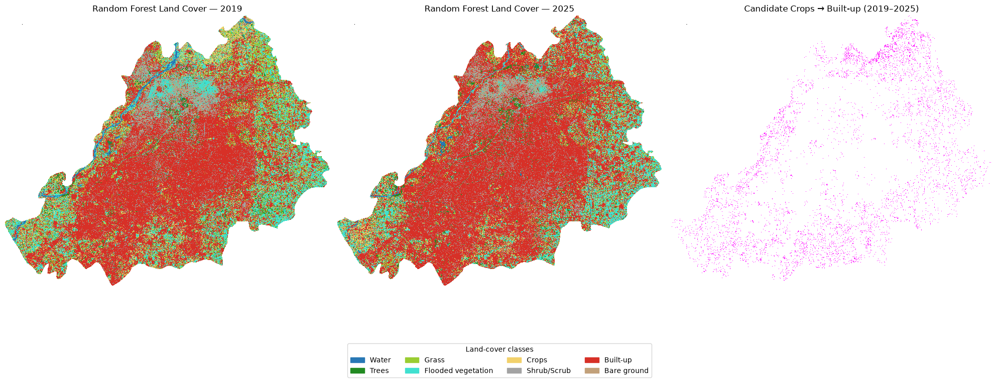

Visualization saved to: E:\Punjab GeoGuardian\outputs\classifications\LandCover_and_Change_Maps.png


In [37]:

from pathlib import Path
import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.enums import Resampling

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

classification_paths = {
    2019: PROJECT_DIR / "outputs" / "classifications" /
          "RandomForest_LandCover_2019.tif",
    2025: PROJECT_DIR / "outputs" / "classifications" /
          "RandomForest_LandCover_2025.tif"
}

change_path = (
    PROJECT_DIR / "outputs" / "change_detection" /
    "RF_Candidate_Crops_to_BuiltUp.tif"
)

boundary_path = (
    PROJECT_DIR / "data" / "boundaries" /
    "Lahore_District.geojson"
)

# Land-cover class names
class_names = {
    0: "Water",
    1: "Trees",
    2: "Grass",
    3: "Flooded vegetation",
    4: "Crops",
    5: "Shrub/Scrub",
    6: "Built-up",
    7: "Bare ground"
}

# Consistent colors for each class
class_colors = [
    "#2878B5",  # Water
    "#228B22",  # Trees
    "#9ACD32",  # Grass
    "#40E0D0",  # Flooded vegetation
    "#F2D16B",  # Crops
    "#A3A3A3",  # Shrub/Scrub
    "#D73027",  # Built-up
    "#C2A17A"   # Bare ground
]

boundary = gpd.read_file(boundary_path)

def read_small_raster(path, max_size=1400):
    """Read a smaller copy for faster plotting, preserving class IDs."""
    with rasterio.open(path) as src:
        scale = min(1, max_size / max(src.width, src.height))
        height = max(1, int(src.height * scale))
        width = max(1, int(src.width * scale))

        arr = src.read(
            1,
            out_shape=(height, width),
            resampling=Resampling.nearest
        )

        transform = src.transform * src.transform.scale(
            src.width / width,
            src.height / height
        )

        return arr, src.crs, transform

# Read classifications and change raster
map_2019, crs, transform_2019 = read_small_raster(
    classification_paths[2019]
)
map_2025, _, _ = read_small_raster(classification_paths[2025])
change_map, _, _ = read_small_raster(change_path)

# Convert NoData to transparent
map_2019 = np.ma.masked_equal(map_2019, 255)
map_2025 = np.ma.masked_equal(map_2025, 255)
change_map = np.ma.masked_equal(change_map, 255)

# Boundary in the raster CRS
boundary_plot = boundary.to_crs(crs)

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

# Classification maps
for ax, arr, year in [
    (axes[0], map_2019, 2019),
    (axes[1], map_2025, 2025)
]:
    ax.imshow(
        arr,
        cmap=plt.matplotlib.colors.ListedColormap(class_colors),
        vmin=0,
        vmax=7,
        interpolation="nearest"
    )
    boundary_plot.boundary.plot(
        ax=ax, color="black", linewidth=0.5
    )
    ax.set_title(f"Random Forest Land Cover — {year}")
    ax.axis("off")

# Change map: 1 = candidate crops-to-built-up
change_cmap = plt.matplotlib.colors.ListedColormap(["#FF00FF"])
axes[2].imshow(
    np.ma.masked_where(change_map != 1, change_map),
    cmap=change_cmap,
    vmin=1,
    vmax=1,
    interpolation="nearest"
)
boundary_plot.boundary.plot(
    ax=axes[2], color="black", linewidth=0.5
)
axes[2].set_title("Candidate Crops → Built-up (2019–2025)")
axes[2].axis("off")

# Shared land-cover legend
legend_items = [
    plt.matplotlib.patches.Patch(
        color=class_colors[class_id],
        label=class_name
    )
    for class_id, class_name in class_names.items()
]

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=4,
    title="Land-cover classes"
)

plt.tight_layout(rect=[0, 0.14, 1, 1])

# Save visualization
figure_path = (
    PROJECT_DIR / "outputs" / "classifications" /
    "LandCover_and_Change_Maps.png"
)
plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Visualization saved to:", figure_path)


Reproject change raster to a 10 m grid

In [38]:

from pathlib import Path
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

source_path = (
    PROJECT_DIR / "outputs" / "change_detection" /
    "RF_Candidate_Crops_to_BuiltUp.tif"
)

output_path = (
    PROJECT_DIR / "outputs" / "change_detection" /
    "RF_Candidate_Crops_to_BuiltUp_UTM43N.tif"
)

target_crs = "EPSG:32643"

with rasterio.open(source_path) as src:
    transform, width, height = calculate_default_transform(
        src.crs,
        target_crs,
        src.width,
        src.height,
        *src.bounds,
        resolution=10
    )

    profile = src.profile.copy()
    profile.update(
        crs=target_crs,
        transform=transform,
        width=width,
        height=height,
        dtype="uint8",
        nodata=255,
        compress="lzw"
    )

    with rasterio.open(output_path, "w", **profile) as dst:
        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=transform,
            dst_crs=target_crs,
            dst_nodata=255,
            resampling=Resampling.nearest
        )

print("Reprojected change raster saved:", output_path)

with rasterio.open(output_path) as check:
    print("CRS:", check.crs)
    print("Resolution:", check.res)
    print("Dimensions:", check.width, "x", check.height)
    print("NoData:", check.nodata)


Reprojected change raster saved: E:\Punjab GeoGuardian\outputs\change_detection\RF_Candidate_Crops_to_BuiltUp_UTM43N.tif
CRS: EPSG:32643
Resolution: (10.0, 10.0)
Dimensions: 6203 x 5145
NoData: 255.0


Markdown cell: Calculate candidate area

In [39]:

from pathlib import Path
import numpy as np
import rasterio
import geopandas as gpd

from rasterio.features import geometry_mask
from rasterio.windows import transform as window_transform

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

change_path = (
    PROJECT_DIR / "outputs" / "change_detection" /
    "RF_Candidate_Crops_to_BuiltUp_UTM43N.tif"
)

boundary_path = (
    PROJECT_DIR / "data" / "boundaries" /
    "Lahore_District.geojson"
)

boundary = gpd.read_file(boundary_path)

candidate_pixels = 0
valid_pixels_inside = 0
pixels_outside_boundary = 0

with rasterio.open(change_path) as src:

    boundary_utm = boundary.to_crs(src.crs)

    pixel_width = abs(src.transform.a)
    pixel_height = abs(src.transform.e)
    pixel_area_m2 = pixel_width * pixel_height

    for _, window in src.block_windows(1):

        arr = src.read(1, window=window)

        inside = geometry_mask(
            boundary_utm.geometry,
            out_shape=(int(window.height), int(window.width)),
            transform=window_transform(window, src.transform),
            invert=True
        )

        valid = arr != 255
        candidates = arr == 1

        valid_pixels_inside += int(np.count_nonzero(inside & valid))
        candidate_pixels += int(np.count_nonzero(inside & candidates))
        pixels_outside_boundary += int(
            np.count_nonzero((~inside) & candidates)
        )

area_m2 = candidate_pixels * pixel_area_m2
area_km2 = area_m2 / 1_000_000

print("Pixel resolution:", pixel_width, "m x", pixel_height, "m")
print("Area per pixel:", pixel_area_m2, "m²")
print("Valid pixels inside Lahore:", f"{valid_pixels_inside:,}")
print("Candidate pixels inside Lahore:", f"{candidate_pixels:,}")
print("Candidate pixels outside boundary:", f"{pixels_outside_boundary:,}")
print(f"Candidate area inside Lahore: {area_km2:.2f} km²")
print(f"Candidate share of valid pixels: "
      f"{candidate_pixels / valid_pixels_inside * 100:.2f}%")


Pixel resolution: 10.0 m x 10.0 m
Area per pixel: 100.0 m²
Valid pixels inside Lahore: 16,882,521
Candidate pixels inside Lahore: 600,185
Candidate pixels outside boundary: 177
Candidate area inside Lahore: 60.02 km²
Candidate share of valid pixels: 3.56%


Compare Random Forest with Dynamic World

In [40]:

from pathlib import Path
import numpy as np
import rasterio
import geopandas as gpd

from rasterio.features import geometry_mask
from rasterio.windows import transform as window_transform

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

boundary = gpd.read_file(
    PROJECT_DIR / "data" / "boundaries" / "Lahore_District.geojson"
)

pairs = {
    2019: (
        PROJECT_DIR / "outputs" / "classifications" /
        "RandomForest_LandCover_2019.tif",
        PROJECT_DIR / "data" / "raw" /
        "DynamicWorld_2019_Labels.tif"
    ),
    2025: (
        PROJECT_DIR / "outputs" / "classifications" /
        "RandomForest_LandCover_2025.tif",
        PROJECT_DIR / "data" / "raw" /
        "DynamicWorld_2025_Labels.tif"
    )
}

for year, (rf_path, dw_path) in pairs.items():

    total = 0
    agree = 0

    with rasterio.open(rf_path) as rf, rasterio.open(dw_path) as dw:

        if (
            rf.crs != dw.crs
            or rf.width != dw.width
            or rf.height != dw.height
            or rf.transform != dw.transform
        ):
            raise ValueError(
                f"{year}: RF and Dynamic World grids do not match."
            )

        year_boundary = boundary.to_crs(rf.crs)

        for _, window in rf.block_windows(1):

            rf_arr = rf.read(1, window=window)
            dw_arr = dw.read(1, window=window)

            inside = geometry_mask(
                year_boundary.geometry,
                out_shape=(int(window.height), int(window.width)),
                transform=window_transform(window, rf.transform),
                invert=True
            )

            valid = (
                inside
                & (rf_arr != 255)
                & (dw_arr != 255)
                & (dw_arr >= 0)
                & (dw_arr <= 7)
            )

            total += int(np.count_nonzero(valid))
            agree += int(np.count_nonzero(
                valid & (rf_arr == dw_arr)
            ))

    agreement = (agree / total * 100) if total else 0

    print(f"\n{year} comparison")
    print("Compared pixels:", f"{total:,}")
    print("Matching predictions:", f"{agree:,}")
    print(f"Agreement with Dynamic World: {agreement:.2f}%")



2019 comparison
Compared pixels: 19,870,611
Matching predictions: 7,419,368
Agreement with Dynamic World: 37.34%

2025 comparison
Compared pixels: 19,870,672
Matching predictions: 8,797,679
Agreement with Dynamic World: 44.27%


class-wise agreement check

In [1]:

from pathlib import Path
import numpy as np
import rasterio
import geopandas as gpd
import pandas as pd

from rasterio.features import geometry_mask
from rasterio.windows import transform as window_transform
from sklearn.metrics import confusion_matrix, classification_report

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

boundary = gpd.read_file(
    PROJECT_DIR / "data" / "boundaries" / "Lahore_District.geojson"
)

pairs = {
    2019: (
        PROJECT_DIR / "outputs" / "classifications" /
        "RandomForest_LandCover_2019.tif",
        PROJECT_DIR / "data" / "raw" /
        "DynamicWorld_2019_Labels.tif"
    ),
    2025: (
        PROJECT_DIR / "outputs" / "classifications" /
        "RandomForest_LandCover_2025.tif",
        PROJECT_DIR / "data" / "raw" /
        "DynamicWorld_2025_Labels.tif"
    )
}

class_names = {
    0: "Water",
    1: "Trees",
    2: "Grass",
    3: "Flooded vegetation",
    4: "Crops",
    5: "Shrub/Scrub",
    6: "Built-up",
    7: "Bare ground"
}

labels = list(class_names.keys())

for year, (rf_path, dw_path) in pairs.items():

    cm = np.zeros((8, 8), dtype=np.int64)

    with rasterio.open(rf_path) as rf, rasterio.open(dw_path) as dw:

        if (
            rf.crs != dw.crs
            or rf.width != dw.width
            or rf.height != dw.height
            or rf.transform != dw.transform
        ):
            raise ValueError(f"{year}: raster grids do not match.")

        year_boundary = boundary.to_crs(rf.crs)

        for _, window in rf.block_windows(1):

            pred = rf.read(1, window=window)
            ref = dw.read(1, window=window)

            inside = geometry_mask(
                year_boundary.geometry,
                out_shape=(int(window.height), int(window.width)),
                transform=window_transform(window, rf.transform),
                invert=True
            )

            valid = (
                inside
                & (pred >= 0) & (pred <= 7)
                & (ref >= 0) & (ref <= 7)
            )

            if np.any(valid):
                cm += confusion_matrix(
                    ref[valid],
                    pred[valid],
                    labels=labels
                )

    print(f"\n{year} — Confusion Matrix")
    cm_df = pd.DataFrame(
        cm,
        index=[f"DW: {class_names[i]}" for i in labels],
        columns=[f"RF: {class_names[i]}" for i in labels]
    )
    display(cm_df)

    print(f"\n{year} — Per-class agreement metrics")
    print(classification_report(
        np.repeat(labels, cm.sum(axis=1)),
        np.concatenate([
            np.repeat(labels, cm[i])
            for i in range(len(labels))
        ]) if False else np.array([]),
        zero_division=0
    ) if False else "")

    row_totals = cm.sum(axis=1)
    col_totals = cm.sum(axis=0)
    diagonal = np.diag(cm)

    report_rows = []
    for i, name in class_names.items():
        recall = diagonal[i] / row_totals[i] if row_totals[i] else 0
        precision = diagonal[i] / col_totals[i] if col_totals[i] else 0

        report_rows.append({
            "Class": name,
            "DW pixels": int(row_totals[i]),
            "RF pixels": int(col_totals[i]),
            "Agreement within DW class (%)": round(recall * 100, 2),
            "Agreement within RF class (%)": round(precision * 100, 2)
        })

    display(pd.DataFrame(report_rows))



2019 — Confusion Matrix


,RF: Water,RF: Trees,RF: Grass,RF: Flooded vegetation,RF: Crops,RF: Shrub/Scrub,RF: Built-up,RF: Bare ground
DW: Water,163317,7713,4373,133990,3918,1870,12217,2252
DW: Trees,571,63185,1496,7501,7673,1291,24939,9
DW: Grass,5,1246,1690,186,265,643,13946,6
DW: Flooded vegetation,793,1509,1077,7525,1074,130,2054,26
DW: Crops,13659,676500,1897390,2387003,1439557,254627,4145166,46538
DW: Shrub/Scrub,105,2904,1138,2070,219,26814,132826,134
DW: Built-up,10848,154824,111517,549881,87064,753016,5612126,305691
DW: Bare ground,433,945,6751,105836,1776,74485,495124,105154



2019 — Per-class agreement metrics



,Class,DW pixels,RF pixels,Agreement within DW class (%),Agreement within RF class (%)
0,Water,329650,189731,49.54,86.08
1,Trees,106665,908826,59.24,6.95
2,Grass,17987,2025432,9.40,0.08
3,Flooded vegetation,14188,3193992,53.04,0.24
4,Crops,10860440,1541546,13.26,93.38
5,Shrub/Scrub,166210,1112876,16.13,2.41
6,Built-up,7584967,10438398,73.99,53.76
7,Bare ground,790504,459810,13.30,22.87



2025 — Confusion Matrix


,RF: Water,RF: Trees,RF: Grass,RF: Flooded vegetation,RF: Crops,RF: Shrub/Scrub,RF: Built-up,RF: Bare ground
DW: Water,98436,11458,3937,81942,5577,2615,12082,2964
DW: Trees,2181,91765,2663,10981,6951,1085,55849,9
DW: Grass,8,993,790,114,428,641,33014,0
DW: Flooded vegetation,1940,2952,143,1672,597,38,1047,4
DW: Crops,8707,645547,991235,2106364,1273496,298473,4276809,21586
DW: Shrub/Scrub,229,1902,253,322,383,25915,149451,191
DW: Built-up,15031,215561,56947,207931,84463,1134219,7259100,216908
DW: Bare ground,418,434,2126,16636,932,51581,326141,46505



2025 — Per-class agreement metrics



,Class,DW pixels,RF pixels,Agreement within DW class (%),Agreement within RF class (%)
0,Water,219011,126950,44.95,77.54
1,Trees,171484,970612,53.51,9.45
2,Grass,35988,1058094,2.20,0.07
3,Flooded vegetation,8393,2425962,19.92,0.07
4,Crops,9622217,1372827,13.23,92.76
5,Shrub/Scrub,178646,1514567,14.51,1.71
6,Built-up,9190160,12113493,78.99,59.93
7,Bare ground,444773,288167,10.46,16.14


Verify the saved model's feature order

In [2]:

from pathlib import Path
import joblib
import rasterio

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

model_path = (
    PROJECT_DIR / "outputs" / "models" /
    "Punjab_GeoGuardian_RandomForest.joblib"
)

feature_paths = {
    2019: PROJECT_DIR / "data" / "raw" / "Sentinel2_2019_Features.tif",
    2025: PROJECT_DIR / "data" / "raw" / "Sentinel2_2025_Features.tif"
}

rf_model = joblib.load(model_path)

print("Model type:", type(rf_model).__name__)
print("Model expects features:", rf_model.n_features_in_)

if hasattr(rf_model, "feature_names_in_"):
    print("Model feature names:", rf_model.feature_names_in_)
else:
    print("Model was trained without named feature columns.")

for year, path in feature_paths.items():
    with rasterio.open(path) as src:
        print(f"\n{year} raster")
        print("Band count:", src.count)
        print("Raster dimensions:", src.width, "x", src.height)
        print("CRS:", src.crs)
        print("Data type:", src.dtypes)


Model type: RandomForestClassifier
Model expects features: 8
Model was trained without named feature columns.

2019 raster
Band count: 8
Raster dimensions: 7233 x 5129
CRS: EPSG:4326
Data type: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')

2025 raster
Band count: 8
Raster dimensions: 7233 x 5129
CRS: EPSG:4326
Data type: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')


Feature values check

In [3]:
from pathlib import Path
import numpy as np
import rasterio

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

raster_paths = {
    2019: PROJECT_DIR / "data" / "raw" / "Sentinel2_2019_Features.tif",
    2025: PROJECT_DIR / "data" / "raw" / "Sentinel2_2025_Features.tif",
}

expected_bands = [
    "B2_Blue",
    "B3_Green",
    "B4_Red",
    "B8_NIR",
    "B11_SWIR1",
    "B12_SWIR2",
    "NDVI",
    "NDBI",
]

for year, raster_path in raster_paths.items():
    print(f"\n{'=' * 55}")
    print(f"YEAR: {year}")
    print(f"{'=' * 55}")

    with rasterio.open(raster_path) as src:
        for band_index, band_name in enumerate(expected_bands, start=1):
            band = src.read(band_index, masked=True).compressed()
            band = band[np.isfinite(band)]

            if band.size == 0:
                print(f"{band_index}. {band_name}: NO VALID DATA")
                continue

            print(
                f"{band_index}. {band_name}: "
                f"min={band.min():.4f}, "
                f"max={band.max():.4f}, "
                f"mean={band.mean():.4f}, "
                f"std={band.std():.4f}, "
                f"valid_pixels={band.size:,}"
            )


YEAR: 2019
1. B2_Blue: min=0.0114, max=1.3268, mean=0.0739, std=0.0354, valid_pixels=19,886,213
2. B3_Green: min=0.0150, max=1.5588, mean=0.1005, std=0.0361, valid_pixels=19,886,213
3. B4_Red: min=0.0106, max=1.7144, mean=0.0990, std=0.0556, valid_pixels=19,886,213
4. B8_NIR: min=0.0002, max=1.6377, mean=0.2864, std=0.1104, valid_pixels=19,886,213
5. B11_SWIR1: min=0.0065, max=1.5337, mean=0.1942, std=0.0509, valid_pixels=19,886,213
6. B12_SWIR2: min=0.0060, max=1.5220, mean=0.1467, std=0.0621, valid_pixels=19,886,213
7. NDVI: min=-0.9861, max=0.9576, mean=0.4468, std=0.3093, valid_pixels=19,886,213
8. NDBI: min=-0.8878, max=0.9805, mean=-0.1628, std=0.2206, valid_pixels=19,886,213

YEAR: 2025
1. B2_Blue: min=0.0060, max=0.9040, mean=0.0718, std=0.0373, valid_pixels=19,886,213
2. B3_Green: min=0.0054, max=1.0184, mean=0.0989, std=0.0381, valid_pixels=19,886,213
3. B4_Red: min=0.0055, max=1.0744, mean=0.1012, std=0.0567, valid_pixels=19,886,213
4. B8_NIR: min=0.0046, max=1.1984, mean=0

Markdown cell
Yeh diagnostic cell dono years ke har band mein out-of-range values ka percentage calculate karega. Yeh values ko change nahi karega.

In [5]:
from pathlib import Path
import numpy as np
import rasterio

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

raster_paths = {
    2019: PROJECT_DIR / "data" / "raw" / "Sentinel2_2019_Features.tif",
    2025: PROJECT_DIR / "data" / "raw" / "Sentinel2_2025_Features.tif",
}

band_names = [
    "B2_Blue", "B3_Green", "B4_Red", "B8_NIR",
    "B11_SWIR1", "B12_SWIR2", "NDVI", "NDBI"
]

for year, path in raster_paths.items():
    print(f"\n{'=' * 55}\nYEAR: {year}\n{'=' * 55}")

    with rasterio.open(path) as src:
        for i, name in enumerate(band_names, start=1):
            arr = src.read(i, masked=True).compressed()
            arr = arr[np.isfinite(arr)]

            if arr.size == 0:
                print(f"{name}: no valid values")
                continue

            if name in ("NDVI", "NDBI"):
                out_of_range = np.count_nonzero((arr < -1) | (arr > 1))
                condition = "outside [-1, 1]"
            else:
                out_of_range = np.count_nonzero((arr < 0) | (arr > 1))
                condition = "outside [0, 1]"

            print(
                f"{name}: {out_of_range:,} pixels {condition} "
                f"({100 * out_of_range / arr.size:.4f}%)"
            )


YEAR: 2019
B2_Blue: 16 pixels outside [0, 1] (0.0001%)
B3_Green: 24 pixels outside [0, 1] (0.0001%)
B4_Red: 34 pixels outside [0, 1] (0.0002%)
B8_NIR: 38 pixels outside [0, 1] (0.0002%)
B11_SWIR1: 60 pixels outside [0, 1] (0.0003%)
B12_SWIR2: 86 pixels outside [0, 1] (0.0004%)
NDVI: 0 pixels outside [-1, 1] (0.0000%)
NDBI: 0 pixels outside [-1, 1] (0.0000%)

YEAR: 2025
B2_Blue: 0 pixels outside [0, 1] (0.0000%)
B3_Green: 2 pixels outside [0, 1] (0.0000%)
B4_Red: 3 pixels outside [0, 1] (0.0000%)
B8_NIR: 4 pixels outside [0, 1] (0.0000%)
B11_SWIR1: 18 pixels outside [0, 1] (0.0001%)
B12_SWIR2: 38 pixels outside [0, 1] (0.0002%)
NDVI: 0 pixels outside [-1, 1] (0.0000%)
NDBI: 0 pixels outside [-1, 1] (0.0000%)



## Step 1: Create the Error Analysis Table

Create a CSV file containing 15 cases for manual inspection.

For every case, record:
- The validation point or location identifier.
- The year and expected land-cover class.
- The model's predicted class.
- Whether the prediction is incorrect or otherwise weak.
- Evidence supporting the assessment.
- The likely reason for the error.
- A proposed improvement.

The 15 rows are placeholders until they are completed using real observations.


In [7]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")
REPORT_DIR = PROJECT_DIR / "outputs" / "report"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

ERROR_CSV = REPORT_DIR / "error_analysis.csv"

columns = [
    "Case_ID",
    "Location_or_Point_ID",
    "Year",
    "Expected_Class",
    "Predicted_Class",
    "Correct_or_Weak_Case",
    "Error_Type",
    "Evidence_or_Notes",
    "Likely_Reason",
    "Proposed_Improvement"
]

if not ERROR_CSV.exists():
    error_template = pd.DataFrame([
        {
            "Case_ID": i,
            "Location_or_Point_ID": "FILL_ME",
            "Year": "FILL_ME",
            "Expected_Class": "FILL_ME",
            "Predicted_Class": "FILL_ME",
            "Correct_or_Weak_Case": "FILL_ME",
            "Error_Type": "FILL_ME",
            "Evidence_or_Notes": "FILL_ME",
            "Likely_Reason": "FILL_ME",
            "Proposed_Improvement": "FILL_ME"
        }
        for i in range(1, 16)
    ], columns=columns)

    error_template.to_csv(ERROR_CSV, index=False)

    print("Error-analysis template created:")
    print(ERROR_CSV)
    print("Complete all 15 cases using actual observations.")
else:
    print("Existing error-analysis file found:")
    print(ERROR_CSV)
    print("Existing data has been preserved.")


Error-analysis template created:
E:\Punjab GeoGuardian\outputs\report\error_analysis.csv
Complete all 15 cases using actual observations.



## Step 2: Validate the Error Analysis

Check whether at least 15 distinct cases have been documented.

The validation checks that every required field is filled and that the case identifiers are unique. It does not verify whether the observations themselves are scientifically correct; those must be checked against the actual imagery and reference evidence.


In [9]:

import pandas as pd

errors = pd.read_csv(ERROR_CSV, dtype=str).fillna("")

required_columns = [
    "Case_ID",
    "Location_or_Point_ID",
    "Year",
    "Expected_Class",
    "Predicted_Class",
    "Correct_or_Weak_Case",
    "Error_Type",
    "Evidence_or_Notes",
    "Likely_Reason",
    "Proposed_Improvement"
]

missing_columns = [
    col for col in required_columns
    if col not in errors.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

placeholders = {"", "FILL_ME", "TODO", "UNKNOWN"}

complete_rows = errors[required_columns].apply(
    lambda column: column.str.strip().str.upper().map(
        lambda value: value not in placeholders
    )
).all(axis=1)

completed = errors.loc[complete_rows].copy()

print(f"Completed cases: {len(completed)} / 15")

if errors["Case_ID"].duplicated().any():
    raise ValueError("Duplicate Case_ID values detected.")

if len(completed) < 15:
    print(f"Progress: {len(completed)}/15 complete cases.")
    print("Incomplete case IDs:")
    print(errors.loc[~complete_rows, "Case_ID"].tolist())
    print("Complete the remaining cases before final submission.")
else:
    print("Validation passed: at least 15 complete cases.")
print("All 15 cases contain the required fields.")
display(errors)


Completed cases: 0 / 15
Progress: 0/15 complete cases.
Incomplete case IDs:
['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15']
Complete the remaining cases before final submission.
All 15 cases contain the required fields.


,Case_ID,Location_or_Point_ID,Year,Expected_Class,Predicted_Class,Correct_or_Weak_Case,Error_Type,Evidence_or_Notes,Likely_Reason,Proposed_Improvement
0,1,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME
1,2,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME
2,3,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME
3,4,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME
4,5,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME
5,6,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME
6,7,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME
7,8,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME
8,9,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME
9,10,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME



## Step 1: Create the Error Analysis Table

Create a CSV file containing 15 cases for manual inspection.

For every case, record:
- The validation point or location identifier.
- The year and expected land-cover class.
- The model's predicted class.
- Whether the prediction is incorrect or otherwise weak.
- Evidence supporting the assessment.
- The likely reason for the error.
- A proposed improvement.

The 15 rows are placeholders until they are completed using real observations.


In [10]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")
REPORT_DIR = PROJECT_DIR / "outputs" / "report"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

ERROR_CSV = REPORT_DIR / "error_analysis.csv"

columns = [
    "Case_ID",
    "Location_or_Point_ID",
    "Year",
    "Expected_Class",
    "Predicted_Class",
    "Correct_or_Weak_Case",
    "Error_Type",
    "Evidence_or_Notes",
    "Likely_Reason",
    "Proposed_Improvement"
]

if not ERROR_CSV.exists():
    error_template = pd.DataFrame([
        {
            "Case_ID": i,
            "Location_or_Point_ID": "FILL_ME",
            "Year": "FILL_ME",
            "Expected_Class": "FILL_ME",
            "Predicted_Class": "FILL_ME",
            "Correct_or_Weak_Case": "FILL_ME",
            "Error_Type": "FILL_ME",
            "Evidence_or_Notes": "FILL_ME",
            "Likely_Reason": "FILL_ME",
            "Proposed_Improvement": "FILL_ME"
        }
        for i in range(1, 16)
    ], columns=columns)

    error_template.to_csv(ERROR_CSV, index=False)

    print("Error-analysis template created:")
    print(ERROR_CSV)
    print("Complete all 15 cases using actual observations.")
else:
    print("Existing error-analysis file found:")
    print(ERROR_CSV)
    print("Existing data has been preserved.")


Existing error-analysis file found:
E:\Punjab GeoGuardian\outputs\report\error_analysis.csv
Existing data has been preserved.


Use this notebook cell to find candidate points

In [12]:
# Inspect existing classification arrays
# Update the variable names below if your notebook uses different names.

for name in ["classification_2019", "classification_2025",
             "classified_2019", "classified_2025",
             "pred_2019", "pred_2025"]:
    if name in globals():
        arr = globals()[name]
        print(f"\n{name}: shape={arr.shape}")
        values, counts = __import__("numpy").unique(
            arr[__import__("numpy").isfinite(arr)],
            return_counts=True
        )
        print("Class values and pixel counts:")
        print(dict(zip(values.tolist(), counts.tolist())))

Complete and validate the CSV

In [13]:
if len(completed) < 15:
    print(f"Still incomplete: {len(completed)}/15 cases.")
    print(errors.loc[~complete_rows, "Case_ID"].tolist())
else:
    print("All 15 cases have complete fields.")
    display(completed)

Still incomplete: 0/15 cases.
['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15']


In [14]:
from pathlib import Path
import pandas as pd

print("CSV path:", ERROR_CSV)
print("File exists:", Path(ERROR_CSV).exists())

errors = pd.read_csv(ERROR_CSV, dtype=str).fillna("")

print("\nFirst 3 rows:")
display(errors.head(3))

print("\nNumber of rows:", len(errors))
print("\nValues in first row:")
print(errors.iloc[0].to_dict())

CSV path: E:\Punjab GeoGuardian\outputs\report\error_analysis.csv
File exists: True

First 3 rows:


,Case_ID,Location_or_Point_ID,Year,Expected_Class,Predicted_Class,Correct_or_Weak_Case,Error_Type,Evidence_or_Notes,Likely_Reason,Proposed_Improvement
0,1,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME
1,2,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME
2,3,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME,FILL_ME



Number of rows: 15

Values in first row:
{'Case_ID': '1', 'Location_or_Point_ID': 'FILL_ME', 'Year': 'FILL_ME', 'Expected_Class': 'FILL_ME', 'Predicted_Class': 'FILL_ME', 'Correct_or_Weak_Case': 'FILL_ME', 'Error_Type': 'FILL_ME', 'Evidence_or_Notes': 'FILL_ME', 'Likely_Reason': 'FILL_ME', 'Proposed_Improvement': 'FILL_ME'}


Run this diagnostic cell

In [15]:
import numpy as np

print("=== Possible classification variables ===")

keywords = ["class", "pred", "change", "raster", "mask"]

for name, obj in list(globals().items()):
    if any(word in name.lower() for word in keywords):
        if isinstance(obj, np.ndarray):
            print(
                f"{name}: shape={obj.shape}, "
                f"dtype={obj.dtype}"
            )
        elif hasattr(obj, "read") and hasattr(obj, "transform"):
            print(f"{name}: raster dataset")

=== Possible classification variables ===
pred: shape=(9, 65), dtype=uint8


identify the classification arrays

In [16]:
import numpy as np

print("=== Classification-related variables ===")

for name, obj in list(globals().items()):
    if any(k in name.lower() for k in [
        "pred", "class", "rf", "ndvi", "ndbi",
        "2019", "2025", "transform", "raster"
    ]):
        if isinstance(obj, np.ndarray):
            print(
                f"{name}: shape={obj.shape}, "
                f"dtype={obj.dtype}, "
                f"unique_values={np.unique(obj)[:15]}"
            )

=== Classification-related variables ===
pred: shape=(9, 65), dtype=uint8, unique_values=[255]


heck whether your saved maps contain valid classifications

In [17]:
from pathlib import Path
import numpy as np
import rasterio

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")

MAP_PATHS = {
    2019: PROJECT_DIR / "outputs" / "classifications" /
          "RandomForest_LandCover_2019.tif",
    2025: PROJECT_DIR / "outputs" / "classifications" /
          "RandomForest_LandCover_2025.tif",
}

for year, path in MAP_PATHS.items():
    print(f"\n--- {year} ---")
    print("File:", path)
    print("Exists:", path.exists())

    if not path.exists():
        print("Classification map missing.")
        continue

    with rasterio.open(path) as src:
        arr = src.read(1)
        values, counts = np.unique(arr, return_counts=True)

        print("Dimensions:", arr.shape)
        print("CRS:", src.crs)
        print("NoData:", src.nodata)
        print("Class pixel counts:", dict(zip(values.tolist(),
                                               counts.tolist())))
        print("Valid class pixels:",
              int(np.count_nonzero((arr >= 0) & (arr <= 7))))


--- 2019 ---
File: E:\Punjab GeoGuardian\outputs\classifications\RandomForest_LandCover_2019.tif
Exists: True
Dimensions: (5129, 7233)
CRS: EPSG:4326
NoData: 255.0
Class pixel counts: {0: 189731, 1: 908826, 2: 2025432, 3: 3193992, 4: 1541546, 5: 1112876, 6: 10438486, 7: 459810, 255: 17227358}
Valid class pixels: 19870699

--- 2025 ---
File: E:\Punjab GeoGuardian\outputs\classifications\RandomForest_LandCover_2025.tif
Exists: True
Dimensions: (5129, 7233)
CRS: EPSG:4326
NoData: 255.0
Class pixel counts: {0: 126953, 1: 970612, 2: 1058094, 3: 2425986, 4: 1372827, 5: 1514567, 6: 12113493, 7: 288167, 255: 17227358}
Valid class pixels: 19870699


Generate 15 candidate locations for manual inspection

In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
from rasterio.features import geometry_mask

PROJECT_DIR = Path(r"E:\Punjab GeoGuardian")
BOUNDARY_PATH = (
    PROJECT_DIR / "data" / "boundaries" / "Lahore_District.geojson"
)
OUTPUT_DIR = PROJECT_DIR / "outputs" / "report"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAP_PATHS = {
    2019: PROJECT_DIR / "outputs" / "classifications" /
          "RandomForest_LandCover_2019.tif",
    2025: PROJECT_DIR / "outputs" / "classifications" /
          "RandomForest_LandCover_2025.tif",
}

CLASS_NAMES = {
    0: "Water",
    1: "Trees",
    2: "Grass",
    3: "Flooded vegetation",
    4: "Crops",
    5: "Shrub/Scrub",
    6: "Built-up",
    7: "Bare ground",
}

boundary = gpd.read_file(BOUNDARY_PATH)
rng = np.random.default_rng(42)
records = []
case_id = 1

# Sample 8 locations from 2019 and 7 from 2025.
for year, n_samples in [(2019, 8), (2025, 7)]:
    path = MAP_PATHS[year]

    if not path.exists():
        raise FileNotFoundError(f"Missing classification map: {path}")

    with rasterio.open(path) as src:
        arr = src.read(1)
        boundary_year = boundary.to_crs(src.crs)

        inside = geometry_mask(
            boundary_year.geometry,
            out_shape=arr.shape,
            transform=src.transform,
            invert=True
        )

        valid = inside & (arr >= 0) & (arr <= 7)
        valid_rows, valid_cols = np.where(valid)

        if len(valid_rows) < n_samples:
            raise ValueError(
                f"{year}: only {len(valid_rows)} valid pixels inside "
                "the boundary. Check the classification raster."
            )

        selected = rng.choice(
            len(valid_rows), size=n_samples, replace=False
        )

        for idx in selected:
            r = int(valid_rows[idx])
            c = int(valid_cols[idx])
            class_id = int(arr[r, c])

            x, y = rasterio.transform.xy(src.transform, r, c)

            records.append({
                "Case_ID": case_id,
                "Location_or_Point_ID": f"{x:.6f}, {y:.6f}",
                "Year": year,
                "Predicted_Class_ID": class_id,
                "Predicted_Class": CLASS_NAMES[class_id],
                "Expected_Class": "",
                "Correct_or_Weak_Case": "",
                "Error_Type": "",
                "Evidence_or_Notes": "",
                "Likely_Reason": "",
                "Proposed_Improvement": "",
            })
            case_id += 1

candidate_df = pd.DataFrame(records)
candidate_path = OUTPUT_DIR / "candidate_validation_points.csv"
candidate_df.to_csv(candidate_path, index=False)

print("Candidate locations saved to:", candidate_path)
display(candidate_df)

Candidate locations saved to: E:\Punjab GeoGuardian\outputs\report\candidate_validation_points.csv


,Case_ID,Location_or_Point_ID,Year,Predicted_Class_ID,Predicted_Class,Expected_Class,Correct_or_Weak_Case,Error_Type,Evidence_or_Notes,Likely_Reason,Proposed_Improvement
0,1,"74.438132, 31.622809",2019,1,Trees,,,,,,
1,2,"74.255325, 31.393110",2019,6,Built-up,,,,,,
2,3,"74.184179, 31.341097",2019,6,Built-up,,,,,,
3,4,"74.449811, 31.406674",2019,6,Built-up,,,,,,
4,5,"74.604590, 31.475845",2019,3,Flooded vegetation,,,,,,
5,6,"74.560124, 31.473779",2019,5,Shrub/Scrub,,,,,,
6,7,"74.497062, 31.621012",2019,6,Built-up,,,,,,
7,8,"74.486282, 31.369125",2019,2,Grass,,,,,,
8,9,"74.198462, 31.365532",2025,6,Built-up,,,,,,
9,10,"74.395193, 31.469736",2025,6,Built-up,,,,,,


Display all 15 points together on an interactive map

In [20]:
%pip install folium

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached markupsafe-3.0.4-cp313-cp313-win_amd64.whl.metadata (2.8 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Using cached markupsafe-3.0.4-cp313-cp313-win_amd64.whl (14 kB)

   ---------------- ----------------------- 2/5 [jinja2]
   ---------------- ----------------------- 2/5 [jinja2]
   ---------------- ----------------------- 2/5 [jinja2]
   ---------------- ----------------------- 2/5 [jinja2]
   -------------------------------- ------- 4/5 [folium]
   -------------------------------- ------- 4/5 [folium]
   -------------------------------- ------- 4/5 [folium]
   -------------------------------- ------- 4/5 [folium]
   -------------------------------- ------- 4/5 [folium]
   -------------------------------- ------- 4/5 [folium]
   ---------------------------------------- 5/5 [folium]

Note: you may need to restart the kernel to use updated packages.


In [29]:
from pathlib import Path
import pandas as pd
import folium

# Path to your generated candidate points
CSV_PATH = Path(
    r"E:\Punjab GeoGuardian\outputs\report\candidate_validation_points.csv"
)

# Where to save the interactive map
MAP_PATH = Path(
    r"E:\Punjab GeoGuardian\outputs\report\candidate_points_map.html"
)

# Load the candidate points
df = pd.read_csv(CSV_PATH)

# Extract longitude and latitude from "longitude, latitude"
coords = df["Location_or_Point_ID"].str.split(
    ",", expand=True
).astype(float)

df["Longitude"] = coords[0]
df["Latitude"] = coords[1]

# Create map centered on the candidate locations
m = folium.Map(
    location=[df["Latitude"].mean(), df["Longitude"].mean()],
    zoom_start=10,
    tiles="OpenStreetMap"
)

# Add a marker for each point
for _, row in df.iterrows():
    popup_text = (
        f"Case ID: {row['Case_ID']}<br>"
        f"Year: {row['Year']}<br>"
        f"Predicted class: {row['Predicted_Class']}<br>"
        f"Coordinates: {row['Latitude']:.6f}, "
        f"{row['Longitude']:.6f}"
    )

    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        tooltip=f"Point {row['Case_ID']} — {row['Year']}",
        popup=folium.Popup(popup_text, max_width=300)
    ).add_to(m)

# Save and display the map
MAP_PATH.parent.mkdir(parents=True, exist_ok=True)
m.save(str(MAP_PATH))

print("Map saved to:", MAP_PATH)
display(m)

Map saved to: E:\Punjab GeoGuardian\outputs\report\candidate_points_map.html


Open the saved map

In [23]:
import folium
import pandas as pd
from pathlib import Path

CSV_PATH = Path(
    r"E:\Punjab GeoGuardian\outputs\report\candidate_validation_points.csv"
)

MAP_PATH = Path(
    r"E:\Punjab GeoGuardian\outputs\report\candidate_points_map.html"
)

df = pd.read_csv(CSV_PATH)

coords = df["Location_or_Point_ID"].str.split(",", expand=True).astype(float)
df["Longitude"] = coords[0]
df["Latitude"] = coords[1]

m = folium.Map(
    location=[df["Latitude"].mean(), df["Longitude"].mean()],
    zoom_start=10,
    tiles="CartoDB positron"
)

for _, row in df.iterrows():
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        tooltip=f"Case {row['Case_ID']} — {row['Year']}",
        popup=(
            f"Case ID: {row['Case_ID']}<br>"
            f"Year: {row['Year']}<br>"
            f"Predicted class: {row['Predicted_Class']}<br>"
            f"Coordinates: {row['Latitude']:.6f}, "
            f"{row['Longitude']:.6f}"
        )
    ).add_to(m)

m.save(str(MAP_PATH))
display(m)

e:\Punjab GeoGuardian\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [1]:
# ======================================================================
# CELL 1 — CONFIG + HELPERS   (run first after every kernel restart)
# ======================================================================
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import joblib
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from rasterio.features import geometry_mask, sieve
from scipy import ndimage as ndi

warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_DIR   = Path(r"E:\Punjab GeoGuardian")
RAW_DIR       = PROJECT_DIR / "data" / "raw"
BOUNDARY_PATH = PROJECT_DIR / "data" / "boundaries" / "Lahore_District.geojson"
OUT           = PROJECT_DIR / "outputs"
DIRS = {n: OUT / n for n in ["masks", "classifications", "change_detection",
                              "maps", "validation", "report", "interactive", "models"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

YEARS  = (2019, 2025)
FEATS  = {y: RAW_DIR / f"Sentinel2_{y}_Features.tif" for y in YEARS}
DWL    = {y: RAW_DIR / f"DynamicWorld_{y}_Labels.tif" for y in YEARS}
NODATA = 255
BAND_INDEX = {"B2": 1, "B3": 2, "B4": 3, "B8": 4, "B11": 5, "B12": 6, "NDVI": 7, "NDBI": 8}
FEATURE_NAMES = list(BAND_INDEX)

# ---- the 3 classes required by the task PDF ----
CLASS3        = {0: "Vegetation / Agriculture", 1: "Built-up / Urban", 2: "Other"}
CLASS3_SHORT  = {0: "Vegetation", 1: "Built-up", 2: "Other"}
CLASS3_COLORS = {0: "#2e8b57", 1: "#d73027", 2: "#e0c068"}
CODE_TO_CLASS = {"V": 0, "B": 1, "O": 2}

# Dynamic World id -> 3-class id
#   0 Water->Other | 1 Trees,2 Grass,3 Flooded veg,4 Crops,5 Shrub->Vegetation | 6 Built->Built-up | 7 Bare,8 Snow->Other
DW_TO_3 = np.full(256, NODATA, dtype=np.uint8)
for dw_id, c3 in {0: 2, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 1, 7: 2, 8: 2}.items():
    DW_TO_3[dw_id] = c3

FINAL_METHOD = "RF3"     # "RF3" (your Random Forest) or "DW3" (Dynamic World, 3-class). Decide AFTER Cell 9.

# ---- grid info (all four rasters share this grid) ----
with rasterio.open(FEATS[2019]) as ref:
    H, W = ref.height, ref.width
    TRANSFORM, CRS = ref.transform, ref.crs
    LEFT, BOTTOM, RIGHT, TOP = ref.bounds

# Pixel area. The grid is EPSG:4326, so pixels are NOT 10 m x 10 m (about 10 m N-S but ~8.5 m E-W at Lahore).
# We compute the true ellipsoid-approx area of one pixel for every row -> no resampling needed.
EARTH_R  = 6371007.2
_lat     = np.radians(TRANSFORM.f + TRANSFORM.e * np.arange(H + 1))
ROW_AREA = EARTH_R**2 * np.radians(abs(TRANSFORM.a)) * np.abs(np.diff(np.sin(_lat)))   # m2 per pixel, per row


def write_raster(path, arr, dtype="uint8", nodata=NODATA):
    profile = dict(driver="GTiff", height=H, width=W, count=1, dtype=dtype,
                   crs=CRS, transform=TRANSFORM, nodata=nodata, compress="lzw")
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(np.asarray(arr).astype(dtype), 1)


def read_arr(path, band=1):
    with rasterio.open(path) as src:
        return src.read(band)


def read_band(year, name):
    return read_arr(FEATS[year], BAND_INDEX[name])


def load_inside():
    """Boolean mask of pixels inside the Lahore district polygon (cached on disk)."""
    path = DIRS["masks"] / "lahore_mask.tif"
    if not path.exists():
        boundary = gpd.read_file(BOUNDARY_PATH).to_crs(CRS)
        m = geometry_mask(boundary.geometry, out_shape=(H, W), transform=TRANSFORM, invert=True)
        write_raster(path, m.astype(np.uint8), nodata=None)
    return read_arr(path).astype(bool)


def area_km2(mask):
    """Area (km2) of a boolean (H x W) mask, using the per-row pixel area."""
    return float((mask.sum(axis=1) * ROW_AREA).sum() / 1e6)


def area_by_code(codes, valid, n_codes):
    """Area (km2) for each integer code 0..n_codes-1 where `valid` is True."""
    out = np.zeros(n_codes)
    for r0 in range(0, H, 256):
        r1 = min(r0 + 256, H)
        v = valid[r0:r1]
        if not v.any():
            continue
        c = codes[r0:r1][v].astype(np.int64)
        w = np.broadcast_to(ROW_AREA[r0:r1, None], v.shape)[v]
        out += np.bincount(c, weights=w, minlength=n_codes)[:n_codes]
    return out / 1e6


# ---- overview (down-sampled) helpers for plotting ----
MAXW = 1600
F = int(np.ceil(W / MAXW))
OH, OW = int(np.ceil(H / F)), int(np.ceil(W / F))
EXTENT = [LEFT, RIGHT, BOTTOM, TOP]
ASPECT = 1 / np.cos(np.radians((TOP + BOTTOM) / 2))


def read_overview(path, bands, resampling=Resampling.average):
    with rasterio.open(path) as src:
        return src.read(bands, out_shape=(len(bands), OH, OW), resampling=resampling)


def block_any(mask):
    """Full-res bool mask -> overview bool mask; True if ANY pixel of the F x F block is True (keeps tiny patches visible)."""
    m = np.pad(mask, ((0, OH * F - H), (0, OW * F - W)))
    return m.reshape(OH, F, OW, F).any(axis=(1, 3))


inside = load_inside()
print("Grid:", W, "x", H, "| CRS:", CRS)
print(f"Pixel area: {ROW_AREA.min():.1f} - {ROW_AREA.max():.1f} m2  (NOT 100 m2 — the grid is in degrees)")
print(f"Lahore AOI area from the mask: {area_km2(inside):,.1f} km2   (valid pixels: {int(inside.sum()):,})")
print("Final classification method currently set to:", FINAL_METHOD)

Grid: 7233 x 5129 | CRS: EPSG:4326
Pixel area: 84.9 - 85.3 m2  (NOT 100 m2 — the grid is in degrees)
Lahore AOI area from the mask: 1,691.1 km2   (valid pixels: 19,870,699)
Final classification method currently set to: RF3


In [2]:
# ======================================================================
# CELL 2 — Dynamic World -> 3 classes, areas in km2, transition matrix
# ======================================================================
dw3 = {}
for y in YEARS:
    dw = read_arr(DWL[y])
    c3 = DW_TO_3[dw]
    c3[~inside] = NODATA
    dw3[y] = c3
    write_raster(DIRS["classifications"] / f"DW3_{y}.tif", c3)
    del dw

aoi_km2 = area_km2(inside)
rows = []
for c, name in CLASS3.items():
    a19 = area_km2(dw3[2019] == c)
    a25 = area_km2(dw3[2025] == c)
    rows.append({"Class": name, "2019 km2": round(a19, 2), "2025 km2": round(a25, 2),
                 "Change km2": round(a25 - a19, 2),
                 "2019 % of AOI": round(100 * a19 / aoi_km2, 2), "2025 % of AOI": round(100 * a25 / aoi_km2, 2)})
dw3_table = pd.DataFrame(rows)
print(f"Total AOI: {aoi_km2:,.1f} km2")
display(dw3_table)
dw3_table.to_csv(DIRS["report"] / "dw3_class_area_table.csv", index=False)

# 3x3 transition matrix in km2 (rows = 2019, columns = 2025)
valid = (dw3[2019] < 3) & (dw3[2025] < 3)
codes = dw3[2019].astype(np.int16) * 3 + dw3[2025]
km2 = area_by_code(codes, valid, 9).reshape(3, 3)
names = [CLASS3_SHORT[i] for i in range(3)]
trans = pd.DataFrame(km2.round(2), index=[f"{n} 2019" for n in names], columns=[f"{n} 2025" for n in names])
display(trans)
trans.to_csv(DIRS["report"] / "dw3_transition_matrix_km2.csv")

veg2built = km2[0, 1]
built2veg = km2[1, 0]
print(f"\nVegetation -> Built-up : {veg2built:7.1f} km2")
print(f"Built-up  -> Vegetation: {built2veg:7.1f} km2   <- should be ~0 in reality. This is label NOISE, "
      f"= {100 * built2veg / veg2built:.0f}% of the forward flow.")
del valid, codes

Total AOI: 1,691.1 km2


,Class,2019 km2,2025 km2,Change km2,2019 % of AOI,2025 % of AOI
0,Vegetation / Agriculture,950.35,852.55,-97.80,56.20,50.41
1,Built-up / Urban,645.47,782.10,136.63,38.17,46.25
2,Other,95.31,56.47,-38.83,5.64,3.34


,Vegetation 2025,Built-up 2025,Other 2025
Vegetation 2019,813.09,117.99,19.28
Built-up 2019,18.63,620.45,6.38
Other 2019,20.83,43.67,30.82



Vegetation -> Built-up :   118.0 km2
Built-up  -> Vegetation:    18.6 km2   <- should be ~0 in reality. This is label NOISE, = 16% of the forward flow.


In [3]:
# ======================================================================
# CELL 3 — Train RF (3 classes) with spatially spread samples + spatial hold-out
# ======================================================================
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

N_TRAIN_PER_CLASS_PER_YEAR = 5000
BLOCK_PX = 500                    # ~4.5 km blocks for the spatial train/test split
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

X_all, y_all, g_all = [], [], []
for y in YEARS:
    lab = read_arr(DIRS["classifications"] / f"DW3_{y}.tif")
    pure = (ndi.minimum_filter(lab, size=3) == ndi.maximum_filter(lab, size=3)) & inside   # no mixed neighbours
    sel_parts = []
    for c in CLASS3:
        cand = np.flatnonzero(pure & (lab == c))
        n = min(N_TRAIN_PER_CLASS_PER_YEAR, cand.size)
        sel_parts.append(cand[rng.choice(cand.size, n, replace=False)])
        print(f"{y} {CLASS3_SHORT[c]:<11}: {cand.size:>10,} pure pixels available -> {n:,} sampled")
    sel = np.sort(np.concatenate(sel_parts))
    rr, cc = np.divmod(sel, W)
    feats = np.empty((sel.size, len(FEATURE_NAMES)), np.float32)
    with rasterio.open(FEATS[y]) as src:                       # one pass over the file, strip by strip
        for r0 in range(0, H, 256):
            r1 = min(r0 + 256, H)
            i0, i1 = np.searchsorted(rr, [r0, r1])
            if i1 > i0:
                data = src.read(window=rasterio.windows.Window(0, r0, W, r1 - r0))
                feats[i0:i1] = data[:, rr[i0:i1] - r0, cc[i0:i1]].T
    ok = np.isfinite(feats).all(axis=1)
    np.save(DIRS["models"] / f"rf3_train_idx_{y}.npy", sel[ok])      # remember training pixels -> excluded from validation
    X_all.append(feats[ok]); y_all.append(lab.ravel()[sel][ok])
    g_all.append((rr[ok] // BLOCK_PX) * 1000 + (cc[ok] // BLOCK_PX))
    del lab, pure

X, y_lab, groups = np.vstack(X_all), np.concatenate(y_all), np.concatenate(g_all)
print("\nTraining table:", X.shape, "| spatial blocks used:", len(np.unique(groups)))

# --- honest evaluation: whole spatial blocks are held out ---
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_SEED).split(X, y_lab, groups))
rf_eval = RandomForestClassifier(n_estimators=120, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_SEED)
rf_eval.fit(X[tr], y_lab[tr])
pred = rf_eval.predict(X[te])
print(f"\nSpatial hold-out accuracy vs Dynamic World labels: {accuracy_score(y_lab[te], pred):.3f}")
print(classification_report(y_lab[te], pred, target_names=[CLASS3_SHORT[i] for i in range(3)], zero_division=0))
print("Confusion matrix (rows = DW label, cols = RF):\n", confusion_matrix(y_lab[te], pred))
print("\nFeature importance:")
for n_, v_ in sorted(zip(FEATURE_NAMES, rf_eval.feature_importances_), key=lambda t: -t[1]):
    print(f"  {n_:<5} {v_:.3f}")

# --- final model on all samples ---
rf3 = RandomForestClassifier(n_estimators=120, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_SEED).fit(X, y_lab)
joblib.dump(rf3, DIRS["models"] / "RF3_model.joblib")


def predict_year(year, model, strip=256):
    out = np.full((H, W), NODATA, np.uint8)
    with rasterio.open(FEATS[year]) as src:
        for r0 in range(0, H, strip):
            r1 = min(r0 + strip, H)
            m = inside[r0:r1]
            if not m.any():
                continue
            data = src.read(window=rasterio.windows.Window(0, r0, W, r1 - r0))
            valid = m & np.isfinite(data).all(axis=0)
            if valid.any():
                out[r0:r1][valid] = model.predict(data[:, valid].T).astype(np.uint8)
    return out


for y in YEARS:
    t0 = time.time()
    res = predict_year(y, rf3)
    write_raster(DIRS["classifications"] / f"RF3_{y}.tif", res)
    print(f"RF3_{y}.tif written ({(time.time() - t0) / 60:.1f} min)")
    del res

2019 Vegetation : 10,608,800 pure pixels available -> 5,000 sampled
2019 Built-up   :  7,011,573 pure pixels available -> 5,000 sampled
2019 Other      :    881,951 pure pixels available -> 5,000 sampled
2025 Vegetation :  9,464,798 pure pixels available -> 5,000 sampled
2025 Built-up   :  8,646,069 pure pixels available -> 5,000 sampled
2025 Other      :    504,086 pure pixels available -> 5,000 sampled

Training table: (30000, 8) | spatial blocks used: 105

Spatial hold-out accuracy vs Dynamic World labels: 0.792
              precision    recall  f1-score   support

  Vegetation       0.87      0.85      0.86      2385
    Built-up       0.76      0.72      0.74      2958
       Other       0.76      0.82      0.79      2407

    accuracy                           0.79      7750
   macro avg       0.80      0.80      0.80      7750
weighted avg       0.79      0.79      0.79      7750

Confusion matrix (rows = DW label, cols = RF):
 [[2030  305   50]
 [ 250 2133  575]
 [  62  368 19

In [4]:
# ======================================================================
# CELL 4 — Compare DW3 vs RF3 (areas + agreement)
# ======================================================================
rows = []
for y in YEARS:
    a = read_arr(DIRS["classifications"] / f"DW3_{y}.tif")
    b = read_arr(DIRS["classifications"] / f"RF3_{y}.tif")
    v = (a < 3) & (b < 3)
    cm = np.bincount(a[v].astype(np.int16) * 3 + b[v], minlength=9).reshape(3, 3)
    print(f"\n{y}: pixel agreement DW3 vs RF3 = {100 * np.trace(cm) / cm.sum():.1f} %")
    print(pd.DataFrame(cm, index=[f"DW {CLASS3_SHORT[i]}" for i in range(3)],
                       columns=[f"RF {CLASS3_SHORT[i]}" for i in range(3)]))
    for c, name in CLASS3.items():
        da, ra = area_km2(a == c), area_km2(b == c)
        rows.append({"Year": y, "Class": name, "DW3 km2": round(da, 1), "RF3 km2": round(ra, 1),
                     "DW3 % AOI": round(100 * da / aoi_km2, 1), "RF3 % AOI": round(100 * ra / aoi_km2, 1),
                     "Diff (pp)": round(100 * (ra - da) / aoi_km2, 1)})
cmp_df = pd.DataFrame(rows)
display(cmp_df)
cmp_df.to_csv(DIRS["report"] / "dw3_vs_rf3_areas.csv", index=False)
if (cmp_df["Diff (pp)"].abs() > 10).any():
    print("\nWARNING: at least one class differs by > 10 percentage points. Investigate before continuing.")


2019: pixel agreement DW3 vs RF3 = 78.8 %
               RF Vegetation  RF Built-up  RF Other
DW Vegetation        9189351      1604520    371619
DW Built-up           685284      5597033   1302650
DW Other               23490       223309    873443

2025: pixel agreement DW3 vs RF3 = 78.6 %
               RF Vegetation  RF Built-up  RF Other
DW Vegetation        8221992      1531617    263119
DW Built-up          1029847      6891548   1268765
DW Other               25676       124436    513699


,Year,Class,DW3 km2,RF3 km2,DW3 % AOI,RF3 % AOI,Diff (pp)
0,2019,Vegetation / Agriculture,950.4,842.5,56.2,49.8,-6.4
1,2019,Built-up / Urban,645.5,631.9,38.2,37.4,-0.8
2,2019,Other,95.3,216.7,5.6,12.8,7.2
3,2025,Vegetation / Agriculture,852.6,789.6,50.4,46.7,-3.7
4,2025,Built-up / Urban,782.1,727.4,46.2,43.0,-3.2
5,2025,Other,56.5,174.1,3.3,10.3,7.0


In [5]:
# ======================================================================
# CELL 5 — Change detection, index confirmation, strata, area table, hotspots
# ======================================================================
MMU_PIXELS = 20                 # ~0.17 ha. Raise to 50 for a stricter (cleaner) map.
T_NDVI_OVERRIDE = None          # e.g. -0.12 ; None = automatic
T_NDBI_OVERRIDE = None          # e.g. 0.06  ; None = automatic

maps = {m: {y: read_arr(DIRS["classifications"] / f"{m}_{y}.tif") for y in YEARS} for m in ("DW3", "RF3")}
d_ndvi = read_band(2025, "NDVI") - read_band(2019, "NDVI")
d_ndbi = read_band(2025, "NDBI") - read_band(2019, "NDBI")

# ---- diagnostic: how do the index changes look for different groups? (every 4th pixel) ----
sl = (slice(None, None, 4), slice(None, None, 4))
groups = {
    "Stable vegetation (DW3)":     (maps["DW3"][2019] == 0) & (maps["DW3"][2025] == 0),
    "Stable built-up (DW3)":       (maps["DW3"][2019] == 1) & (maps["DW3"][2025] == 1),
    "Candidate change DW3":        (maps["DW3"][2019] == 0) & (maps["DW3"][2025] == 1),
    "Candidate change RF3":        (maps["RF3"][2019] == 0) & (maps["RF3"][2025] == 1),
}
diag = []
for name, g in groups.items():
    gm = g[sl]
    for idx_name, arr in (("dNDVI", d_ndvi), ("dNDBI", d_ndbi)):
        v = arr[sl][gm]
        v = v[np.isfinite(v)]
        p = np.percentile(v, [10, 50, 90]) if v.size else [np.nan] * 3
        diag.append({"Group": name, "Index": idx_name, "p10": p[0], "median": p[1], "p90": p[2], "n(sampled)": v.size})
diag = pd.DataFrame(diag).round(3)
display(diag)
diag.to_csv(DIRS["report"] / "index_change_diagnostics.csv", index=False)


def med(group, idx):
    return float(diag[(diag.Group == group) & (diag.Index == idx)]["median"].iloc[0])


T_NDVI = T_NDVI_OVERRIDE if T_NDVI_OVERRIDE is not None else \
    min((med("Stable vegetation (DW3)", "dNDVI") + med("Candidate change DW3", "dNDVI")) / 2, -0.05)
T_NDBI = T_NDBI_OVERRIDE if T_NDBI_OVERRIDE is not None else \
    max((med("Stable vegetation (DW3)", "dNDBI") + med("Candidate change DW3", "dNDBI")) / 2, 0.02)
print(f"\nIndex confirmation rule:  dNDVI <= {T_NDVI:.3f}  AND  dNDBI >= {T_NDBI:.3f}   | MMU = {MMU_PIXELS} px")
del groups

change_raw, change_clean = {}, {}
for m in ("DW3", "RF3"):
    cand = (maps[m][2019] == 0) & (maps[m][2025] == 1) & inside
    confirmed = cand & (d_ndvi <= T_NDVI) & (d_ndbi >= T_NDBI)
    cleaned = sieve(confirmed.astype(np.uint8), size=MMU_PIXELS, connectivity=8,
                    mask=inside.astype(np.uint8)).astype(bool)
    change_raw[m], change_clean[m] = area_km2(cand), cleaned
    write_raster(DIRS["change_detection"] / f"change_{m}.tif", np.where(inside, cleaned, NODATA))
    print(f"{m}: raw candidate {change_raw[m]:7.1f} km2 -> confirmed + cleaned {area_km2(cleaned):7.1f} km2")
del d_ndvi, d_ndbi

# ---- strata raster ----
dwc, rfc = change_clean["DW3"], change_clean["RF3"]
strata = np.full((H, W), NODATA, np.uint8)
strata[inside] = 0
strata[dwc & rfc] = 1
strata[dwc & ~rfc] = 2
strata[rfc & ~dwc] = 3
write_raster(DIRS["change_detection"] / "change_strata_2019_2025.tif", strata)
STRATA_NAMES = {1: "Both methods agree", 2: "Dynamic World only", 3: "Random Forest only"}
area_strata = {s: area_km2(strata == s) for s in STRATA_NAMES}

# ---- the table the PDF asks for ----
rows = []
for m in ("DW3", "RF3"):
    rows.append({
        "Method": m,
        "Total AOI (km2)": round(aoi_km2, 1),
        "Vegetation 2019 (km2)": round(area_km2(maps[m][2019] == 0), 1),
        "Built-up 2019 (km2)": round(area_km2(maps[m][2019] == 1), 1),
        "Built-up 2025 (km2)": round(area_km2(maps[m][2025] == 1), 1),
        "Raw Veg->Built (km2)": round(change_raw[m], 1),
        "Confirmed+cleaned (km2)": round(area_km2(change_clean[m]), 1),
        "% of AOI": round(100 * area_km2(change_clean[m]) / aoi_km2, 2),
    })
area_table = pd.DataFrame(rows)
display(area_table)
area_table.to_csv(DIRS["report"] / "area_statistics.csv", index=False)

strata_table = pd.DataFrame([{"Stratum": s, "Meaning": STRATA_NAMES[s], "Area (km2)": round(a, 2),
                              "% of AOI": round(100 * a / aoi_km2, 2)} for s, a in area_strata.items()])
display(strata_table)
strata_table.to_csv(DIRS["report"] / "change_strata_areas.csv", index=False)

# ---- hotspots: ~2 km grid cells with the most change (either method) ----
STEP = 222                       # pixels = 0.02 degrees
union = dwc | rfc
r_, c_ = np.nonzero(union)
hs = pd.DataFrame({"cell": (r_ // STEP) * 10000 + (c_ // STEP), "km2": ROW_AREA[r_] / 1e6,
                   "both": strata[r_, c_] == 1})
hs["km2_both"] = hs["km2"] * hs["both"]
hs = hs.groupby("cell")[["km2", "km2_both"]].sum().reset_index()
hs["lat"] = TRANSFORM.f + TRANSFORM.e * ((hs["cell"] // 10000) * STEP + STEP / 2)
hs["lon"] = TRANSFORM.c + TRANSFORM.a * ((hs["cell"] % 10000) * STEP + STEP / 2)
hs = hs.sort_values("km2", ascending=False).head(15).reset_index(drop=True)
hs.insert(0, "Hotspot", [f"H{i + 1}" for i in range(len(hs))])
hs = hs[["Hotspot", "lat", "lon", "km2", "km2_both"]].round(4)
display(hs)
hs.to_csv(DIRS["report"] / "change_hotspots_top15.csv", index=False)
print("Paste a hotspot's 'lat, lon' into Google Maps / the folium map and name the area yourself (road, scheme).")
del maps, union, r_, c_

,Group,Index,p10,median,p90,n(sampled)
0,Stable vegetation (DW3),dNDVI,-0.318,0.006,0.264,597145
1,Stable vegetation (DW3),dNDBI,-0.166,0.016,0.263,597145
2,Stable built-up (DW3),dNDVI,-0.088,0.020,0.144,455633
3,Stable built-up (DW3),dNDBI,-0.071,0.014,0.099,455633
4,Candidate change DW3,dNDVI,-0.617,-0.107,0.124,86633
5,Candidate change DW3,dNDBI,-0.057,0.095,0.442,86633
6,Candidate change RF3,dNDVI,-0.632,-0.303,0.043,101959
7,Candidate change RF3,dNDBI,0.020,0.253,0.490,101959



Index confirmation rule:  dNDVI <= -0.050  AND  dNDBI >= 0.056   | MMU = 20 px
DW3: raw candidate   118.0 km2 -> confirmed + cleaned    55.2 km2
RF3: raw candidate   138.9 km2 -> confirmed + cleaned    85.9 km2


,Method,Total AOI (km2),Vegetation 2019 (km2),Built-up 2019 (km2),Built-up 2025 (km2),Raw Veg->Built (km2),Confirmed+cleaned (km2),% of AOI
0,DW3,1691.1,950.4,645.5,782.1,118.0,55.2,3.26
1,RF3,1691.1,842.5,631.9,727.4,138.9,85.9,5.08


,Stratum,Meaning,Area (km2),% of AOI
0,1,Both methods agree,28.68,1.70
1,2,Dynamic World only,26.49,1.57
2,3,Random Forest only,57.27,3.39


,Hotspot,lat,lon,km2,km2_both
0,H1,31.4674,74.1928,1.5459,0.7891
1,H2,31.3477,74.3524,1.4847,0.3569
2,H3,31.4275,74.1530,1.1013,0.6444
3,H4,31.5671,74.5119,1.0713,0.4821
4,H5,31.6468,74.4720,0.8998,0.2628
5,H6,31.4674,74.5319,0.8706,0.4635
6,H7,31.6269,74.4521,0.8662,0.2509
7,H8,31.3477,74.3324,0.8444,0.1428
8,H9,31.4075,74.1530,0.8408,0.4375
9,H10,31.3278,74.1928,0.7996,0.4475


Paste a hotspot's 'lat, lon' into Google Maps / the folium map and name the area yourself (road, scheme).


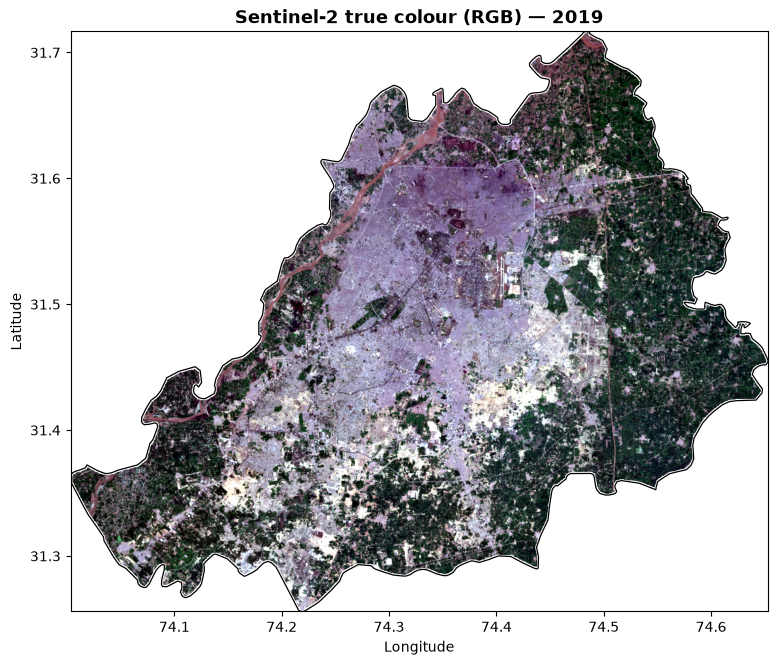

saved: E:\Punjab GeoGuardian\outputs\maps\01_RGB_2019.png


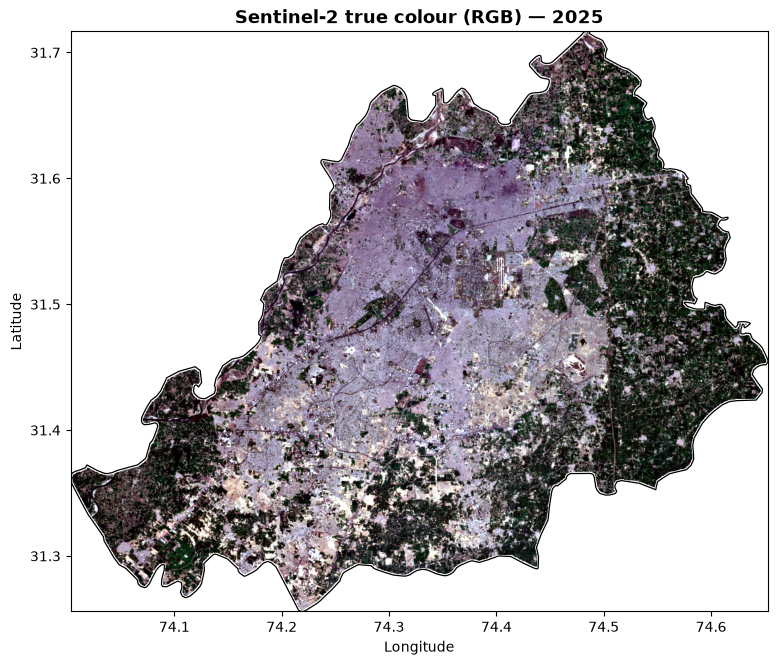

saved: E:\Punjab GeoGuardian\outputs\maps\02_RGB_2025.png


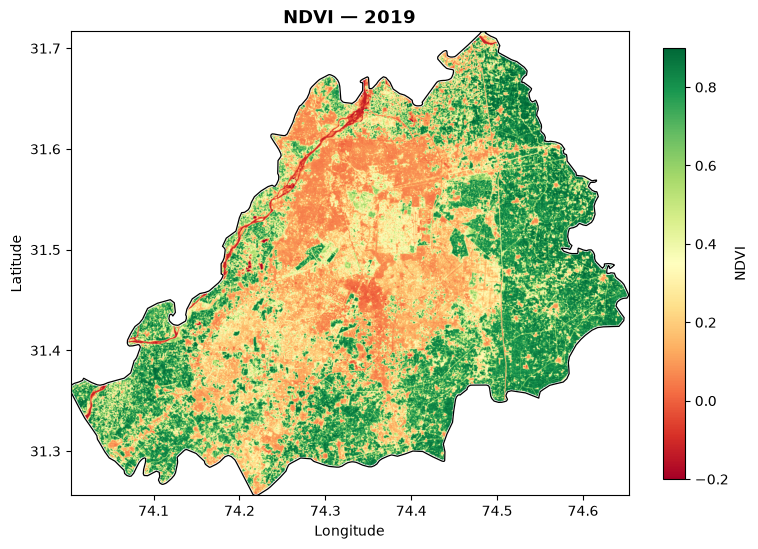

saved: E:\Punjab GeoGuardian\outputs\maps\03_NDVI_2019.png


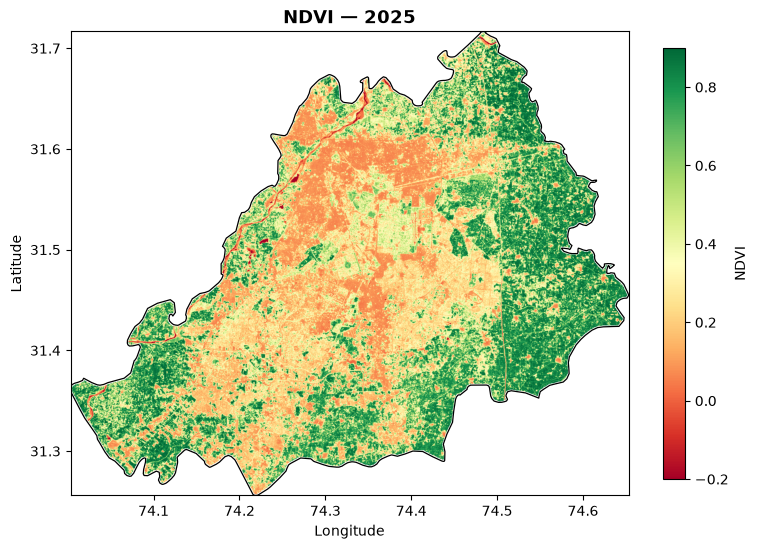

saved: E:\Punjab GeoGuardian\outputs\maps\04_NDVI_2025.png


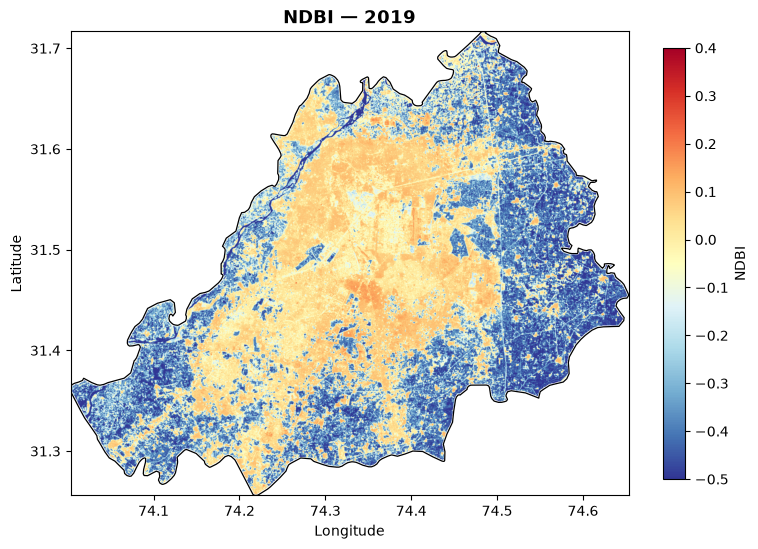

saved: E:\Punjab GeoGuardian\outputs\maps\05_NDBI_2019.png


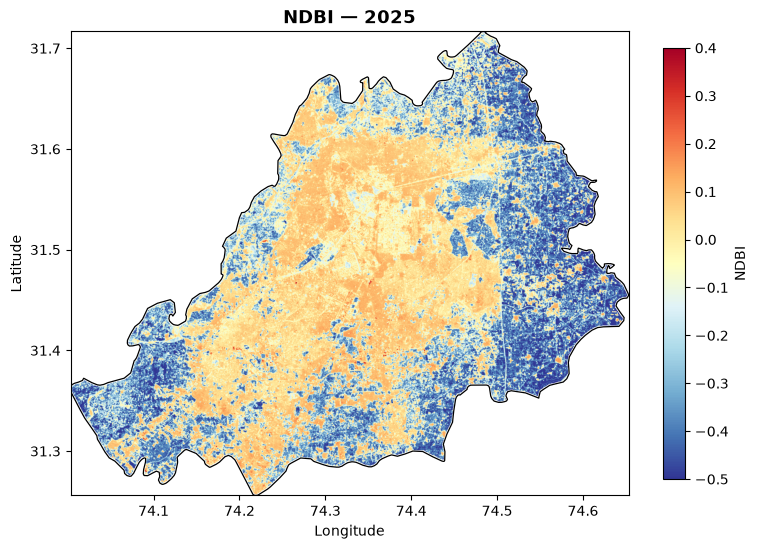

saved: E:\Punjab GeoGuardian\outputs\maps\06_NDBI_2025.png


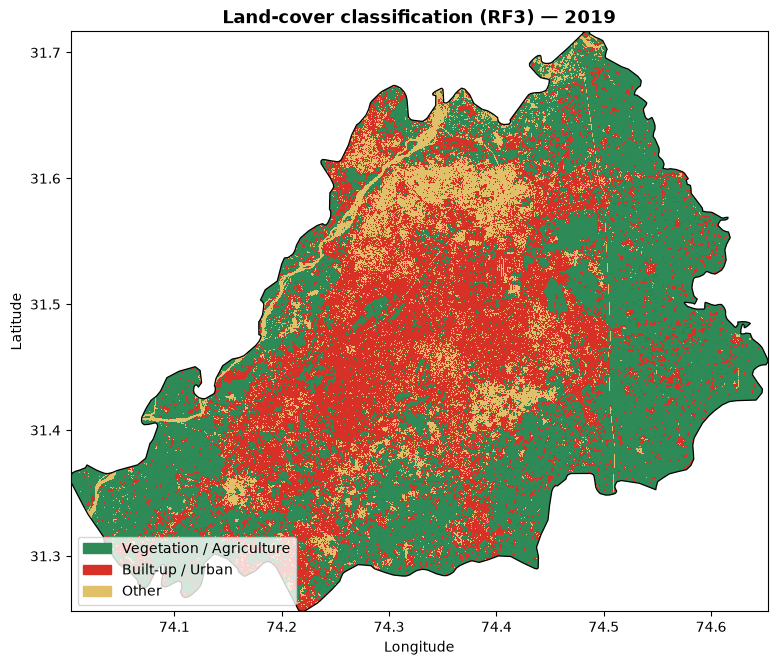

saved: E:\Punjab GeoGuardian\outputs\maps\07_Classification_RF3_2019.png


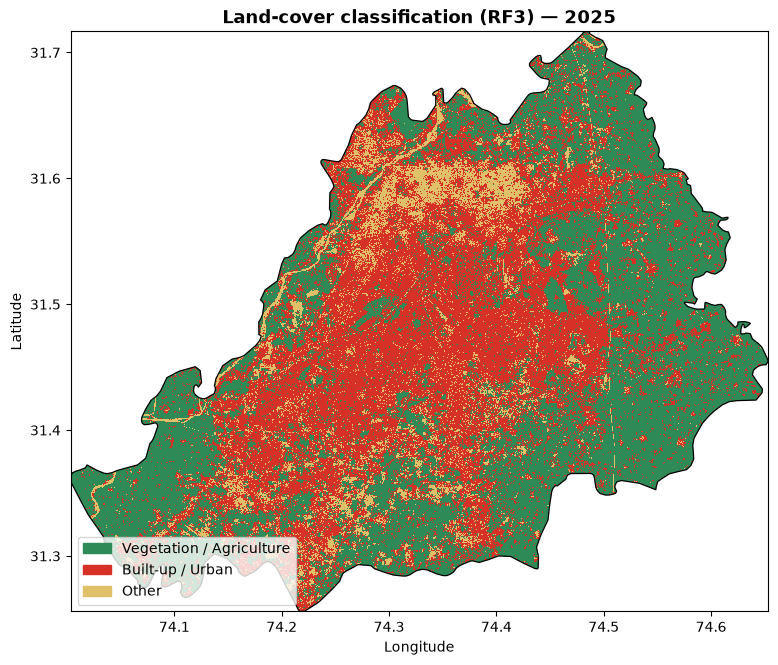

saved: E:\Punjab GeoGuardian\outputs\maps\08_Classification_RF3_2025.png


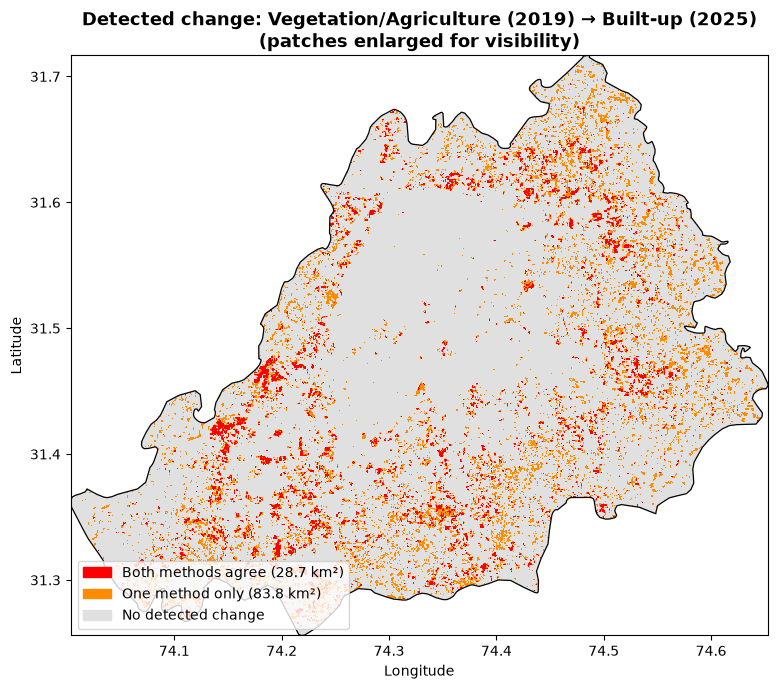

saved: E:\Punjab GeoGuardian\outputs\maps\09_Change_detection.png


In [6]:
# ======================================================================
# CELL 6 — Save the 9 required maps
# ======================================================================
from matplotlib.patches import Patch
from matplotlib.colors import to_rgb

inside_ov = read_overview(DIRS["masks"] / "lahore_mask.tif", [1], Resampling.nearest)[0] > 0
boundary_ll = gpd.read_file(BOUNDARY_PATH).to_crs("EPSG:4326")


def new_fig(title):
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    return fig, ax


def finish(fig, ax, fname):
    boundary_ll.boundary.plot(ax=ax, color="black", linewidth=0.9)
    ax.set_xlim(LEFT, RIGHT); ax.set_ylim(BOTTOM, TOP)
    fig.savefig(DIRS["maps"] / fname, dpi=200, bbox_inches="tight")
    plt.show()
    print("saved:", DIRS["maps"] / fname)


# --- 1-2: RGB, SAME stretch for both years so they are comparable ---
rgb = {y: np.moveaxis(read_overview(FEATS[y], [3, 2, 1]).astype("float32"), 0, -1) for y in YEARS}   # B4,B3,B2
pool = np.concatenate([rgb[y][inside_ov & np.isfinite(rgb[y]).all(-1)] for y in YEARS])
lo, hi = np.percentile(pool, [2, 98], axis=0)
for i, y in enumerate(YEARS, start=1):
    img = np.clip((rgb[y] - lo) / (hi - lo), 0, 1)
    img = np.nan_to_num(img, nan=1.0); img[~inside_ov] = 1.0
    fig, ax = new_fig(f"Sentinel-2 true colour (RGB) — {y}")
    ax.imshow(img, extent=EXTENT, origin="upper", aspect=ASPECT)
    finish(fig, ax, f"0{i}_RGB_{y}.png")
del rgb, pool

# --- 3-6: NDVI / NDBI, SAME colour scale for both years ---
for k, (idx, cmap, vmin, vmax) in enumerate([("NDVI", "RdYlGn", -0.2, 0.9), ("NDBI", "RdYlBu_r", -0.5, 0.4)]):
    for j, y in enumerate(YEARS):
        arr = read_overview(FEATS[y], [BAND_INDEX[idx]])[0].astype("float32")
        arr = np.ma.masked_where(~inside_ov | ~np.isfinite(arr), arr)
        cm_ = plt.get_cmap(cmap).copy(); cm_.set_bad("white")
        fig, ax = new_fig(f"{idx} — {y}")
        im = ax.imshow(arr, extent=EXTENT, origin="upper", aspect=ASPECT, cmap=cm_, vmin=vmin, vmax=vmax)
        fig.colorbar(im, ax=ax, shrink=0.7, label=idx)
        finish(fig, ax, f"0{3 + 2 * k + j}_{idx}_{y}.png")

# --- 7-8: classified maps (FINAL_METHOD) ---
lut = np.ones((256, 3))
for c, hexcol in CLASS3_COLORS.items():
    lut[c] = to_rgb(hexcol)
for j, y in enumerate(YEARS):
    cls = read_overview(DIRS["classifications"] / f"{FINAL_METHOD}_{y}.tif", [1], Resampling.nearest)[0]
    fig, ax = new_fig(f"Land-cover classification ({FINAL_METHOD}) — {y}")
    ax.imshow(lut[cls], extent=EXTENT, origin="upper", aspect=ASPECT, interpolation="nearest")
    ax.legend(handles=[Patch(color=CLASS3_COLORS[c], label=CLASS3[c]) for c in CLASS3], loc="lower left")
    finish(fig, ax, f"0{7 + j}_Classification_{FINAL_METHOD}_{y}.png")

# --- 9: change map ---
strata = read_arr(DIRS["change_detection"] / "change_strata_2019_2025.tif")
both = block_any(strata == 1)
single = block_any((strata == 2) | (strata == 3))
img = np.ones((OH, OW, 3))
img[inside_ov] = (0.88, 0.88, 0.88)
img[single] = to_rgb("#ff8c00")
img[both] = to_rgb("#ff0000")
img[~inside_ov & ~both & ~single] = 1.0
fig, ax = new_fig("Detected change: Vegetation/Agriculture (2019) → Built-up (2025)\n(patches enlarged for visibility)")
ax.imshow(img, extent=EXTENT, origin="upper", aspect=ASPECT, interpolation="nearest")
ax.legend(handles=[
    Patch(color="#ff0000", label=f"Both methods agree ({area_strata[1]:.1f} km²)"),
    Patch(color="#ff8c00", label=f"One method only ({area_strata[2] + area_strata[3]:.1f} km²)"),
    Patch(color="#e0e0e0", label="No detected change")], loc="lower left")
finish(fig, ax, "09_Change_detection.png")

In [7]:
# ======================================================================
# CELL 7 — Generate validation points
# ======================================================================
N_A_PER_CLASS = 12
N_B = {1: 12, 2: 8, 3: 8}        # strata: both / DW only / RF only
MIN_DIST_M = 300
OVERSAMPLE = 60
OVERWRITE = False                # keep False so you never destroy labels you have already typed
LABEL_CSV = DIRS["validation"] / "validation_points_TO_LABEL.csv"
PRED_CSV  = DIRS["validation"] / "validation_points_hidden_predictions.csv"

if LABEL_CSV.exists() and not OVERWRITE:
    print("validation_points_TO_LABEL.csv already exists -> NOT overwritten (your labels are safe).")
else:
    rng = np.random.default_rng(2026)
    P = {(m, y): read_arr(DIRS["classifications"] / f"{m}_{y}.tif") for m in ("DW3", "RF3") for y in YEARS}
    strata = read_arr(DIRS["change_detection"] / "change_strata_2019_2025.tif")
    train_idx = []
    for y in YEARS:
        p = DIRS["models"] / f"rf3_train_idx_{y}.npy"
        if p.exists():
            train_idx.append(np.load(p))
    train_idx = np.unique(np.concatenate(train_idx)) if train_idx else np.array([], dtype=np.int64)

    ok_all = inside.copy()
    for arr_ in P.values():
        ok_all &= arr_ < 3                       # all four classified maps must have a valid class here
    lat0 = np.radians((TOP + BOTTOM) / 2)
    taken_x, taken_y = [], []

    def pick(mask, n):
        cand = np.flatnonzero(mask)
        cand = cand[rng.choice(cand.size, min(cand.size, n * OVERSAMPLE * 3), replace=False)]
        cand = cand[~np.isin(cand, train_idx)][: n * OVERSAMPLE]
        r, c = np.divmod(cand, W)
        lon = TRANSFORM.c + TRANSFORM.a * (c + 0.5)
        lat = TRANSFORM.f + TRANSFORM.e * (r + 0.5)
        x, y = lon * 111320 * np.cos(lat0), lat * 110574
        chosen = []
        for i in range(cand.size):
            if taken_x and np.hypot(np.array(taken_x) - x[i], np.array(taken_y) - y[i]).min() < MIN_DIST_M:
                continue
            taken_x.append(x[i]); taken_y.append(y[i]); chosen.append(i)
            if len(chosen) == n:
                break
        if len(chosen) < n:
            print(f"  note: only {len(chosen)} of {n} points could be placed for this stratum")
        return cand[chosen], lon[chosen], lat[chosen]

    label_rows, pred_rows = [], []
    a_count = b_count = 0
    ref25 = P[("DW3", 2025)]
    for c in CLASS3:                                           # Set A
        idx, lon, lat = pick((ref25 == c) & ok_all, N_A_PER_CLASS)
        for k in range(idx.size):
            a_count += 1
            pid = f"A-{a_count:03d}"
            cid = f"{pid}-2025"
            label_rows.append({"Check_ID": cid, "Point_ID": pid, "Set": "A", "Year_to_check": 2025,
                               "Lon": round(lon[k], 6), "Lat": round(lat[k], 6),
                               "Actual_Code": "", "Notes": "", "Imagery_used": ""})
            pred_rows.append({"Check_ID": cid, "Stratum": f"A_{CLASS3_SHORT[c]}",
                              "DW3_pred": int(P[("DW3", 2025)].ravel()[idx[k]]),
                              "RF3_pred": int(P[("RF3", 2025)].ravel()[idx[k]])})
    for s, n in N_B.items():                                   # Set B (two dates per location)
        idx, lon, lat = pick((strata == s) & ok_all, n)
        for k in range(idx.size):
            b_count += 1
            pid = f"B-{b_count:03d}"
            for y in YEARS:
                cid = f"{pid}-{y}"
                label_rows.append({"Check_ID": cid, "Point_ID": pid, "Set": "B", "Year_to_check": y,
                                   "Lon": round(lon[k], 6), "Lat": round(lat[k], 6),
                                   "Actual_Code": "", "Notes": "", "Imagery_used": ""})
                pred_rows.append({"Check_ID": cid, "Stratum": f"B_{s}",
                                  "DW3_pred": int(P[("DW3", y)].ravel()[idx[k]]),
                                  "RF3_pred": int(P[("RF3", y)].ravel()[idx[k]])})
    pd.DataFrame(label_rows).to_csv(LABEL_CSV, index=False)
    pd.DataFrame(pred_rows).to_csv(PRED_CSV, index=False)
    print(f"Created {len(label_rows)} checks at {a_count + b_count} locations (A={a_count}, B={b_count}).")
    print("Edit:", LABEL_CSV)
    del P, strata, ok_all

display(pd.read_csv(LABEL_CSV).head(8))

Created 92 checks at 64 locations (A=36, B=28).
Edit: E:\Punjab GeoGuardian\outputs\validation\validation_points_TO_LABEL.csv


,Check_ID,Point_ID,Set,Year_to_check,Lon,Lat,Actual_Code,Notes,Imagery_used
0,A-001-2025,A-001,A,2025,74.307967,31.330677,NaN,NaN,NaN
1,A-002-2025,A-002,A,2025,74.581683,31.403081,NaN,NaN,NaN
2,A-003-2025,A-003,A,2025,74.479545,31.372179,NaN,NaN,NaN
3,A-004-2025,A-004,A,2025,74.135310,31.376491,NaN,NaN,NaN
4,A-005-2025,A-005,A,2025,74.504698,31.431288,NaN,NaN,NaN
5,A-006-2025,A-006,A,2025,74.531827,31.680840,NaN,NaN,NaN
6,A-007-2025,A-007,A,2025,74.476401,31.617329,NaN,NaN,NaN
7,A-008-2025,A-008,A,2025,74.523562,31.396434,NaN,NaN,NaN


In [8]:
# ======================================================================
# CELL 8 — Blind validation map (no predictions shown)
# ======================================================================
import folium
from folium.plugins import MousePosition

lab_df = pd.read_csv(LABEL_CSV)
pts = lab_df.drop_duplicates("Point_ID")

m = folium.Map(location=[pts.Lat.mean(), pts.Lon.mean()], zoom_start=11, tiles=None, control_scale=True)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap", show=False).add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Esri World Imagery (satellite)", max_zoom=19, show=True,
).add_to(m)
folium.GeoJson(str(BOUNDARY_PATH), name="Lahore district",
               style_function=lambda f: {"fill": False, "color": "cyan", "weight": 2}).add_to(m)

fg = {"A": folium.FeatureGroup(name="Set A (classification)"), "B": folium.FeatureGroup(name="Set B (change, 2 dates)")}
col = {"A": "#1f77b4", "B": "#ff7f0e"}
for _, r in pts.iterrows():
    years = "2025" if r.Set == "A" else "2019 AND 2025"
    gmaps = f"https://www.google.com/maps/@?api=1&map_action=map&center={r.Lat},{r.Lon}&zoom=19&basemap=satellite"
    popup = (f"<b>{r.Point_ID}</b> (Set {r.Set})<br>Judge on: <b>{years}</b><br>{r.Lat:.6f}, {r.Lon:.6f}<br>"
             f"<a href='{gmaps}' target='_blank'>Open in Google Maps (satellite)</a>")
    folium.CircleMarker([r.Lat, r.Lon], radius=6, color="white", weight=1, fill=True, fill_color=col[r.Set],
                        fill_opacity=0.9, tooltip=r.Point_ID, popup=folium.Popup(popup, max_width=260)).add_to(fg[r.Set])
    folium.Marker([r.Lat, r.Lon], icon=folium.DivIcon(
        html=f"<div style='font-size:10px;font-weight:bold;color:white;text-shadow:0 0 3px black;margin-left:9px;margin-top:-6px'>{r.Point_ID}</div>")
    ).add_to(fg[r.Set])
for g in fg.values():
    g.add_to(m)
MousePosition().add_to(m)
folium.LayerControl(collapsed=False).add_to(m)

html_path = DIRS["validation"] / "validation_points_map.html"
m.save(str(html_path))
print("Saved:", html_path, "  <- open this file in your browser for the best experience")
print("Labelled so far:", int(lab_df["Actual_Code"].notna().sum()), "/", len(lab_df))
display(m)

Saved: E:\Punjab GeoGuardian\outputs\validation\validation_points_map.html   <- open this file in your browser for the best experience
Labelled so far: 0 / 92


In [13]:
# ======================================================================
# CELL 9 (NO-LABEL VERSION) — unvalidated results, reported honestly
# ======================================================================
lower = area_strata[1]                         # both methods agree = conservative
upper = sum(area_strata.values())              # either method = upper bound
print("UNVALIDATED RESULT (no manual reference points)")
print(f"Possible Vegetation -> Built-up conversion, 2019-2025:")
print(f"  conservative (both methods agree): {lower:6.1f} km2  ({100*lower/aoi_km2:.2f}% of AOI)")
print(f"  upper bound (either method)      : {upper:6.1f} km2  ({100*upper/aoi_km2:.2f}% of AOI)")
print(f"\nFINAL_METHOD stays '{FINAL_METHOD}' (the project's own ML model); chosen without independent evidence.")
print("Cell 3's hold-out score is agreement with Dynamic World labels, NOT real-world accuracy.")

pd.DataFrame([
    {"Estimate": "Conservative (both methods agree)", "km2": round(lower, 2), "pct_of_AOI": round(100*lower/aoi_km2, 2)},
    {"Estimate": "Upper bound (either method)",       "km2": round(upper, 2), "pct_of_AOI": round(100*upper/aoi_km2, 2)},
]).to_csv(DIRS["report"] / "change_area_range_UNVALIDATED.csv", index=False)

UNVALIDATED RESULT (no manual reference points)
Possible Vegetation -> Built-up conversion, 2019-2025:
  conservative (both methods agree):   28.7 km2  (1.70% of AOI)
  upper bound (either method)      :  112.4 km2  (6.65% of AOI)

FINAL_METHOD stays 'RF3' (the project's own ML model); chosen without independent evidence.
Cell 3's hold-out score is agreement with Dynamic World labels, NOT real-world accuracy.


In [14]:
# ======================================================================
# CELL 10 — Error-analysis table from real validation results
# ======================================================================
ERR_CSV = DIRS["report"] / "error_analysis.csv"
if ERR_CSV.exists() and "FILL_ME" in ERR_CSV.read_text(encoding="utf-8", errors="ignore"):
    ERR_CSV.rename(DIRS["report"] / "error_analysis_OLD_placeholder.csv")
    print("Old placeholder error_analysis.csv renamed.")

d = load_validation().dropna(subset=["Actual"]).copy()
d["Actual"] = d["Actual"].astype(int)
other = "DW3" if FINAL_METHOD == "RF3" else "RF3"
d["wrong"] = d[f"{FINAL_METHOD}_pred"].astype(int) != d["Actual"]
d["disagree"] = d["DW3_pred"].astype(int) != d["RF3_pred"].astype(int)
weak = d[d.wrong | d.disagree].sort_values(["wrong", "disagree"], ascending=False).copy()

err = pd.DataFrame({
    "Case_ID": range(1, len(weak) + 1),
    "Check_ID": weak["Check_ID"].values,
    "Location (lat, lon)": [f"{a:.6f}, {b:.6f}" for a, b in zip(weak.Lat, weak.Lon)],
    "Year": weak["Year_to_check"].values,
    "Expected (what imagery shows)": weak["Actual"].map(CLASS3_SHORT).values,
    f"Model result ({FINAL_METHOD})": weak[f"{FINAL_METHOD}_pred"].astype(int).map(CLASS3_SHORT).values,
    f"Other method ({other})": weak[f"{other}_pred"].astype(int).map(CLASS3_SHORT).values,
    "Error type (auto)": np.where(weak.wrong,
        "Wrong class: " + weak["Actual"].map(CLASS3_SHORT).values + " mapped as " + weak[f"{FINAL_METHOD}_pred"].astype(int).map(CLASS3_SHORT).values,
        "Correct but methods disagree (weak)"),
    "Evidence_or_Notes": weak["Notes"].fillna("").values,
    "Likely_Reason": "",
    "Proposed_Improvement": "",
})
err.to_csv(ERR_CSV, index=False)
n_wrong = int(weak.wrong.sum())
print(f"Weak/incorrect cases found: {len(err)}  (strictly wrong: {n_wrong})  -> need >= 15")
if len(err) < 15:
    print("Not enough cases. Label more points (raise N_A_PER_CLASS / N_B in Cell 7, OVERWRITE=True ONLY if you have no labels yet).")
display(err.head(20))
print("\nSaved:", ERR_CSV, "\nOpen it in Excel and fill 'Likely_Reason' and 'Proposed_Improvement' for every row.")
print("""
REASON MENU (use only if the imagery supports it):
  - Dry/bare agricultural field looks like built-up (similar SWIR/NIR)
  - Fallow or harvested field in one year's composite (seasonal crop calendar)
  - Tree-covered housing / green society classified as vegetation
  - New road or earthwork seen as bare ground ('Other')
  - Small buildings/narrow roads lost in 10 m mixed pixels
  - Water body / wet soil / shadow confused with another class
  - Label noise in Dynamic World (the teacher was wrong)
  - 2019 and 2025 composites differ in season/cloud/haze
  - Point lies on a class boundary (mixed pixel)
IMPROVEMENT MENU:
  - Same-season composites for both years      - More + manually drawn training polygons
  - Add a Bare-ground/Water class               - Higher-resolution imagery for hotspots
  - Add SAR (Sentinel-1) or multi-year median   - Tune index thresholds / larger MMU
  - Validate against official housing-scheme boundaries
""")

Weak/incorrect cases found: 0  (strictly wrong: 0)  -> need >= 15
Not enough cases. Label more points (raise N_A_PER_CLASS / N_B in Cell 7, OVERWRITE=True ONLY if you have no labels yet).


,Case_ID,Check_ID,"Location (lat, lon)",Year,Expected (what imagery shows),Model result (RF3),Other method (DW3),Error type (auto),Evidence_or_Notes,Likely_Reason,Proposed_Improvement



Saved: E:\Punjab GeoGuardian\outputs\report\error_analysis.csv 
Open it in Excel and fill 'Likely_Reason' and 'Proposed_Improvement' for every row.

REASON MENU (use only if the imagery supports it):
  - Dry/bare agricultural field looks like built-up (similar SWIR/NIR)
  - Fallow or harvested field in one year's composite (seasonal crop calendar)
  - Tree-covered housing / green society classified as vegetation
  - New road or earthwork seen as bare ground ('Other')
  - Small buildings/narrow roads lost in 10 m mixed pixels
  - Water body / wet soil / shadow confused with another class
  - Label noise in Dynamic World (the teacher was wrong)
  - 2019 and 2025 composites differ in season/cloud/haze
  - Point lies on a class boundary (mixed pixel)
IMPROVEMENT MENU:
  - Same-season composites for both years      - More + manually drawn training polygons
  - Add a Bare-ground/Water class               - Higher-resolution imagery for hotspots
  - Add SAR (Sentinel-1) or multi-year median 

In [11]:
# ======================================================================
# CELL 11 — Folium map with layer toggles
# ======================================================================
import folium
from PIL import Image
from matplotlib.colors import to_rgb
from folium.plugins import MousePosition

LAYER_DIR = DIRS["interactive"] / "layers"
LAYER_DIR.mkdir(parents=True, exist_ok=True)
inside_ov = read_overview(DIRS["masks"] / "lahore_mask.tif", [1], Resampling.nearest)[0] > 0
bounds = [[BOTTOM, LEFT], [TOP, RIGHT]]


def save_rgba(arr_rgb01, alpha_mask, name):
    rgba = np.zeros((OH, OW, 4), np.uint8)
    rgba[..., :3] = (np.clip(arr_rgb01, 0, 1) * 255).astype(np.uint8)
    rgba[..., 3] = np.where(alpha_mask, 255, 0)
    p = LAYER_DIR / f"{name}.png"
    Image.fromarray(rgba, "RGBA").save(p)
    return str(p)


# RGB layers with a shared stretch
rgb = {y: np.moveaxis(read_overview(FEATS[y], [3, 2, 1]).astype("float32"), 0, -1) for y in YEARS}
pool = np.concatenate([rgb[y][inside_ov & np.isfinite(rgb[y]).all(-1)] for y in YEARS])
lo, hi = np.percentile(pool, [2, 98], axis=0)
png = {}
for y in YEARS:
    img = np.nan_to_num((rgb[y] - lo) / (hi - lo), nan=0.0)
    png[f"rgb{y}"] = save_rgba(img, inside_ov & np.isfinite(rgb[y]).all(-1), f"rgb_{y}")
del rgb, pool

# classification layers
lut = np.zeros((256, 3))
for c, hexcol in CLASS3_COLORS.items():
    lut[c] = to_rgb(hexcol)
for y in YEARS:
    cls = read_overview(DIRS["classifications"] / f"{FINAL_METHOD}_{y}.tif", [1], Resampling.nearest)[0]
    png[f"cls{y}"] = save_rgba(lut[cls], cls < 3, f"class_{FINAL_METHOD}_{y}")

# change layer
strata = read_arr(DIRS["change_detection"] / "change_strata_2019_2025.tif")
both, single = block_any(strata == 1), block_any((strata == 2) | (strata == 3))
img = np.zeros((OH, OW, 3)); img[single] = to_rgb("#ff8c00"); img[both] = to_rgb("#ff0000")
png["change"] = save_rgba(img, both | single, "change")

m = folium.Map(location=[(TOP + BOTTOM) / 2, (LEFT + RIGHT) / 2], zoom_start=10, tiles=None, control_scale=True)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap", show=False).add_to(m)
folium.TileLayer(tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                 attr="Esri, Maxar, Earthstar Geographics", name="Esri World Imagery", max_zoom=19, show=True).add_to(m)
for key, label, shown in [("rgb2019", "Sentinel-2 RGB 2019", False), ("rgb2025", "Sentinel-2 RGB 2025", False),
                          ("cls2019", f"Classification 2019 ({FINAL_METHOD})", False),
                          ("cls2025", f"Classification 2025 ({FINAL_METHOD})", False),
                          ("change", "Detected change Veg->Built-up (red = both methods, orange = one)", True)]:
    folium.raster_layers.ImageOverlay(image=png[key], bounds=bounds, opacity=0.85, name=label, show=shown).add_to(m)
folium.GeoJson(str(BOUNDARY_PATH), name="Lahore district",
               style_function=lambda f: {"fill": False, "color": "cyan", "weight": 2}).add_to(m)

# validation points (only if Cell 9 has been run)
if "done" in globals() and len(done):
    fgv = folium.FeatureGroup(name="Validation points (green = correct, red = wrong)", show=False)
    for _, r in done.iterrows():
        ok = int(r[f"{FINAL_METHOD}_pred"]) == int(r["Actual"])
        folium.CircleMarker([r.Lat, r.Lon], radius=4, color="green" if ok else "red", fill=True, fill_opacity=0.9,
                            popup=f"{r.Check_ID} | you saw {CLASS3_SHORT[int(r['Actual'])]}, map said {CLASS3_SHORT[int(r[f'{FINAL_METHOD}_pred'])]}").add_to(fgv)
    fgv.add_to(m)

legend = """<div style='position:fixed;bottom:25px;left:25px;z-index:9999;background:white;padding:8px 10px;
border:1px solid #888;font-size:12px;line-height:1.5'><b>Punjab GeoGuardian</b><br>
<span style='color:#2e8b57'>&#9632;</span> Vegetation / Agriculture<br><span style='color:#d73027'>&#9632;</span> Built-up / Urban<br>
<span style='color:#e0c068'>&#9632;</span> Other<br><span style='color:#ff0000'>&#9632;</span> Change (both methods)<br>
<span style='color:#ff8c00'>&#9632;</span> Change (one method)<br><i>Learning prototype — not an official product</i></div>"""
m.get_root().html.add_child(folium.Element(legend))
MousePosition().add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
html_path = DIRS["interactive"] / "GeoGuardian_interactive_map.html"
m.save(str(html_path))
print("Saved:", html_path, f"({html_path.stat().st_size / 1e6:.1f} MB)")
print("Open this HTML file in your browser (Chrome/Edge). Showing it inline in VS Code can be slow because of the size.")

Saved: E:\Punjab GeoGuardian\outputs\interactive\GeoGuardian_interactive_map.html (6.7 MB)
Open this HTML file in your browser (Chrome/Edge). Showing it inline in VS Code can be slow because of the size.


In [12]:
# ======================================================================
# CELL 12 — requirements.txt + change polygons (GeoJSON) + file checklist
# ======================================================================
from importlib.metadata import version, PackageNotFoundError

pkgs = ["numpy", "pandas", "matplotlib", "rasterio", "scikit-learn", "geopandas", "shapely", "pyproj",
        "scipy", "folium", "joblib", "pillow", "earthengine-api"]
lines = []
for p in pkgs:
    try:
        lines.append(f"{p}=={version(p)}")
    except PackageNotFoundError:
        pass
(PROJECT_DIR / "requirements.txt").write_text("\n".join(lines) + "\n")
print("requirements.txt written:\n" + "\n".join(lines))

EXPORT_POLYGONS = True
if EXPORT_POLYGONS:
    from rasterio.features import shapes
    from shapely.geometry import shape
    strata = read_arr(DIRS["change_detection"] / "change_strata_2019_2025.tif")
    recs = [{"stratum": STRATA_NAMES[int(v)], "geometry": shape(g)}
            for g, v in shapes(strata, mask=(strata >= 1) & (strata <= 3), transform=TRANSFORM, connectivity=8)]
    gdf = gpd.GeoDataFrame(recs, crs=CRS)
    gdf["area_ha"] = (gdf.to_crs("EPSG:32643").area / 1e4).round(3)
    p = DIRS["change_detection"] / "change_polygons.geojson"
    gdf.to_file(p, driver="GeoJSON")
    print(f"\n{len(gdf):,} change polygons ({gdf.area_ha.sum() / 100:.1f} km2) -> {p}")

print("\nDELIVERABLE CHECK")
need = {
    "9 maps (outputs/maps)": len(list(DIRS["maps"].glob("0*.png"))) >= 9,
    "Area statistics CSV": (DIRS["report"] / "area_statistics.csv").exists(),
    "Validation table (>=50)": (DIRS["report"] / "validation_table.csv").exists() and len(pd.read_csv(DIRS["report"] / "validation_table.csv")) >= 50,
    "Error analysis (>=15)": (DIRS["report"] / "error_analysis.csv").exists() and len(pd.read_csv(DIRS["report"] / "error_analysis.csv")) >= 15,
    "Interactive map": (DIRS["interactive"] / "GeoGuardian_interactive_map.html").exists(),
    "requirements.txt": (PROJECT_DIR / "requirements.txt").exists(),
}
for k, v in need.items():
    print(("[OK]      " if v else "[MISSING] ") + k)
print("Still manual: README.md, report PDF, GitHub upload, LinkedIn post, date-range/cloud-filter description of your GEE export.")

requirements.txt written:
numpy==2.5.4
pandas==3.0.6
matplotlib==3.11.2
rasterio==1.5.2
scikit-learn==1.9.1
geopandas==1.2.0
shapely==2.2.0
pyproj==3.8.0
scipy==1.18.1
folium==0.20.0
joblib==1.6.0
pillow==13.0.0
earthengine-api==1.7.48

35,488 change polygons (112.3 km2) -> E:\Punjab GeoGuardian\outputs\change_detection\change_polygons.geojson

DELIVERABLE CHECK
[OK]      9 maps (outputs/maps)
[OK]      Area statistics CSV
[MISSING] Validation table (>=50)
[MISSING] Error analysis (>=15)
[OK]      Interactive map
[OK]      requirements.txt
Still manual: README.md, report PDF, GitHub upload, LinkedIn post, date-range/cloud-filter description of your GEE export.


In [ ]:
"""
Punjab GeoGuardian - interactive web app (Lahore, 2019 vs 2025)

Run (from a terminal, inside your .venv):
    pip install streamlit streamlit-folium folium requests
    streamlit run geoguardian_app.py

How to use
  1. Search a place name / paste "lat, lon" / click the map / jump to a model-flagged hotspot.
  2. Two synchronised maps open (left = 2019, right = 2025, zoom up to level 22). Switch between
     dated high-resolution photos, the Sentinel-2 images the classifier used, and the class overlay.
  3. Read the change summary, the evidence check, and the 2019-vs-2025 percentage table.

The "prediction" was made earlier in your notebook (Random Forest and Dynamic World, 3 classes).
This app only looks those saved rasters up for the chosen window - it does not retrain anything.
"""
import math
import os
import re
from datetime import date
from pathlib import Path

import folium
import numpy as np
import pandas as pd
import rasterio
import requests
import streamlit as st
import streamlit.components.v1 as components
from folium.plugins import DualMap
from rasterio.windows import Window
from rasterio.windows import bounds as win_bounds
from streamlit_folium import st_folium

# ----------------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------------
PROJECT_DIR = Path(os.environ.get("GEOGUARDIAN_DIR", r"E:\Punjab GeoGuardian"))
OUT = PROJECT_DIR / "outputs"
RAW = PROJECT_DIR / "data" / "raw"
BOUNDARY_PATH = PROJECT_DIR / "data" / "boundaries" / "Lahore_District.geojson"
YEARS = (2019, 2025)

PATHS = {
    "RF3": {y: OUT / "classifications" / f"RF3_{y}.tif" for y in YEARS},
    "DW3": {y: OUT / "classifications" / f"DW3_{y}.tif" for y in YEARS},
    "feat": {y: RAW / f"Sentinel2_{y}_Features.tif" for y in YEARS},
    "change": OUT / "change_detection" / "change_strata_2019_2025.tif",
}
METHODS = {
    "Random Forest (this project's model)": "RF3",
    "Dynamic World (Google labels)": "DW3",
}

SHORT = {0: "Vegetation / Agriculture", 1: "Built-up / Urban", 2: "Other (bare, water, mixed)"}
COLORS = {0: "#2e8b57", 1: "#d73027", 2: "#e0c068"}
NODATA = 255
CONV = "Vegetation -> Built-up (predicted conversion)"
STAYV = "Stayed vegetation (control)"
STAYB = "Stayed built-up (control)"
VIEW_PHOTO = "High-res photo (dated)"
VIEW_S2 = "Sentinel-2 true colour (what the model saw)"
VIEW_CLASSES = "Land-cover classes (over the photo)"
MAX_ZOOM = 22

LEFT, BOTTOM, RIGHT, TOP = 74.0034, 31.2559, 74.6531, 31.7166   # only used to bias place search

ESRI_SAT = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
ESRI_LABELS = ("https://server.arcgisonline.com/ArcGIS/rest/services/Reference/"
               "World_Boundaries_and_Places/MapServer/tile/{z}/{y}/{x}")
ESRI_ATTR = "Esri, Maxar, Earthstar Geographics"
ESRI_GRAY = "https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
WAYBACK_CONFIG = "https://s3-us-west-2.amazonaws.com/config.maptiles.arcgis.com/waybackconfig.json"

TRANSITION_MEANING = {
    (0, 1): "Possible agriculture/vegetation -> urban conversion",
    (0, 2): "Vegetation -> bare/other (cleared land, fallow field, seasonal change)",
    (1, 0): "Built-up -> vegetation (rare in reality; usually classification noise)",
    (1, 2): "Built-up -> other (usually noise, or cleared/bare land)",
    (2, 0): "Other -> vegetation (crops on previously bare land, seasonal change)",
    (2, 1): "Other -> built-up (bare land that was developed)",
}


# ----------------------------------------------------------------------
# Location input helpers
# ----------------------------------------------------------------------
def parse_coords(text):
    """Accepts '31.4674, 74.1928' (lat, lon). Also fixes 'lon, lat' for Pakistan."""
    m = re.match(r"^\s*(-?\d+(?:\.\d+)?)\s*[,;\s]\s*(-?\d+(?:\.\d+)?)\s*$", text)
    if not m:
        return None
    a, b = float(m.group(1)), float(m.group(2))
    if 60 <= a <= 78 and 23 <= b <= 37:
        a, b = b, a
    if not (-90 <= a <= 90 and -180 <= b <= 180):
        return None
    return a, b


@st.cache_data(show_spinner=False, ttl=3600)
def geocode(query):
    """Place-name search through OpenStreetMap Nominatim (needs internet)."""
    params = {"q": query, "format": "jsonv2", "limit": 6, "countrycodes": "pk",
              "viewbox": f"{LEFT},{TOP},{RIGHT},{BOTTOM}", "bounded": 0}
    headers = {"User-Agent": "PunjabGeoGuardian-student-project/1.0"}
    r = requests.get("https://nominatim.openstreetmap.org/search", params=params, headers=headers, timeout=10)
    r.raise_for_status()
    return [(d["display_name"], float(d["lat"]), float(d["lon"])) for d in r.json()]


@st.cache_data(show_spinner=False, ttl=86400)
def wayback_releases():
    """Optional sharper dated imagery: list of (release_date, leaflet tile url) from Esri Wayback."""
    r = requests.get(WAYBACK_CONFIG, timeout=15)
    r.raise_for_status()
    out = []
    for val in r.json().values():
        if not isinstance(val, dict):
            continue
        m = re.search(r"(\d{4}-\d{2}-\d{2})", val.get("itemTitle", ""))
        url = val.get("itemURL", "")
        if m and url:
            url = url.replace("default028mm", "GoogleMapsCompatible").replace("{level}/{row}/{col}", "{z}/{y}/{x}")
            out.append((m.group(1), url))
    return sorted(set(out))


def nearest_release_index(options, year):
    target = date(year, 6, 30)
    gaps = [abs((date.fromisoformat(d) - target).days) for d in options]
    return gaps.index(min(gaps))


# ----------------------------------------------------------------------
# Raster analysis
# ----------------------------------------------------------------------
@st.cache_data(show_spinner="Reading satellite rasters...")
def analyze(lat, lon, radius_m, method):
    with rasterio.open(PATHS[method][2019]) as ref:
        r, c = ref.index(lon, lat)
        H, W = ref.height, ref.width
        res_x, res_y = ref.res
        tf = ref.transform
    if not (0 <= r < H and 0 <= c < W):
        raise ValueError("This location is outside the exported Lahore raster. "
                         "Pick a point inside the cyan Lahore boundary.")

    ny = res_y * 110574.0
    nx = res_x * 111320.0 * math.cos(math.radians(lat))
    px_km2 = ny * nx / 1e6
    hh, hw = max(2, int(radius_m / ny)), max(2, int(radius_m / nx))
    r0, r1 = max(0, r - hh), min(H, r + hh + 1)
    c0, c1 = max(0, c - hw), min(W, c + hw + 1)
    win = Window(c0, r0, c1 - c0, r1 - r0)

    def read(path, bands):
        with rasterio.open(path) as s:
            return s.read(bands, window=win)

    cls = {y: read(PATHS[method][y], 1) for y in YEARS}
    feat = {y: read(PATHS["feat"][y], [3, 2, 1, 7, 8]).astype("float32") for y in YEARS}  # R,G,B,NDVI,NDBI
    strata = read(PATHS["change"], 1)

    valid = (cls[2019] != NODATA) & (cls[2025] != NODATA)
    if not valid.any():
        raise ValueError("This window contains no Lahore pixels (outside the district boundary).")

    codes = cls[2019].astype(np.int16) * 3 + cls[2025].astype(np.int16)
    mat = np.bincount(codes[valid], minlength=9).reshape(3, 3) * px_km2     # rows=2019, cols=2025

    # ONE colour stretch for BOTH years, so differences you see are real, not display artefacts
    rgb_all = np.concatenate([feat[y][:3][:, valid].ravel() for y in YEARS])
    rgb_all = rgb_all[np.isfinite(rgb_all)]
    lo, hi = (float(v) for v in np.percentile(rgb_all, [2, 98])) if rgb_all.size else (0.02, 0.25)
    if hi <= lo:
        hi = lo + 0.01

    # evidence groups: do NDVI/NDBI behave the way real change should?
    f19, f25 = feat[2019], feat[2025]
    finite = np.isfinite(f19[3]) & np.isfinite(f25[3]) & np.isfinite(f19[4]) & np.isfinite(f25[4])

    def group(mask):
        m = mask & finite
        n = int(m.sum())
        if n == 0:
            return {"n": 0}
        return {"n": n, "km2": n * px_km2,
                "ndvi19": float(f19[3][m].mean()), "ndvi25": float(f25[3][m].mean()),
                "ndbi19": float(f19[4][m].mean()), "ndbi25": float(f25[4][m].mean())}

    groups = {
        CONV: group(valid & (cls[2019] == 0) & (cls[2025] == 1)),
        STAYV: group(valid & (cls[2019] == 0) & (cls[2025] == 0)),
        STAYB: group(valid & (cls[2019] == 1) & (cls[2025] == 1)),
    }
    cg = groups[CONV]
    vb_ndvi = (cg["ndvi25"] - cg["ndvi19"]) if cg["n"] else None
    vb_ndbi = (cg["ndbi25"] - cg["ndbi19"]) if cg["n"] else None

    return {
        "lat": lat, "lon": lon, "radius_m": radius_m, "method": method,
        "cls": cls, "feat": feat, "strata": strata, "valid": valid,
        "mat": mat, "px_km2": px_km2, "window_km2": float(valid.sum()) * px_km2,
        "bounds": win_bounds(win, tf),                       # left, bottom, right, top
        "stretch": (lo, hi), "groups": groups,
        "vb_dndvi": vb_ndvi, "vb_dndbi": vb_ndbi,
        "conf_km2": float(((strata >= 1) & (strata <= 3)).sum()) * px_km2,
        "conf_both_km2": float((strata == 1).sum()) * px_km2,
    }


@st.cache_data(show_spinner="Scanning the change layer for hotspots...")
def find_hotspots(top_n=10, cell_px=150):
    """Grid cells (~1.4 km) with the most area where BOTH methods say vegetation -> built-up."""
    with rasterio.open(PATHS["change"]) as s:
        arr, tf = s.read(1), s.transform
    H, W = arr.shape
    h2, w2 = H // cell_px * cell_px, W // cell_px * cell_px
    blocks = (arr[:h2, :w2] == 1).reshape(h2 // cell_px, cell_px, w2 // cell_px, cell_px).sum(axis=(1, 3))
    order = np.dstack(np.unravel_index(np.argsort(blocks, axis=None)[::-1], blocks.shape))[0]
    picked, out = [], []
    for i, j in order:
        if blocks[i, j] == 0 or len(out) >= top_n:
            break
        if any(max(abs(i - a), abs(j - b)) <= 1 for a, b in picked):
            continue
        picked.append((i, j))
        lon = tf.c + tf.a * (j * cell_px + cell_px / 2)
        lat = tf.f + tf.e * (i * cell_px + cell_px / 2)
        px = abs(tf.a) * 111320.0 * math.cos(math.radians(lat)) * abs(tf.e) * 110574.0 / 1e6
        out.append((float(lat), float(lon), float(blocks[i, j]) * px))
    return out


def evidence_check(res):
    """Do NDVI/NDBI on predicted-conversion pixels behave like real change? Returns (level, text)."""
    g = res["groups"]
    conv, sv = g[CONV], g[STAYV]
    if conv["n"] < 30:
        return "unknown", ("Fewer than 30 pixels are predicted as vegetation -> built-up in this window, so there "
                           "is too little to judge. Try a bigger radius or a model-flagged hotspot.")
    dn, db = conv["ndvi25"] - conv["ndvi19"], conv["ndbi25"] - conv["ndbi19"]
    if sv["n"] >= 30:
        dn0, db0 = sv["ndvi25"] - sv["ndvi19"], sv["ndbi25"] - sv["ndbi19"]
    else:
        dn0 = db0 = 0.0
    gap_n, gap_b = dn - dn0, db - db0
    detail = (f"On predicted-conversion pixels NDVI changed by {dn:+.2f} and NDBI by {db:+.2f}; on land that "
              f"stayed vegetation NDVI changed by {dn0:+.2f} and NDBI by {db0:+.2f} (that is the season/noise level).")
    if gap_n < -0.15 and gap_b > 0.05:
        return "strong", "Evidence is STRONG: greenness dropped and the built-up signal rose far more than seasonal noise. " + detail
    if gap_n < -0.08 and gap_b > 0.02:
        return "moderate", "Evidence is MODERATE: the direction is right but the size is not large. " + detail
    return "weak", ("Evidence is WEAK: the indices barely differ from normal seasonal noise, so a good part of the "
                    "predicted conversion here may be false. " + detail)


def groups_table(res):
    rows = []
    for name, g in res["groups"].items():
        if not g["n"]:
            rows.append({"Group": name, "Area (km2)": 0.0})
            continue
        rows.append({
            "Group": name, "Area (km2)": round(g["km2"], 3),
            "NDVI 2019": round(g["ndvi19"], 3), "NDVI 2025": round(g["ndvi25"], 3),
            "NDVI change": round(g["ndvi25"] - g["ndvi19"], 3),
            "NDBI 2019": round(g["ndbi19"], 3), "NDBI 2025": round(g["ndbi25"], 3),
            "NDBI change": round(g["ndbi25"] - g["ndbi19"], 3),
        })
    return pd.DataFrame(rows)


def category_table(res):
    mat, win = res["mat"], res["window_km2"]
    a19, a25 = mat.sum(axis=1), mat.sum(axis=0)
    rows = []
    for k in (0, 1, 2):
        d = a25[k] - a19[k]
        rows.append({
            "Category": SHORT[k],
            "2019 (km2)": round(a19[k], 3), "2025 (km2)": round(a25[k], 3), "Change (km2)": round(d, 3),
            "2019 (% of window)": round(100 * a19[k] / win, 1),
            "2025 (% of window)": round(100 * a25[k] / win, 1),
            "Change (pct points)": round(100 * d / win, 1),
        })
    return pd.DataFrame(rows)


def final_table(res_rf, res_dw):
    """2019 vs 2025 percentages for the selected area, both methods side by side."""
    rows = []
    for k in (0, 1, 2):
        row = {"Category": SHORT[k]}
        for tag, res in (("Random Forest", res_rf), ("Dynamic World", res_dw)):
            a19, a25 = res["mat"].sum(axis=1)[k], res["mat"].sum(axis=0)[k]
            w = res["window_km2"]
            row[f"{tag} 2019 (%)"] = round(100 * a19 / w, 1)
            row[f"{tag} 2025 (%)"] = round(100 * a25 / w, 1)
            row[f"{tag} change (pts)"] = round(100 * (a25 - a19) / w, 1)
        rows.append(row)
    return pd.DataFrame(rows)


def transition_table(res):
    mat, win = res["mat"], res["window_km2"]
    rows = []
    for a in (0, 1, 2):
        for b in (0, 1, 2):
            if a != b:
                rows.append({"From (2019)": SHORT[a], "To (2025)": SHORT[b],
                             "Area (km2)": round(mat[a, b], 3), "% of window": round(100 * mat[a, b] / win, 2),
                             "Meaning": TRANSITION_MEANING[(a, b)]})
    return pd.DataFrame(rows).sort_values("Area (km2)", ascending=False).reset_index(drop=True)


def summarize(res):
    mat, win = res["mat"], res["window_km2"]
    a19, a25 = mat.sum(axis=1), mat.sum(axis=0)
    pct = lambda x: 100 * x / win
    side = 2 * res["radius_m"] / 1000
    L = [f"Inside the selected window (about {side:.1f} km across, {win:.2f} km2 of Lahore), estimated land cover "
         f"changed from {pct(a19[0]):.0f}% vegetation / {pct(a19[1]):.0f}% built-up / {pct(a19[2]):.0f}% other in 2019 "
         f"to {pct(a25[0]):.0f}% / {pct(a25[1]):.0f}% / {pct(a25[2]):.0f}% in 2025."]

    def move(k, word):
        d = a25[k] - a19[k]
        return f"{word} {'rose' if d >= 0 else 'fell'} by {abs(d):.2f} km2 ({abs(pct(d)):.1f} points)"
    L.append("Net change: " + "; ".join([move(1, "built-up area"), move(0, "vegetation/agriculture"),
                                          move(2, "other land")]) + ".")

    off = sorted(((mat[a, b], a, b) for a in range(3) for b in range(3) if a != b and mat[a, b] >= 0.01), reverse=True)
    changed = mat.sum() - np.trace(mat)
    nm = lambda k: SHORT[k].split(" /")[0].split(" (")[0]
    if pct(changed) < 1:
        L.append("Very little change was detected here (under 1% of the window changed class).")
    elif off:
        L.append("Largest estimated shifts: " + "; ".join(
            f"{nm(a)} -> {nm(b)}: {v:.2f} km2 ({pct(v):.1f}%)" for v, a, b in off[:3]) + ".")

    vb = mat[0, 1]
    if vb >= 0.01:
        L.append(f"Possible agricultural-to-urban conversion: about {vb:.2f} km2 ({pct(vb):.1f}% of the window) "
                 f"was vegetation in 2019 and is classed built-up in 2025 (see the evidence check below).")
    else:
        L.append("No meaningful vegetation -> built-up conversion was detected in this window.")
    if vb > 0 and mat[1, 0] > 0.3 * vb:
        L.append(f"Caution: the maps also show {mat[1, 0]:.2f} km2 of built-up -> vegetation, which is rarely real over "
                 f"six years. It signals classification noise of a similar order, so treat the conversion figure as an upper estimate.")
    L.append(f"A stricter layer (NDVI must drop and NDBI must rise) flags {res['conf_km2']:.2f} km2 here, of which "
             f"{res['conf_both_km2']:.2f} km2 is agreed by both Random Forest and Dynamic World.")
    L.append("All figures are estimated/possible change from 10 m Sentinel-2 data and have not been field-verified.")
    return L


# ----------------------------------------------------------------------
# Map layers
# ----------------------------------------------------------------------
def _hex(h):
    return [int(h[i:i + 2], 16) for i in (1, 3, 5)]


def class_rgba(arr):
    out = np.zeros(arr.shape + (4,), np.uint8)
    for k, h in COLORS.items():
        m = arr == k
        out[m, :3] = _hex(h)
        out[m, 3] = 255
    return out


def rgb_rgba(feat, valid, stretch):
    lo, hi = stretch
    img = np.moveaxis(feat[:3], 0, -1)
    finite = np.isfinite(img).all(-1)
    img = np.clip((np.nan_to_num(img) - lo) / (hi - lo), 0, 1) ** 0.9
    out = np.zeros(img.shape[:2] + (4,), np.uint8)
    out[..., :3] = (img * 255).astype(np.uint8)
    out[..., 3] = np.where(valid & finite, 255, 0)
    return out


def change_rgba(strata):
    out = np.zeros(strata.shape + (4,), np.uint8)
    out[strata == 1] = [255, 0, 0, 255]
    out[(strata == 2) | (strata == 3)] = [255, 140, 0, 255]
    return out


def zoom_for(radius_m, lat):
    z = math.log2(156543.03 * math.cos(math.radians(lat)) * 500 / (2 * max(radius_m, 100)))
    return int(max(10, min(18, round(z))))


def build_dual(res, view, opacity, show_change, labels, label, photos, photo_dates, smooth):
    """Left map = 2019, right map = 2025. Zoom goes to level 22.

    photos: {year: tile url}  - high-resolution photo base layer for each map (dated Wayback or current Esri)
    """
    lat, lon = res["lat"], res["lon"]
    left, bottom, right, top = res["bounds"]
    bnds = [[bottom, left], [top, right]]
    dual = DualMap(location=[lat, lon], zoom_start=zoom_for(res["radius_m"], lat), tiles=None, layout="horizontal")
    for m, y in ((dual.m1, 2019), (dual.m2, 2025)):
        dated = photo_dates.get(y)
        folium.TileLayer(
            photos.get(y, ESRI_SAT), attr="Esri World Imagery" + (" Wayback" if dated else ""),
            max_zoom=MAX_ZOOM, max_native_zoom=18 if dated else 19, overlay=False,
            name=f"High-res photo ({dated})" if dated else "High-res photo (Esri, current)",
            show=(view != VIEW_S2)).add_to(m)
        folium.TileLayer(ESRI_GRAY, attr="Esri, HERE, Garmin", max_zoom=MAX_ZOOM, max_native_zoom=16,
                         name="Plain grey map (no photo)", overlay=False, show=(view == VIEW_S2)).add_to(m)
        folium.raster_layers.ImageOverlay(
            image=rgb_rgba(res["feat"][y], res["valid"], res["stretch"]), bounds=bnds, opacity=1.0,
            pixelated=not smooth, name=f"Sentinel-2 true colour {y} (10 m)",
            show=(view == VIEW_S2)).add_to(m)
        folium.raster_layers.ImageOverlay(
            image=class_rgba(res["cls"][y]), bounds=bnds, opacity=opacity, pixelated=True,
            name=f"Land-cover classes {y}", show=(view == VIEW_CLASSES)).add_to(m)
        if y == 2025:
            folium.raster_layers.ImageOverlay(
                image=change_rgba(res["strata"]), bounds=bnds, opacity=0.9, pixelated=True,
                name="Detected change (red = both methods)", show=show_change).add_to(m)
        if labels:
            folium.TileLayer(ESRI_LABELS, attr="Esri", max_zoom=MAX_ZOOM, max_native_zoom=19,
                             name="Place names", overlay=True, show=True).add_to(m)
        folium.CircleMarker([lat, lon], radius=6, color="white", weight=2, fill=True,
                            fill_color="#00e5ff", fill_opacity=1, tooltip=label).add_to(m)
        folium.LayerControl(collapsed=False).add_to(m)
    return dual


def build_pick_map(lat, lon, radius_m, labels):
    m = folium.Map(location=[lat, lon], zoom_start=12, tiles=None, control_scale=True)
    folium.TileLayer(ESRI_SAT, attr=ESRI_ATTR, name="Satellite", max_zoom=MAX_ZOOM, max_native_zoom=19).add_to(m)
    if labels:
        folium.TileLayer(ESRI_LABELS, attr="Esri", name="Place names", overlay=True,
                         max_zoom=MAX_ZOOM, max_native_zoom=19).add_to(m)
    if BOUNDARY_PATH.exists():
        folium.GeoJson(str(BOUNDARY_PATH), name="Lahore district",
                       style_function=lambda f: {"fill": False, "color": "cyan", "weight": 2}).add_to(m)
    dlat = radius_m / 110574.0
    dlon = radius_m / (111320.0 * math.cos(math.radians(lat)))
    folium.Rectangle([[lat - dlat, lon - dlon], [lat + dlat, lon + dlon]],
                     color="#ffeb3b", weight=2, fill=False, tooltip="Analysis window").add_to(m)
    folium.Marker([lat, lon], tooltip="Selected location").add_to(m)
    return m


# ----------------------------------------------------------------------
# Streamlit UI
# ----------------------------------------------------------------------
def main():
    st.set_page_config(page_title="Punjab GeoGuardian", layout="wide")
    ss = st.session_state
    ss.setdefault("loc", (31.4674, 74.1928))
    ss.setdefault("label", "Hotspot H1 (default)")
    ss.setdefault("last_click", None)
    ss.setdefault("cands", [])
    ss.setdefault("hot", [])

    st.title("Punjab GeoGuardian - Lahore land-change explorer (2019 vs 2025)")
    st.caption("Learning prototype, not an official monitoring system. Results are estimated/possible "
               "change from Sentinel-2 and are not field-verified.")

    # ---------------- sidebar ----------------
    with st.sidebar:
        st.header("Find a location")
        with st.form("search_form"):
            q = st.text_input("Place name or coordinates",
                              placeholder="DHA Phase 9 Prism, Lahore   or   31.4674, 74.1928")
            go = st.form_submit_button("Search")
        if go and q.strip():
            coords = parse_coords(q)
            if coords:
                ss.loc, ss.label, ss.cands = coords, f"{coords[0]:.5f}, {coords[1]:.5f}", []
            else:
                try:
                    found = geocode(q.strip())
                except Exception as e:  # noqa: BLE001
                    found = []
                    st.error(f"Place search failed (internet needed): {e}")
                if found:
                    ss.cands = found
                    ss.cand_idx = 0
                    ss.loc, ss.label = (found[0][1], found[0][2]), found[0][0].split(",")[0]
                elif not ss.cands:
                    st.warning("No match found. Try adding ', Lahore' or paste coordinates.")

        def _use_candidate():
            name, la, lo = ss.cands[ss.cand_idx]
            ss.loc, ss.label = (la, lo), name.split(",")[0]

        if len(ss.cands) > 1:
            st.selectbox("Other matches", list(range(len(ss.cands))),
                         format_func=lambda i: ss.cands[i][0][:70], key="cand_idx", on_change=_use_candidate)

        with st.expander("Jump to a model-flagged hotspot"):
            st.caption("Places where BOTH Random Forest and Dynamic World say vegetation became built-up. "
                       "Good places to test whether the prediction is real.")
            if st.button("Find top hotspots"):
                try:
                    ss.hot = find_hotspots()
                except Exception as e:  # noqa: BLE001
                    st.error(f"Could not scan the change layer: {e}")

            def _use_hot():
                la, lo, _ = ss.hot[ss.hot_idx]
                ss.loc, ss.label, ss.cands = (la, lo), f"Hotspot #{ss.hot_idx + 1}", []

            if ss.hot:
                st.selectbox("Hotspots", list(range(len(ss.hot))), key="hot_idx", on_change=_use_hot,
                             format_func=lambda i: f"#{i + 1}: {ss.hot[i][0]:.4f}, {ss.hot[i][1]:.4f} "
                                                   f"({ss.hot[i][2]:.2f} km2 changed)")

        # Esri Wayback list (dated high-resolution photos) - fetched once per session
        if "rel" not in ss:
            try:
                ss.rel, ss.wb_err = wayback_releases(), ""
            except Exception as e:  # noqa: BLE001
                ss.rel, ss.wb_err = [], str(e)
        wb_ok = bool(ss.rel)

        st.header("Settings")
        radius = st.slider("Analysis window radius (m)", 500, 6000, 1500, step=250)
        method_label = st.radio("Classification source", list(METHODS))
        method = METHODS[method_label]
        view = st.radio("What to show on both maps", [VIEW_PHOTO, VIEW_S2, VIEW_CLASSES],
                        index=0 if wb_ok else 1)
        opacity = st.slider("Class overlay opacity", 0.2, 1.0, 0.6, step=0.05)
        smooth = st.checkbox("Smooth Sentinel-2 pixels (nicer when zoomed in)", value=True)
        show_change = st.checkbox("Highlight detected change on the 2025 map", value=False)
        labels = st.checkbox("Show place names", value=True)
        map_h = st.slider("Map height (px)", 500, 1000, 720, step=20)

        photos, photo_dates = {y: ESRI_SAT for y in YEARS}, {}
        with st.expander("High-res photo dates (Esri Wayback)", expanded=not wb_ok):
            if wb_ok:
                lookup = dict(ss.rel)
                for y in YEARS:
                    opts = [d for d, _ in ss.rel if d.startswith(str(y))] or [d for d, _ in ss.rel]
                    sel = st.selectbox(f"{y} photo release", opts, index=nearest_release_index(opts, y), key=f"wb{y}")
                    photos[y], photo_dates[y] = lookup[sel], sel
                st.caption("A release date is when Esri published the mosaic, not the day the photo was taken, and "
                           "spots with no new photo look the same across releases.")
            else:
                st.warning("Could not load dated photos (internet needed), so both maps fall back to Esri's current "
                           "photo, which is identical for 2019 and 2025. Use the Sentinel-2 view instead. "
                           f"{ss.get('wb_err', '')}")
                if st.button("Retry loading dated photos"):
                    del ss["rel"]
                    st.rerun()
        st.caption("You can also click directly on the first map to choose a location.")

    # ---------------- 1. pick map ----------------
    lat, lon = ss.loc
    st.subheader("1. Choose a location")
    st.write(f"**Selected:** {ss.label}  |  {lat:.5f}, {lon:.5f}  |  yellow box = analysis window")
    pick = build_pick_map(lat, lon, radius, labels)
    try:
        out = st_folium(pick, height=400, use_container_width=True, returned_objects=["last_clicked"], key="pick_map")
    except TypeError:
        out = st_folium(pick, height=400, returned_objects=["last_clicked"], key="pick_map")
    click = out.get("last_clicked") if out else None
    if click and click != ss.last_click:
        ss.last_click = click
        ss.loc, ss.label, ss.cands = (click["lat"], click["lng"]), "Clicked point", []
        st.rerun()

    # ---------------- analysis ----------------
    try:
        res = analyze(round(lat, 6), round(lon, 6), radius, method)
        res_rf = res if method == "RF3" else analyze(round(lat, 6), round(lon, 6), radius, "RF3")
        res_dw = res if method == "DW3" else analyze(round(lat, 6), round(lon, 6), radius, "DW3")
    except FileNotFoundError as e:
        st.error(f"A raster file was not found: {e}\n\nCheck the PATHS block at the top of this file.")
        st.stop()
    except ValueError as e:
        st.warning(str(e))
        st.stop()

    # ---------------- 2. maps ----------------
    st.subheader("2. 2019 vs 2025 (maps pan and zoom together, zoom up to level 22)")
    c1, c2 = st.columns(2)
    c1.markdown("### 2019")
    c2.markdown("### 2025")
    dual = build_dual(res, view, opacity, show_change, labels, ss.label, photos, photo_dates, smooth)
    map_html = dual.get_root().render()
    if hasattr(st, "iframe"):
        st.iframe(map_html, height=map_h)
    else:
        components.html(map_html, height=map_h)
    st.markdown(
        " &nbsp; ".join(f"<span style='display:inline-block;width:14px;height:14px;background:{COLORS[k]};"
                        f"border-radius:3px;vertical-align:middle'></span> {SHORT[k]}" for k in (0, 1, 2))
        + " &nbsp; <span style='display:inline-block;width:14px;height:14px;background:#ff0000;"
          "border-radius:3px;vertical-align:middle'></span> Detected change (both methods)",
        unsafe_allow_html=True)
    st.link_button("Open this spot in Google Maps (satellite)",
                   f"https://www.google.com/maps/@?api=1&map_action=map&center={lat},{lon}&zoom=18&basemap=satellite")
    st.caption("Quality guide: the high-res photo (about 0.3-0.6 m per pixel) stays sharp to zoom 18-19 and is "
               "enlarged beyond that. Sentinel-2 is 10 m per pixel, which is the real resolution the classifier "
               "used, so it can never look sharper than a coarse mosaic. Use the photo view to judge what is on the "
               "ground and the Sentinel-2 view to see what the model saw. Use each map's layer panel to switch layers.")

    # ---------------- 3. what changed ----------------
    st.subheader("3. What changed between 2019 and 2025")
    m1, m2, m3 = st.columns(3)
    m1.metric("Window area", f"{res['window_km2']:.2f} km2")
    m2.metric("Vegetation -> Built-up", f"{res['mat'][0, 1]:.2f} km2",
              f"{100 * res['mat'][0, 1] / res['window_km2']:.1f}% of window", delta_color="inverse")
    net_b = res["mat"].sum(axis=0)[1] - res["mat"].sum(axis=1)[1]
    m3.metric("Net built-up change", f"{net_b:+.2f} km2")
    for line in summarize(res):
        st.markdown(f"- {line}")

    st.markdown("**Which categories changed into which (2019 -> 2025)**")
    trans = transition_table(res)
    st.dataframe(trans, width="stretch", hide_index=True)
    st.download_button("Download change table (CSV)", trans.to_csv(index=False).encode("utf-8"),
                       file_name="geoguardian_change_table.csv", mime="text/csv")

    # ---------------- 4. is the prediction right? ----------------
    st.subheader("4. Is the prediction right? (evidence check)")
    level, text = evidence_check(res)
    {"strong": st.success, "moderate": st.info, "weak": st.warning, "unknown": st.info}[level](text)
    st.dataframe(groups_table(res), width="stretch", hide_index=True)
    st.caption("How to read this: real conversion = NDVI falls and NDBI rises on those pixels by clearly more than on "
               "the 'stayed vegetation' control. This test uses the same indices the classifier saw, so it is a "
               "plausibility check, not ground truth. The final proof is visual: compare the two Sentinel-2 maps, "
               "then check sharper imagery (Google Earth Pro > View > Historical Imagery).")

    # ---------------- 5. final percentage table ----------------
    st.subheader("5. Summary table for the selected area: 2019 vs 2025")
    st.write(f"**Area:** {ss.label} | window about {2 * radius / 1000:.1f} km across "
             f"({res['window_km2']:.2f} km2 inside Lahore district)")
    ft = final_table(res_rf, res_dw)
    st.dataframe(ft, width="stretch", hide_index=True)
    sel = res
    a19, a25 = sel["mat"].sum(axis=1), sel["mat"].sum(axis=0)
    w = sel["window_km2"]
    st.success(f"{method_label.split(' (')[0]}: in 2019 this area was {100 * a19[1] / w:.1f}% built-up and "
               f"{100 * a19[0] / w:.1f}% vegetation/agriculture. In 2025 it is {100 * a25[1] / w:.1f}% built-up and "
               f"{100 * a25[0] / w:.1f}% vegetation/agriculture.")
    st.download_button("Download summary table (CSV)", ft.to_csv(index=False).encode("utf-8"),
                       file_name="geoguardian_summary_table.csv", mime="text/csv")
    st.caption("Random Forest is trained on Dynamic World labels, so their agreement is not independent accuracy. "
               "Percentages are of the pixels inside the Lahore district within the window.")


if __name__ == "__main__":
    main()
